# 🫁 Multimodal Lung Cancer Diagnostic System
## End-to-End PyTorch Training Pipeline

**Architecture Overview:**
1. **Vision Branch** — UNet (ResNet34 encoder) trained on LIDC-IDRI CT scans for segmentation + severity classification
2. **NLP Branch** — Bio_ClinicalBERT fine-tuned on doctor-patient conversations for severity classification
3. **Fusion Engine** — Cross-Modal Attention fusing both latent spaces for final 3-class severity prediction

**Target Hardware:** Google Colab T4 GPU (16 GB VRAM)

---

## ⚙️ Block 0 — Configuration & Constants
All hyperparameters and paths in one place for easy tuning.

In [ ]:
# ============================================================
# CONFIGURATION — Edit these before running
# ============================================================
import os

class CFG:
    # ----- General -----
    SEED              = 42
    DEVICE            = None          # auto-detected below
    RESULTS_DIR       = '/content/results'
    DRIVE_RESULTS_DIR = '/content/drive/MyDrive/lung_cancer_results'
    CSV_PATH          = '/content/doctor-patient-conversation.csv'

    # ----- Vision -----
    IMG_SIZE          = 256
    VISION_BATCH      = 8
    VISION_LR         = 1e-4
    VISION_EPOCHS     = 5
    VISION_LATENT_DIM = 512       # ResNet34 bottleneck channels
    NUM_SEG_CLASSES   = 1         # binary segmentation mask
    NUM_SEVERITY      = 3         # 0=Normal, 1=Mild, 2=Severe

    # ----- NLP -----
    MAX_TOKEN_LEN     = 256
    NLP_BATCH         = 16
    NLP_LR            = 2e-5
    NLP_EPOCHS        = 3
    BERT_DIM          = 768

    # ----- Fusion -----
    FUSION_PROJ_DIM   = 512
    FUSION_BATCH      = 8
    FUSION_LR         = 3e-4
    FUSION_EPOCHS     = 5
    NUM_ATTN_HEADS    = 8

os.makedirs(CFG.RESULTS_DIR, exist_ok=True)
print('✅ Config ready')

✅ Config ready


## 📦 Block 1 — Installations & Imports

In [ ]:
%%capture install_log
!pip install -q segmentation-models-pytorch datasets transformers accelerate
!pip install -q monai nibabel pydicom scikit-learn matplotlib seaborn
print('Packages installed.')

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split
from torch.cuda.amp import autocast, GradScaler

import segmentation_models_pytorch as smp
from transformers import AutoTokenizer, AutoModel
from datasets import load_dataset

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score, f1_score
)
from PIL import Image
from collections import defaultdict
import json, time, random, copy, gc, shutil, warnings, re
from pathlib import Path
from IPython.display import display, HTML

warnings.filterwarnings('ignore')

# ----- Reproducibility -----
def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(CFG.SEED)

# ----- Device -----
CFG.DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'🖥️  Device : {CFG.DEVICE}')
if CFG.DEVICE.type == 'cuda':
    print(f'   GPU    : {torch.cuda.get_device_name(0)}')
    print(f'   VRAM   : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')

🖥️  Device : cuda
   GPU    : Tesla T4
   VRAM   : 15.6 GB


## 💾 Block 2 — Mount Google Drive & Resume Utility

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
os.makedirs(CFG.DRIVE_RESULTS_DIR, exist_ok=True)
print(f'📂 Drive results dir: {CFG.DRIVE_RESULTS_DIR}')

Mounted at /content/drive
📂 Drive results dir: /content/drive/MyDrive/lung_cancer_results


In [ ]:
# ============================================================
# CHECKPOINT / RESUME UTILITIES
# ============================================================
def save_checkpoint(state, filename, save_to_drive=True):
    """Save checkpoint locally and optionally mirror to Drive."""
    local_path = os.path.join(CFG.RESULTS_DIR, filename)
    torch.save(state, local_path)
    if save_to_drive:
        drive_path = os.path.join(CFG.DRIVE_RESULTS_DIR, filename)
        shutil.copy2(local_path, drive_path)
    print(f'   💾 Checkpoint saved → {filename}')


def load_checkpoint(filename, map_location=None):
    """Try loading from Drive first, then local."""
    drive_path = os.path.join(CFG.DRIVE_RESULTS_DIR, filename)
    local_path = os.path.join(CFG.RESULTS_DIR, filename)
    for p in [drive_path, local_path]:
        if os.path.exists(p):
            print(f'   ♻️  Resuming from {p}')
            return torch.load(p, map_location=map_location or CFG.DEVICE)
    return None


def save_results_json(data, filename):
    """Save a dict as JSON locally + Drive."""
    local_path = os.path.join(CFG.RESULTS_DIR, filename)
    with open(local_path, 'w') as f:
        json.dump(data, f, indent=2)
    drive_path = os.path.join(CFG.DRIVE_RESULTS_DIR, filename)
    shutil.copy2(local_path, drive_path)
    print(f'   📊 Results saved → {filename}')

print('✅ Checkpoint utilities ready')

✅ Checkpoint utilities ready


## 📈 Block 3 — Shared Visualization Helpers

In [ ]:
# ============================================================
# VISUALIZATION HELPERS (reused across all stages)
# ============================================================
SEVERITY_NAMES = ['Normal', 'Mild', 'Severe']

def plot_training_curves(history, title, save_name):
    """Plot loss and metric curves, save figure."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    # Loss
    axes[0].plot(history['train_loss'], 'o-', label='Train Loss')
    if 'val_loss' in history:
        axes[0].plot(history['val_loss'], 's-', label='Val Loss')
    axes[0].set_title(f'{title} — Loss'); axes[0].set_xlabel('Epoch')
    axes[0].legend(); axes[0].grid(True, alpha=0.3)
    # Metric (accuracy or dice)
    metric_keys = [k for k in history if 'acc' in k or 'dice' in k or 'f1' in k]
    for k in metric_keys:
        axes[1].plot(history[k], 'o-', label=k)
    axes[1].set_title(f'{title} — Metrics'); axes[1].set_xlabel('Epoch')
    axes[1].legend(); axes[1].grid(True, alpha=0.3)
    plt.tight_layout()
    path = os.path.join(CFG.RESULTS_DIR, save_name)
    fig.savefig(path, dpi=150, bbox_inches='tight')
    shutil.copy2(path, os.path.join(CFG.DRIVE_RESULTS_DIR, save_name))
    plt.show()


def plot_confusion(y_true, y_pred, title, save_name):
    """Plot and save a confusion matrix."""
    cm = confusion_matrix(y_true, y_pred, labels=[0,1,2])
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=SEVERITY_NAMES, yticklabels=SEVERITY_NAMES, ax=ax)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    ax.set_title(title)
    plt.tight_layout()
    path = os.path.join(CFG.RESULTS_DIR, save_name)
    fig.savefig(path, dpi=150, bbox_inches='tight')
    shutil.copy2(path, os.path.join(CFG.DRIVE_RESULTS_DIR, save_name))
    plt.show()


def print_classification(y_true, y_pred, title):
    """Print sklearn classification report."""
    print(f'\n{"="*60}')
    print(f' {title}')
    print(f'{"="*60}')
    print(classification_report(y_true, y_pred,
          target_names=SEVERITY_NAMES, zero_division=0))

print('✅ Visualization helpers ready')

✅ Visualization helpers ready


---
# 🔬 STAGE 1 — Vision Pipeline (UNet + ResNet34)
---

### 1.1 Load & Explore LIDC-IDRI Dataset

In [ ]:
# ============================================================
# LOAD VISION DATASET FROM HUGGING FACE
# ============================================================
print('⏳ Loading LIDC-IDRI dataset from Hugging Face (this may take a few minutes)...')
hf_dataset = load_dataset('jmanuelc87/lidc-idri-segmentation', split='train')
print(f'✅ Loaded {len(hf_dataset)} samples')
print(f'   Columns: {hf_dataset.column_names}')
print(f'   First sample keys: {hf_dataset[0].keys()}')

⏳ Loading LIDC-IDRI dataset from Hugging Face (this may take a few minutes)...


README.md:   0%|          | 0.00/470 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/459M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/2651 [00:00<?, ? examples/s]

✅ Loaded 2651 samples
   Columns: ['image', 'image_mask', 'patch', 'patch_mask', 'malignancy', 'cancer']
   First sample keys: dict_keys(['image', 'image_mask', 'patch', 'patch_mask', 'malignancy', 'cancer'])


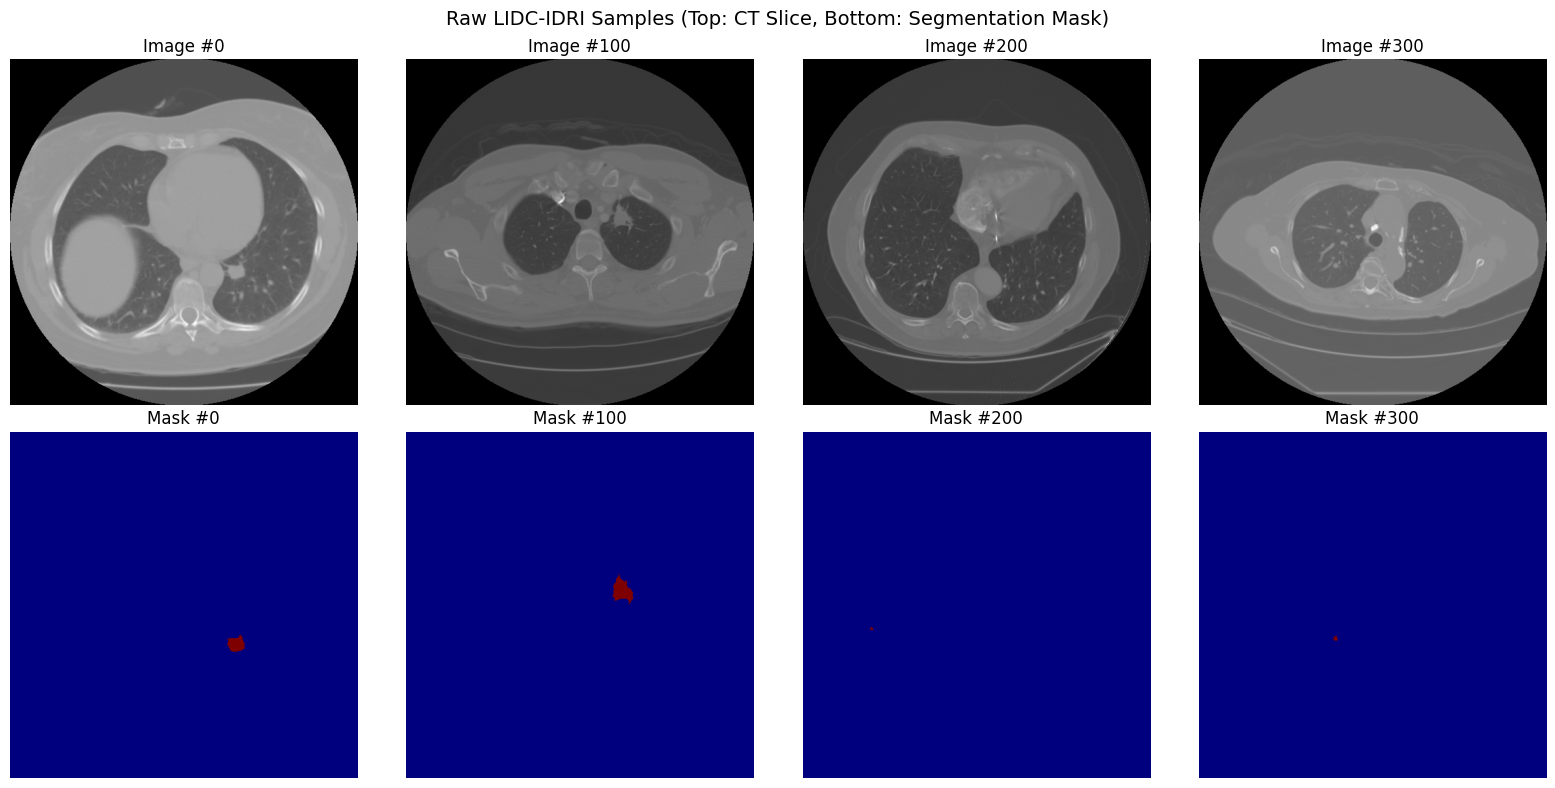

In [ ]:
# ============================================================
# VISUALIZE RAW SAMPLES (FIXED)
# ============================================================
# Dataset keys: ['image', 'image_mask', 'patch', 'patch_mask', 'malignancy', 'cancer']
# We use 'image' for the CT slice and 'image_mask' for the segmentation mask.

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for i in range(4):
    idx = i * 100
    sample = hf_dataset[idx]
    img = sample['image']               # CT slice
    mask = sample['image_mask']         # <--- CORRECT KEY: image_mask

    # Convert to NumPy arrays (works if PIL or numpy already)
    img_np = np.array(img)
    mask_np = np.array(mask)

    axes[0, i].imshow(img_np, cmap='gray')
    axes[0, i].set_title(f'Image #{idx}')
    axes[0, i].axis('off')

    axes[1, i].imshow(mask_np, cmap='jet')
    axes[1, i].set_title(f'Mask #{idx}')
    axes[1, i].axis('off')

plt.suptitle('Raw LIDC-IDRI Samples (Top: CT Slice, Bottom: Segmentation Mask)', fontsize=14)
plt.tight_layout()
save_path = os.path.join(CFG.RESULTS_DIR, 'vision_raw_samples.png')
fig.savefig(save_path, dpi=150)
shutil.copy2(save_path, os.path.join(CFG.DRIVE_RESULTS_DIR, 'vision_raw_samples.png'))
plt.show()

### 1.2 Vision Dataset with Pseudo-Labels

In [ ]:
# ============================================================
# VISION DATASET — Use malignancy score for pseudo-labels
# ============================================================
class LIDCSegDataset(Dataset):
    """
    Wraps the HF LIDC-IDRI dataset.
    - Resizes image & image_mask to IMG_SIZE x IMG_SIZE
    - Generates severity pseudo-label from malignancy score:
        0 = Normal   (malignancy 1 or 2)
        1 = Mild     (malignancy 3)
        2 = Severe   (malignancy 4 or 5)
    """
    def __init__(self, hf_data, img_size=256):
        self.data = hf_data
        self.img_size = img_size

    def __len__(self):
        return len(self.data)

    def _severity_from_malignancy(self, mal):
        """Convert malignancy 1-5 to 3-class severity."""
        if mal <= 2:
            return 0   # Normal
        elif mal == 3:
            return 1   # Mild
        else:           # 4 or 5
            return 2   # Severe

    def __getitem__(self, idx):
        sample = self.data[idx]
        # Load image and mask as PIL, resize
        img_pil = sample['image'].convert('L')            # grayscale image
        mask_pil = sample['image_mask'].convert('L')      # <--- CORRECT KEY

        img_pil = img_pil.resize((self.img_size, self.img_size), Image.BILINEAR)
        mask_pil = mask_pil.resize((self.img_size, self.img_size), Image.NEAREST)

        img_np = np.array(img_pil, dtype=np.float32) / 255.0
        mask_np = np.array(mask_pil, dtype=np.float32)
        mask_np = (mask_np > 0).astype(np.float32)        # binarize

        # Use malignancy score for pseudo-label
        malignancy_score = sample['malignancy']          # integer 1-5
        severity = self._severity_from_malignancy(malignancy_score)

        # Tensor shapes: image [1, H, W], mask [1, H, W]
        img_t  = torch.from_numpy(img_np).unsqueeze(0)
        mask_t = torch.from_numpy(mask_np).unsqueeze(0)
        sev_t  = torch.tensor(severity, dtype=torch.long)

        return img_t, mask_t, sev_t


# Build dataset
vision_full = LIDCSegDataset(hf_dataset, img_size=CFG.IMG_SIZE)
print(f'✅ Vision dataset: {len(vision_full)} samples')

# Quick label distribution check
label_counts = [0, 0, 0]
for i in range(min(500, len(vision_full))):
    _, _, s = vision_full[i]
    label_counts[s.item()] += 1
print(f'   Label distribution (first 500): Normal={label_counts[0]}, Mild={label_counts[1]}, Severe={label_counts[2]}')

✅ Vision dataset: 2651 samples
   Label distribution (first 500): Normal=132, Mild=222, Severe=146


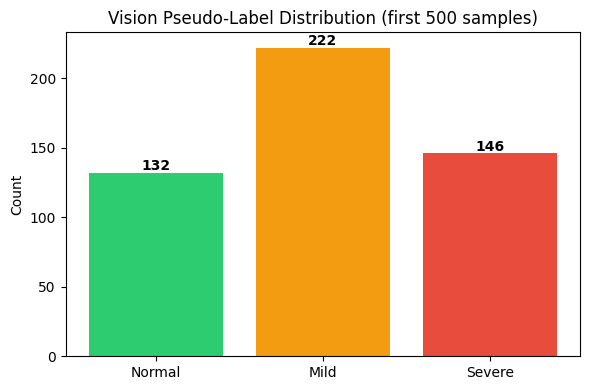

In [ ]:
# ============================================================
# VISUALIZE PSEUDO-LABEL DISTRIBUTION
# ============================================================
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(SEVERITY_NAMES, label_counts, color=['#2ecc71', '#f39c12', '#e74c3c'])
ax.set_title('Vision Pseudo-Label Distribution (first 500 samples)')
ax.set_ylabel('Count')
for i, v in enumerate(label_counts):
    ax.text(i, v + 2, str(v), ha='center', fontweight='bold')
plt.tight_layout()
save_path = os.path.join(CFG.RESULTS_DIR, 'vision_label_dist.png')
fig.savefig(save_path, dpi=150); shutil.copy2(save_path, os.path.join(CFG.DRIVE_RESULTS_DIR, 'vision_label_dist.png'))
plt.show()

In [ ]:
# ============================================================
# TRAIN / VAL SPLIT
# ============================================================
n_total = len(vision_full)
n_val   = int(0.15 * n_total)
n_train = n_total - n_val

vision_train, vision_val = random_split(
    vision_full, [n_train, n_val],
    generator=torch.Generator().manual_seed(CFG.SEED)
)

vision_train_loader = DataLoader(vision_train, batch_size=CFG.VISION_BATCH,
                                  shuffle=True, num_workers=2, pin_memory=True)
vision_val_loader   = DataLoader(vision_val, batch_size=CFG.VISION_BATCH,
                                  shuffle=False, num_workers=2, pin_memory=True)

print(f'✅ Vision split: train={n_train}, val={n_val}')

# Sanity check one batch
imgs, masks, sevs = next(iter(vision_train_loader))
print(f'   Batch shapes → img: {imgs.shape}, mask: {masks.shape}, severity: {sevs.shape}')

✅ Vision split: train=2254, val=397
   Batch shapes → img: torch.Size([8, 1, 256, 256]), mask: torch.Size([8, 1, 256, 256]), severity: torch.Size([8])


### 1.3 Vision Model — Modified UNet with Latent Extraction

In [ ]:
# ============================================================
# VISION MODEL — UNet + ResNet34 + Severity Head
# ============================================================
class VisionUNet(nn.Module):
    """
    Modified UNet using segmentation-models-pytorch.
    Returns:
        mask_logits : (B, 1, H, W)  — segmentation prediction
        severity    : (B, 3)        — severity classification logits
        latent      : (B, 512)      — bottleneck vector for fusion
    """
    def __init__(self, num_severity=3):
        super().__init__()
        # Full UNet with ResNet34 encoder
        self.unet = smp.Unet(
            encoder_name='resnet34',
            encoder_weights='imagenet',
            in_channels=1,            # grayscale input
            classes=1,                # binary segmentation
        )

        # Adaptive pool to extract a fixed-size bottleneck vector
        self.global_pool = nn.AdaptiveAvgPool2d(1)

        # Severity classification head from 512-d bottleneck
        self.severity_head = nn.Sequential(
            nn.Linear(512, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(256, num_severity)
        )

    def forward(self, x):
        # x: (B, 1, 256, 256)

        # --- Encoder forward ---
        features = self.unet.encoder(x)
        # features is a list: [stem, stage1, stage2, stage3, stage4]
        # stage4 (bottleneck) has shape (B, 512, 8, 8) for 256 input

        # --- Bottleneck latent vector ---
        bottleneck = features[-1]                     # (B, 512, 8, 8)
        latent = self.global_pool(bottleneck)         # (B, 512, 1, 1)
        latent = latent.flatten(1)                    # (B, 512)

        # --- Decoder + segmentation head ---
        # FIX: pass features as a single list, do NOT unpack with *
        decoder_out = self.unet.decoder(features)     # (B, 16, 256, 256)  <-- removed '*'
        mask_logits = self.unet.segmentation_head(decoder_out)  # (B, 1, 256, 256)

        # --- Severity classification ---
        severity_logits = self.severity_head(latent)  # (B, 3)

        return mask_logits, severity_logits, latent


# Instantiate & verify
vision_model = VisionUNet(num_severity=CFG.NUM_SEVERITY).to(CFG.DEVICE)
with torch.no_grad():
    dummy = torch.randn(2, 1, CFG.IMG_SIZE, CFG.IMG_SIZE).to(CFG.DEVICE)
    m, s, l = vision_model(dummy)
    print(f'✅ VisionUNet verified:')
    print(f'   mask_logits : {m.shape}')    # (2, 1, 256, 256)
    print(f'   severity    : {s.shape}')    # (2, 3)
    print(f'   latent      : {l.shape}')    # (2, 512)

total_params = sum(p.numel() for p in vision_model.parameters())
train_params = sum(p.numel() for p in vision_model.parameters() if p.requires_grad)
print(f'   Total params: {total_params:,}  |  Trainable: {train_params:,}')

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/87.3M [00:00<?, ?B/s]

✅ VisionUNet verified:
   mask_logits : torch.Size([2, 1, 256, 256])
   severity    : torch.Size([2, 3])
   latent      : torch.Size([2, 512])
   Total params: 24,562,196  |  Trainable: 24,562,196


### 1.4 Vision Loss Functions

In [ ]:
# ============================================================
# DICE LOSS for segmentation
# ============================================================
class DiceLoss(nn.Module):
    def __init__(self, smooth=1e-6):
        super().__init__()
        self.smooth = smooth

    def forward(self, logits, targets):
        # logits: (B, 1, H, W),  targets: (B, 1, H, W)
        probs = torch.sigmoid(logits)
        probs_flat = probs.view(probs.size(0), -1)
        targets_flat = targets.view(targets.size(0), -1)

        intersection = (probs_flat * targets_flat).sum(dim=1)
        union = probs_flat.sum(dim=1) + targets_flat.sum(dim=1)
        dice = (2.0 * intersection + self.smooth) / (union + self.smooth)
        return 1.0 - dice.mean()


def compute_dice_score(logits, targets):
    """Metric: mean Dice score (detached)."""
    with torch.no_grad():
        probs = (torch.sigmoid(logits) > 0.5).float()
        p = probs.view(probs.size(0), -1)
        t = targets.view(targets.size(0), -1)
        inter = (p * t).sum(dim=1)
        union = p.sum(dim=1) + t.sum(dim=1)
        dice = (2.0 * inter + 1e-6) / (union + 1e-6)
    return dice.mean().item()

dice_loss_fn = DiceLoss()
# Initialize CrossEntropyLoss with calculated class weights
ce_loss_fn   = nn.CrossEntropyLoss(weight=CFG.CLASS_WEIGHTS.to(CFG.DEVICE))
print('✅ Loss functions ready')

✅ Loss functions ready


### 1.5 Vision Training Loop (with Resume)

In [ ]:
# ============================================================
# VISION TRAINING LOOP
# ============================================================
optimizer_v = torch.optim.AdamW(vision_model.parameters(), lr=CFG.VISION_LR, weight_decay=1e-4)
scheduler_v = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_v, T_max=CFG.VISION_EPOCHS)
scaler_v    = GradScaler()

# ---- Resume logic ----
start_epoch_v = 0
vision_history = {'train_loss': [], 'val_loss': [], 'val_dice': [], 'val_sev_acc': []}
ckpt = load_checkpoint('vision_checkpoint.pt')
if ckpt is not None:
    vision_model.load_state_dict(ckpt['model_state'])
    optimizer_v.load_state_dict(ckpt['optimizer_state'])
    scheduler_v.load_state_dict(ckpt['scheduler_state'])
    start_epoch_v = ckpt['epoch'] + 1
    vision_history = ckpt['history']
    print(f'   Resuming vision training from epoch {start_epoch_v}')
else:
    print('   Starting vision training from scratch')

best_val_dice = max(vision_history['val_dice']) if vision_history['val_dice'] else 0.0

print(f'\n{"="*60}')
print(f'  VISION TRAINING — Epochs {start_epoch_v} to {CFG.VISION_EPOCHS-1}')
print(f'{"="*60}\n')

for epoch in range(start_epoch_v, CFG.VISION_EPOCHS):
    t0 = time.time()

    # ===================== TRAIN =====================
    vision_model.train()
    running_loss = 0.0
    n_batches = 0

    for batch_idx, (imgs, masks, sevs) in enumerate(vision_train_loader):
        imgs  = imgs.to(CFG.DEVICE)    # (B, 1, 256, 256)
        masks = masks.to(CFG.DEVICE)   # (B, 1, 256, 256)
        sevs  = sevs.to(CFG.DEVICE)    # (B,)

        optimizer_v.zero_grad()

        with autocast():
            mask_logits, sev_logits, _ = vision_model(imgs)
            # Combined loss: Dice (segmentation) + CE (severity)
            loss_dice = dice_loss_fn(mask_logits, masks)
            loss_ce   = ce_loss_fn(sev_logits, sevs)
            loss = loss_dice + 0.5 * loss_ce    # weighted sum

        scaler_v.scale(loss).backward()
        scaler_v.step(optimizer_v)
        scaler_v.update()

        running_loss += loss.item()
        n_batches += 1

        if batch_idx % 50 == 0:
            print(f'   Epoch {epoch} | Batch {batch_idx:>4d} | '
                  f'Loss: {loss.item():.4f} (dice={loss_dice.item():.4f}, ce={loss_ce.item():.4f})')

    avg_train_loss = running_loss / max(n_batches, 1)
    scheduler_v.step()

    # ===================== VALIDATE =====================
    vision_model.eval()
    val_loss_sum = 0.0
    val_dice_sum = 0.0
    all_sev_preds, all_sev_true = [], []
    n_val_batches = 0

    with torch.no_grad():
        for imgs, masks, sevs in vision_val_loader:
            imgs  = imgs.to(CFG.DEVICE)
            masks = masks.to(CFG.DEVICE)
            sevs  = sevs.to(CFG.DEVICE)

            with autocast():
                mask_logits, sev_logits, _ = vision_model(imgs)
                loss_dice = dice_loss_fn(mask_logits, masks)
                loss_ce   = ce_loss_fn(sev_logits, sevs)
                loss = loss_dice + 0.5 * loss_ce

            val_loss_sum += loss.item()
            val_dice_sum += compute_dice_score(mask_logits, masks)
            preds = sev_logits.argmax(dim=1).cpu().numpy()
            all_sev_preds.extend(preds)
            all_sev_true.extend(sevs.cpu().numpy())
            n_val_batches += 1

    avg_val_loss = val_loss_sum / max(n_val_batches, 1)
    avg_val_dice = val_dice_sum / max(n_val_batches, 1)
    val_sev_acc  = accuracy_score(all_sev_true, all_sev_preds)

    # Record history
    vision_history['train_loss'].append(avg_train_loss)
    vision_history['val_loss'].append(avg_val_loss)
    vision_history['val_dice'].append(avg_val_dice)
    vision_history['val_sev_acc'].append(val_sev_acc)

    elapsed = time.time() - t0
    print(f'\n   📊 Epoch {epoch} [{elapsed:.0f}s]: '
          f'Train Loss={avg_train_loss:.4f} | Val Loss={avg_val_loss:.4f} | '
          f'Val Dice={avg_val_dice:.4f} | Val Sev Acc={val_sev_acc:.4f}\n')

    # ---- Save checkpoint every epoch ----
    save_checkpoint({
        'epoch': epoch,
        'model_state': vision_model.state_dict(),
        'optimizer_state': optimizer_v.state_dict(),
        'scheduler_state': scheduler_v.state_dict(),
        'history': vision_history,
    }, 'vision_checkpoint.pt')

    # ---- Save best model ----
    if avg_val_dice > best_val_dice:
        best_val_dice = avg_val_dice
        save_checkpoint({'model_state': vision_model.state_dict()}, 'vision_best.pt')
        print(f'   ⭐ New best Dice: {best_val_dice:.4f}')

print('\n✅ Vision training complete!')

   Starting vision training from scratch

  VISION TRAINING — Epochs 0 to 4

   Epoch 0 | Batch    0 | Loss: 1.6599 (dice=0.9984, ce=1.3229)
   Epoch 0 | Batch   50 | Loss: 1.6039 (dice=0.9993, ce=1.2093)
   Epoch 0 | Batch  100 | Loss: 1.5819 (dice=0.9986, ce=1.1665)
   Epoch 0 | Batch  150 | Loss: 1.5841 (dice=0.9987, ce=1.1707)
   Epoch 0 | Batch  200 | Loss: 1.5230 (dice=0.9976, ce=1.0507)
   Epoch 0 | Batch  250 | Loss: 1.5254 (dice=0.9937, ce=1.0632)

   📊 Epoch 0 [41s]: Train Loss=1.5248 | Val Loss=1.5305 | Val Dice=0.0092 | Val Sev Acc=0.4332

   💾 Checkpoint saved → vision_checkpoint.pt
   💾 Checkpoint saved → vision_best.pt
   ⭐ New best Dice: 0.0092
   Epoch 1 | Batch    0 | Loss: 1.6072 (dice=0.9941, ce=1.2262)
   Epoch 1 | Batch   50 | Loss: 1.4263 (dice=0.9953, ce=0.8619)
   Epoch 1 | Batch  100 | Loss: 1.6089 (dice=0.9974, ce=1.2230)
   Epoch 1 | Batch  150 | Loss: 1.4932 (dice=0.9984, ce=0.9897)
   Epoch 1 | Batch  200 | Loss: 1.5346 (dice=0.9913, ce=1.0865)
   Epoch 1 

### 1.6 Vision Validation — Curves, Confusion Matrix, Segmentation Overlay

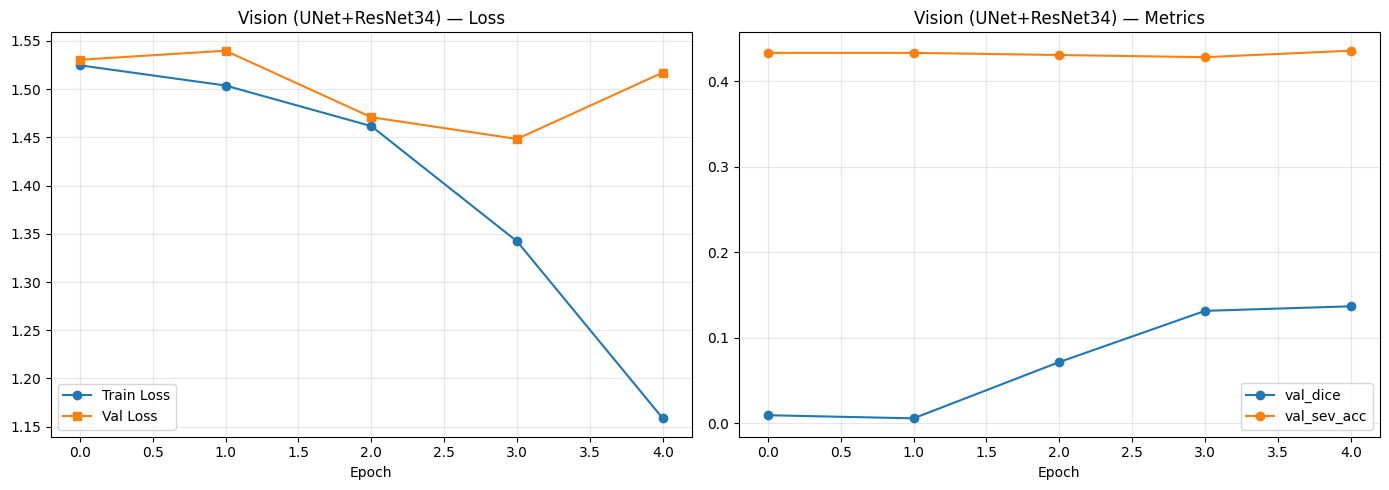

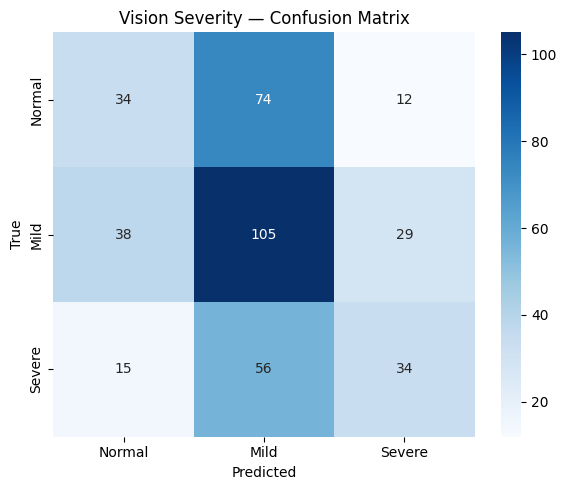


 Vision Severity Classification
              precision    recall  f1-score   support

      Normal       0.39      0.28      0.33       120
        Mild       0.45      0.61      0.52       172
      Severe       0.45      0.32      0.38       105

    accuracy                           0.44       397
   macro avg       0.43      0.41      0.41       397
weighted avg       0.43      0.44      0.42       397



In [ ]:
# ============================================================
# VISION VALIDATION VISUALS (FIXED)
# ============================================================
# Training curves
plot_training_curves(vision_history, 'Vision (UNet+ResNet34)', 'vision_curves.png')

# Confusion matrix for severity
plot_confusion(all_sev_true, all_sev_preds,
               'Vision Severity — Confusion Matrix', 'vision_severity_cm.png')

# Print classification report with explicit labels to handle missing classes
print(f'\n{"="*60}')
print(f' Vision Severity Classification')
print(f'{"="*60}')
print(classification_report(all_sev_true, all_sev_preds,
      target_names=SEVERITY_NAMES, labels=[0,1,2], zero_division=0))

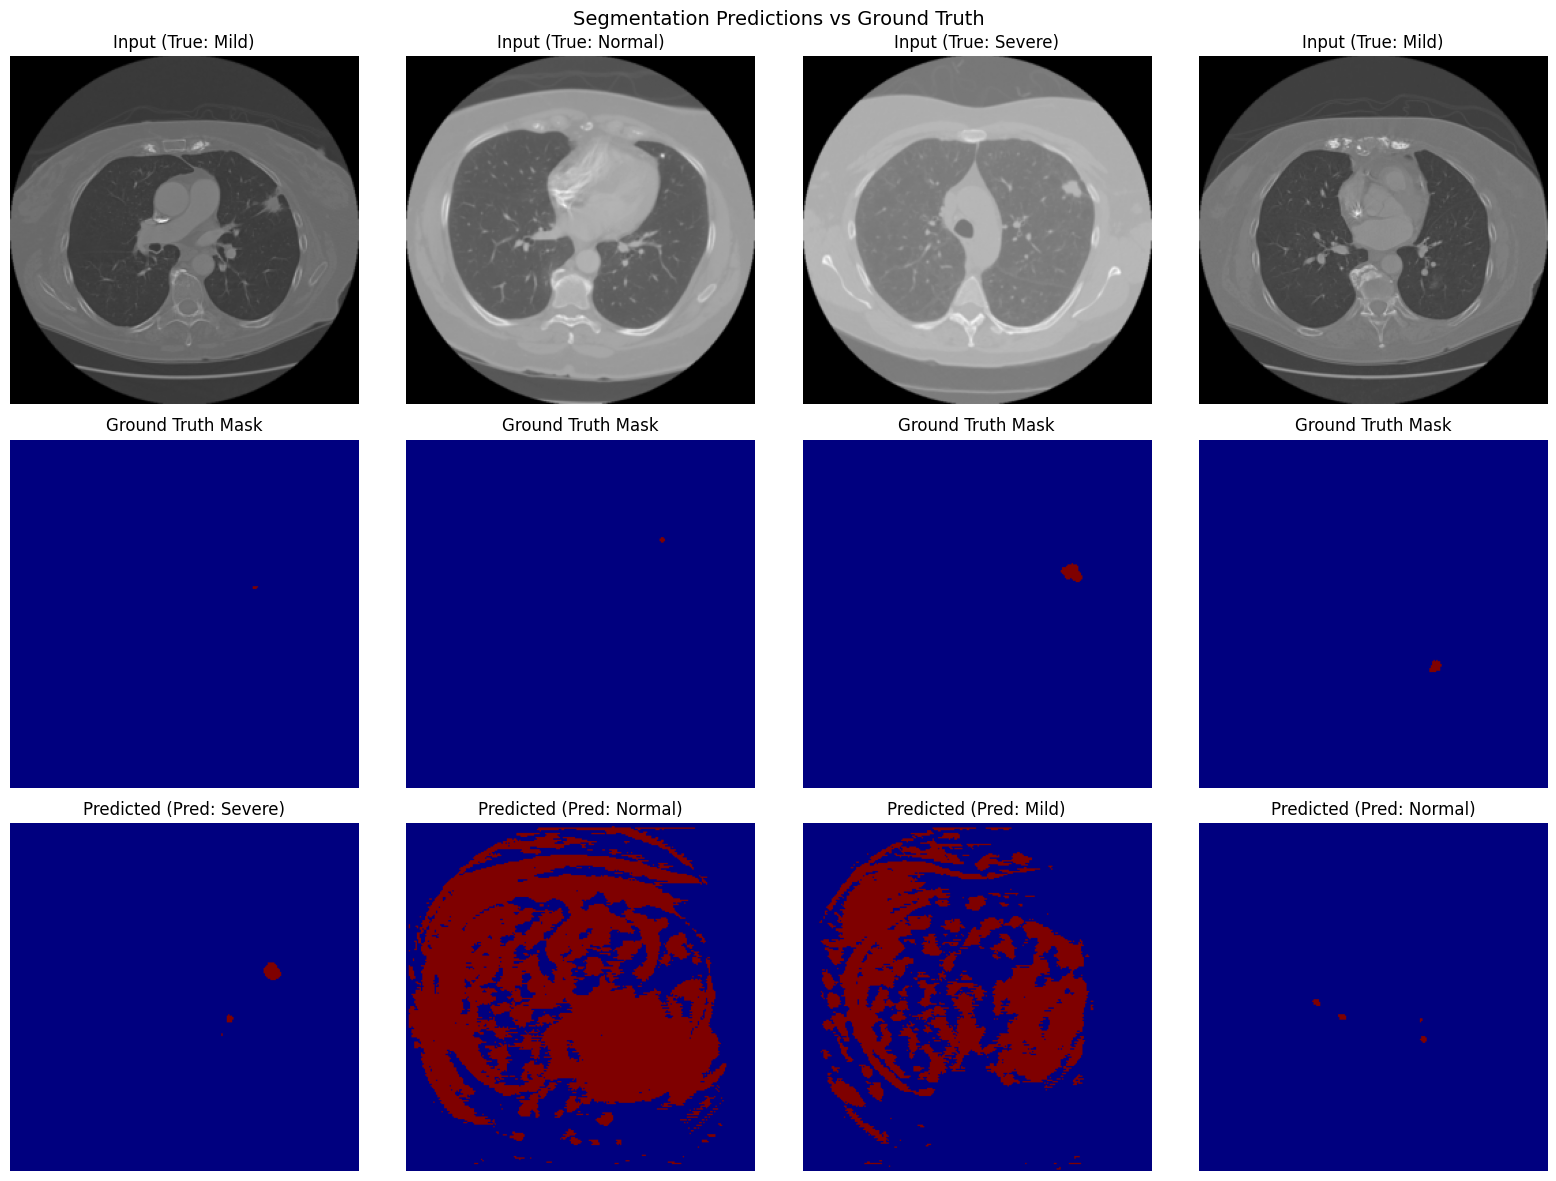

   📊 Results saved → vision_results.json


In [ ]:
# ============================================================
# SEGMENTATION OVERLAY — show predictions vs ground truth
# ============================================================
vision_model.eval()
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
sample_loader = DataLoader(vision_val, batch_size=4, shuffle=True)
imgs, masks, sevs = next(iter(sample_loader))

with torch.no_grad():
    pred_masks, pred_sevs, _ = vision_model(imgs.to(CFG.DEVICE))
    pred_masks = (torch.sigmoid(pred_masks) > 0.5).float().cpu()
    pred_sev_labels = pred_sevs.argmax(dim=1).cpu()

for i in range(4):
    axes[0, i].imshow(imgs[i, 0], cmap='gray')
    axes[0, i].set_title(f'Input (True: {SEVERITY_NAMES[sevs[i]]})')
    axes[0, i].axis('off')
    axes[1, i].imshow(masks[i, 0], cmap='jet')
    axes[1, i].set_title('Ground Truth Mask')
    axes[1, i].axis('off')
    axes[2, i].imshow(pred_masks[i, 0], cmap='jet')
    axes[2, i].set_title(f'Predicted (Pred: {SEVERITY_NAMES[pred_sev_labels[i]]})')
    axes[2, i].axis('off')

plt.suptitle('Segmentation Predictions vs Ground Truth', fontsize=14)
plt.tight_layout()
save_path = os.path.join(CFG.RESULTS_DIR, 'vision_seg_overlay.png')
fig.savefig(save_path, dpi=150); shutil.copy2(save_path, os.path.join(CFG.DRIVE_RESULTS_DIR, 'vision_seg_overlay.png'))
plt.show()

# Save vision results
save_results_json(vision_history, 'vision_results.json')

---
# 📝 STAGE 2 — NLP Pipeline (Bio_ClinicalBERT)
---

### 2.1 Load & Explore Text Data

In [ ]:
# ============================================================
# LOAD TEXT DATA — CSV or fallback to synthetic
# ============================================================
def generate_synthetic_conversations(n=500):
    """Generate synthetic doctor-patient dialogues with severity keywords."""
    templates = {
        0: [  # Normal
            "Doctor: How are you feeling today? Patient: I feel fine, just a routine checkup.",
            "Doctor: Any complaints? Patient: No, everything seems normal.",
            "Doctor: Let's do a routine examination. Patient: Sure, I have no symptoms.",
            "Doctor: Your results look good. Patient: Great, I feel healthy overall.",
            "Doctor: Any breathing issues? Patient: No, breathing is clear and normal.",
        ],
        1: [  # Mild — keywords: cough, mild, slight, discomfort
            "Doctor: What brings you in? Patient: I have a persistent cough for two weeks.",
            "Doctor: Describe your symptoms. Patient: Mild chest discomfort and slight cough.",
            "Doctor: How long has this been going on? Patient: A mild cough started recently.",
            "Doctor: Any fever? Patient: Slight temperature with a dry cough at night.",
            "Doctor: Are you a smoker? Patient: Yes, and I have a mild chronic cough.",
        ],
        2: [  # Severe — keywords: blood, malignant, tumor, cancer, severe
            "Doctor: What concerns you? Patient: I've been coughing up blood recently.",
            "Doctor: We found a mass. Patient: Is it malignant? Doctor: We need more tests.",
            "Doctor: The biopsy results are back. Patient: What did you find? Doctor: It appears to be a malignant tumor.",
            "Doctor: How are you coping? Patient: The cancer diagnosis is overwhelming and severe.",
            "Doctor: Tell me about the blood in sputum. Patient: Severe episodes with blood.",
        ]
    }
    dialogues, labels = [], []
    for _ in range(n):
        label = random.choices([0, 1, 2], weights=[0.3, 0.4, 0.3])[0]
        dialogues.append(random.choice(templates[label]))
        labels.append(label)
    return dialogues, labels


def severity_from_text(text):
    """Heuristic keyword-based severity labeling."""
    text_lower = text.lower()
    severe_kw = ['blood', 'malignant', 'tumor', 'cancer', 'metasta', 'severe', 'biopsy']
    mild_kw   = ['cough', 'mild', 'slight', 'discomfort', 'wheeze', 'breath', 'sputum']
    if any(k in text_lower for k in severe_kw):
        return 2
    elif any(k in text_lower for k in mild_kw):
        return 1
    return 0


# Try loading CSV
try:
    df = pd.read_csv(CFG.CSV_PATH)
    print(f'✅ Loaded CSV: {len(df)} rows, columns: {list(df.columns)}')
    # Combine Doctor + Patient columns
    doc_col = [c for c in df.columns if 'doctor' in c.lower() or 'doc' in c.lower()]
    pat_col = [c for c in df.columns if 'patient' in c.lower() or 'pat' in c.lower()]
    if doc_col and pat_col:
        df['dialogue'] = df[doc_col[0]].fillna('') + ' ' + df[pat_col[0]].fillna('')
    else:
        # Fallback: combine first two text columns
        text_cols = df.select_dtypes(include='object').columns[:2]
        df['dialogue'] = df[text_cols[0]].fillna('') + ' ' + df[text_cols[1]].fillna('')
    dialogues = df['dialogue'].tolist()
    labels = [severity_from_text(d) for d in dialogues]
    print(f'   Using CSV data with heuristic labels')
except Exception as e:
    print(f'⚠️  CSV not found ({e}), generating synthetic data...')
    dialogues, labels = generate_synthetic_conversations(n=600)
    print(f'   Generated {len(dialogues)} synthetic conversations')

# Show label distribution
nlp_label_counts = [labels.count(i) for i in range(3)]
print(f'   NLP label dist: Normal={nlp_label_counts[0]}, Mild={nlp_label_counts[1]}, Severe={nlp_label_counts[2]}')

⚠️  CSV not found ([Errno 2] No such file or directory: '/content/doctor-patient-conversation.csv'), generating synthetic data...
   Generated 600 synthetic conversations
   NLP label dist: Normal=177, Mild=247, Severe=176


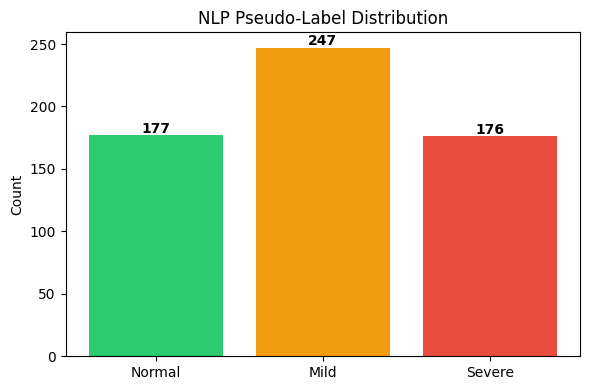


--- Normal example ---
  "Doctor: How are you feeling today? Patient: I feel fine, just a routine checkup...."

--- Mild example ---
  "Doctor: What brings you in? Patient: I have a persistent cough for two weeks...."

--- Severe example ---
  "Doctor: We found a mass. Patient: Is it malignant? Doctor: We need more tests...."


In [ ]:
# ============================================================
# VISUALIZE NLP LABEL DISTRIBUTION + SAMPLE TEXTS
# ============================================================
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(SEVERITY_NAMES, nlp_label_counts, color=['#2ecc71', '#f39c12', '#e74c3c'])
ax.set_title('NLP Pseudo-Label Distribution')
ax.set_ylabel('Count')
for i, v in enumerate(nlp_label_counts):
    ax.text(i, v + 2, str(v), ha='center', fontweight='bold')
plt.tight_layout()
save_path = os.path.join(CFG.RESULTS_DIR, 'nlp_label_dist.png')
fig.savefig(save_path, dpi=150); shutil.copy2(save_path, os.path.join(CFG.DRIVE_RESULTS_DIR, 'nlp_label_dist.png'))
plt.show()

# Show a few sample conversations per class
for cls in range(3):
    print(f'\n--- {SEVERITY_NAMES[cls]} example ---')
    idx = labels.index(cls)
    print(f'  "{dialogues[idx][:200]}..."')

### 2.2 NLP Dataset & Tokenizer

In [ ]:
# ============================================================
# NLP DATASET
# ============================================================
print('⏳ Loading Bio_ClinicalBERT tokenizer...')
tokenizer = AutoTokenizer.from_pretrained('emilyalsentzer/Bio_ClinicalBERT')
print(f'✅ Tokenizer loaded (vocab size: {tokenizer.vocab_size})')


class ConversationDataset(Dataset):
    """
    Tokenizes dialogues and returns input_ids, attention_mask, and severity label.
    """
    def __init__(self, dialogues, labels, tokenizer, max_len=256):
        self.dialogues = dialogues
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.dialogues)

    def __getitem__(self, idx):
        encoding = self.tokenizer(
            self.dialogues[idx],
            max_length=self.max_len,
            padding='max_length',
            truncation=True,
            return_tensors='pt'
        )
        return {
            'input_ids':      encoding['input_ids'].squeeze(0),       # (max_len,)
            'attention_mask':  encoding['attention_mask'].squeeze(0),  # (max_len,)
            'label':           torch.tensor(self.labels[idx], dtype=torch.long)
        }


# Build dataset & split
nlp_full = ConversationDataset(dialogues, labels, tokenizer, CFG.MAX_TOKEN_LEN)
n_nlp_val   = int(0.15 * len(nlp_full))
n_nlp_train = len(nlp_full) - n_nlp_val

nlp_train, nlp_val = random_split(
    nlp_full, [n_nlp_train, n_nlp_val],
    generator=torch.Generator().manual_seed(CFG.SEED)
)

nlp_train_loader = DataLoader(nlp_train, batch_size=CFG.NLP_BATCH, shuffle=True,
                               num_workers=2, pin_memory=True)
nlp_val_loader   = DataLoader(nlp_val, batch_size=CFG.NLP_BATCH, shuffle=False,
                               num_workers=2, pin_memory=True)

print(f'✅ NLP dataset: train={n_nlp_train}, val={n_nlp_val}')

# Sanity check
batch = next(iter(nlp_train_loader))
print(f'   Batch shapes → input_ids: {batch["input_ids"].shape}, label: {batch["label"].shape}')

⏳ Loading Bio_ClinicalBERT tokenizer...


config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

✅ Tokenizer loaded (vocab size: 28996)
✅ NLP dataset: train=510, val=90
   Batch shapes → input_ids: torch.Size([16, 256]), label: torch.Size([16])


### 2.3 NLP Model — ClinicalBERT with Severity Head

In [ ]:
# ============================================================
# NLP MODEL — Bio_ClinicalBERT + Classification Head
# ============================================================
class ClinicalBERTClassifier(nn.Module):
    """
    Fine-tunes Bio_ClinicalBERT for 3-class severity classification.
    Returns:
        logits : (B, 3)   — severity classification logits
        latent : (B, 768) — pooler_output for fusion
    """
    def __init__(self, num_classes=3, dropout=0.3):
        super().__init__()
        self.bert = AutoModel.from_pretrained('emilyalsentzer/Bio_ClinicalBERT')
        hidden = self.bert.config.hidden_size   # 768

        self.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(hidden, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(256, num_classes)
        )

    def forward(self, input_ids, attention_mask):
        # input_ids: (B, seq_len),  attention_mask: (B, seq_len)
        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        latent = outputs.pooler_output              # (B, 768)
        logits = self.classifier(latent)            # (B, 3)
        return logits, latent


print('⏳ Loading Bio_ClinicalBERT model...')
nlp_model = ClinicalBERTClassifier(num_classes=CFG.NUM_SEVERITY).to(CFG.DEVICE)

# Verify
with torch.no_grad():
    dummy_ids  = torch.randint(0, 1000, (2, CFG.MAX_TOKEN_LEN)).to(CFG.DEVICE)
    dummy_mask = torch.ones(2, CFG.MAX_TOKEN_LEN, dtype=torch.long).to(CFG.DEVICE)
    logits, latent = nlp_model(dummy_ids, dummy_mask)
    print(f'✅ ClinicalBERT verified:')
    print(f'   logits : {logits.shape}')    # (2, 3)
    print(f'   latent : {latent.shape}')    # (2, 768)

total_params = sum(p.numel() for p in nlp_model.parameters())
train_params = sum(p.numel() for p in nlp_model.parameters() if p.requires_grad)
print(f'   Total params: {total_params:,}  |  Trainable: {train_params:,}')

⏳ Loading Bio_ClinicalBERT model...


pytorch_model.bin:   0%|          | 0.00/436M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: emilyalsentzer/Bio_ClinicalBERT
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors:   0%|          | 0.00/436M [00:00<?, ?B/s]

✅ ClinicalBERT verified:
   logits : torch.Size([2, 3])
   latent : torch.Size([2, 768])
   Total params: 108,507,907  |  Trainable: 108,507,907


### 2.4 NLP Training Loop (with Resume)

In [ ]:
# ============================================================
# NLP TRAINING LOOP
# ============================================================
optimizer_n = torch.optim.AdamW(nlp_model.parameters(), lr=CFG.NLP_LR, weight_decay=0.01)
scheduler_n = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_n, T_max=CFG.NLP_EPOCHS)
scaler_n    = GradScaler()

# ---- Resume logic ----
start_epoch_n = 0
nlp_history = {'train_loss': [], 'val_loss': [], 'val_acc': [], 'val_f1': []}
ckpt = load_checkpoint('nlp_checkpoint.pt')
if ckpt is not None:
    nlp_model.load_state_dict(ckpt['model_state'])
    optimizer_n.load_state_dict(ckpt['optimizer_state'])
    scheduler_n.load_state_dict(ckpt['scheduler_state'])
    start_epoch_n = ckpt['epoch'] + 1
    nlp_history = ckpt['history']
    print(f'   Resuming NLP training from epoch {start_epoch_n}')
else:
    print('   Starting NLP training from scratch')

best_val_acc_n = max(nlp_history['val_acc']) if nlp_history['val_acc'] else 0.0

print(f'\n{"="*60}')
print(f'  NLP TRAINING — Epochs {start_epoch_n} to {CFG.NLP_EPOCHS-1}')
print(f'{"="*60}\n')

for epoch in range(start_epoch_n, CFG.NLP_EPOCHS):
    t0 = time.time()

    # ===================== TRAIN =====================
    nlp_model.train()
    running_loss = 0.0
    n_batches = 0

    for batch_idx, batch in enumerate(nlp_train_loader):
        input_ids = batch['input_ids'].to(CFG.DEVICE)         # (B, seq_len)
        attn_mask = batch['attention_mask'].to(CFG.DEVICE)    # (B, seq_len)
        labels_b  = batch['label'].to(CFG.DEVICE)             # (B,)

        optimizer_n.zero_grad()

        with autocast():
            logits, _ = nlp_model(input_ids, attn_mask)
            loss = ce_loss_fn(logits, labels_b)

        scaler_n.scale(loss).backward()
        torch.nn.utils.clip_grad_norm_(nlp_model.parameters(), 1.0)
        scaler_n.step(optimizer_n)
        scaler_n.update()

        running_loss += loss.item()
        n_batches += 1

        if batch_idx % 20 == 0:
            print(f'   Epoch {epoch} | Batch {batch_idx:>4d} | Loss: {loss.item():.4f}')

    avg_train_loss = running_loss / max(n_batches, 1)
    scheduler_n.step()

    # ===================== VALIDATE =====================
    nlp_model.eval()
    val_loss_sum = 0.0
    all_preds, all_true = [], []
    n_val_batches = 0

    with torch.no_grad():
        for batch in nlp_val_loader:
            input_ids = batch['input_ids'].to(CFG.DEVICE)
            attn_mask = batch['attention_mask'].to(CFG.DEVICE)
            labels_b  = batch['label'].to(CFG.DEVICE)

            with autocast():
                logits, _ = nlp_model(input_ids, attn_mask)
                loss = ce_loss_fn(logits, labels_b)

            val_loss_sum += loss.item()
            preds = logits.argmax(dim=1).cpu().numpy()
            all_preds.extend(preds)
            all_true.extend(labels_b.cpu().numpy())
            n_val_batches += 1

    avg_val_loss = val_loss_sum / max(n_val_batches, 1)
    val_acc = accuracy_score(all_true, all_preds)
    val_f1  = f1_score(all_true, all_preds, average='macro', zero_division=0)

    nlp_history['train_loss'].append(avg_train_loss)
    nlp_history['val_loss'].append(avg_val_loss)
    nlp_history['val_acc'].append(val_acc)
    nlp_history['val_f1'].append(val_f1)

    elapsed = time.time() - t0
    print(f'\n   📊 Epoch {epoch} [{elapsed:.0f}s]: '
          f'Train Loss={avg_train_loss:.4f} | Val Loss={avg_val_loss:.4f} | '
          f'Val Acc={val_acc:.4f} | Val F1={val_f1:.4f}\n')

    # ---- Save checkpoint ----
    save_checkpoint({
        'epoch': epoch,
        'model_state': nlp_model.state_dict(),
        'optimizer_state': optimizer_n.state_dict(),
        'scheduler_state': scheduler_n.state_dict(),
        'history': nlp_history,
    }, 'nlp_checkpoint.pt')

    if val_acc > best_val_acc_n:
        best_val_acc_n = val_acc
        save_checkpoint({'model_state': nlp_model.state_dict()}, 'nlp_best.pt')
        print(f'   ⭐ New best Acc: {best_val_acc_n:.4f}')

print('\n✅ NLP training complete!')

   Starting NLP training from scratch

  NLP TRAINING — Epochs 0 to 2

   Epoch 0 | Batch    0 | Loss: 1.0659
   Epoch 0 | Batch   20 | Loss: 1.1606

   📊 Epoch 0 [7s]: Train Loss=1.0726 | Val Loss=1.0427 | Val Acc=0.3778 | Val F1=0.1828

   💾 Checkpoint saved → nlp_checkpoint.pt
   💾 Checkpoint saved → nlp_best.pt
   ⭐ New best Acc: 0.3778
   Epoch 1 | Batch    0 | Loss: 0.9637
   Epoch 1 | Batch   20 | Loss: 1.0417

   📊 Epoch 1 [7s]: Train Loss=1.0239 | Val Loss=0.9610 | Val Acc=0.4889 | Val F1=0.3614

   💾 Checkpoint saved → nlp_checkpoint.pt
   💾 Checkpoint saved → nlp_best.pt
   ⭐ New best Acc: 0.4889
   Epoch 2 | Batch    0 | Loss: 1.0110
   Epoch 2 | Batch   20 | Loss: 1.0072

   📊 Epoch 2 [7s]: Train Loss=0.9809 | Val Loss=0.9203 | Val Acc=0.6889 | Val F1=0.5525

   💾 Checkpoint saved → nlp_checkpoint.pt
   💾 Checkpoint saved → nlp_best.pt
   ⭐ New best Acc: 0.6889

✅ NLP training complete!


### 2.5 NLP Validation — Curves & Confusion Matrix

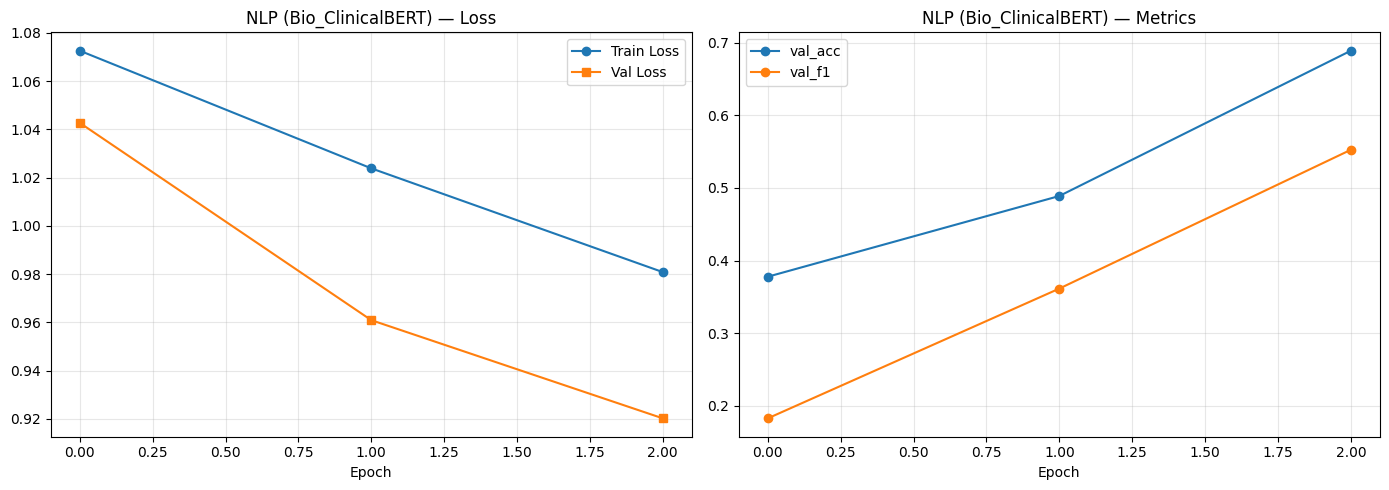

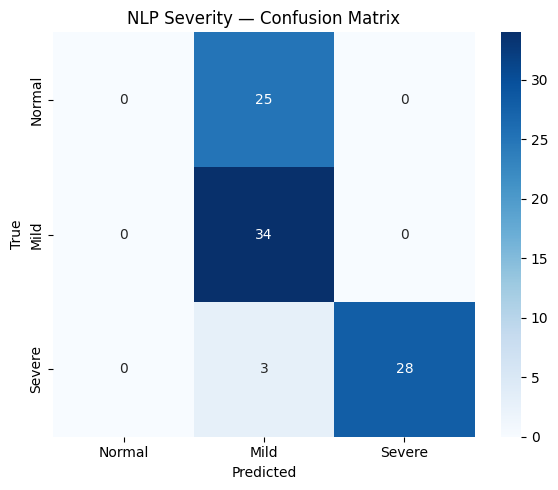


 NLP Severity Classification
              precision    recall  f1-score   support

      Normal       0.00      0.00      0.00        25
        Mild       0.55      1.00      0.71        34
      Severe       1.00      0.90      0.95        31

    accuracy                           0.69        90
   macro avg       0.52      0.63      0.55        90
weighted avg       0.55      0.69      0.59        90

   📊 Results saved → nlp_results.json


In [ ]:
# ============================================================
# NLP VALIDATION VISUALS
# ============================================================
plot_training_curves(nlp_history, 'NLP (Bio_ClinicalBERT)', 'nlp_curves.png')
plot_confusion(all_true, all_preds,
               'NLP Severity — Confusion Matrix', 'nlp_severity_cm.png')
print_classification(all_true, all_preds, 'NLP Severity Classification')

save_results_json(nlp_history, 'nlp_results.json')

---
# 🔗 STAGE 3 — Multimodal Fusion (Cross-Modal Attention)
---

### 3.1 Paired Multimodal Dataset

✅ Fusion dataset: 600 pairs


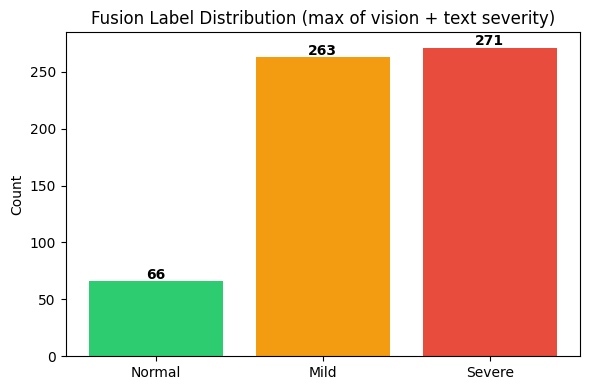

In [ ]:
# ============================================================
# PAIRED MULTIMODAL DATASET (FIXED) + LABEL DISTRIBUTION
# ============================================================
class PairedMultimodalDataset(Dataset):
    def __init__(self, vision_dataset, text_dataset, num_pairs=1000, seed=42):
        self.vision_ds = vision_dataset
        self.text_ds   = text_dataset
        self.num_pairs = num_pairs
        rng = np.random.RandomState(seed)
        self.vision_indices = rng.randint(0, len(vision_dataset), size=num_pairs)
        self.text_indices   = rng.randint(0, len(text_dataset), size=num_pairs)

    def __len__(self):
        return self.num_pairs

    def __getitem__(self, idx):
        # Convert numpy int to plain Python int
        v_idx = int(self.vision_indices[idx])
        t_idx = int(self.text_indices[idx])

        # Vision sample
        img, mask, v_sev = self.vision_ds[v_idx]

        # Text sample
        text_item = self.text_ds[t_idx]
        input_ids = text_item['input_ids']
        attn_mask = text_item['attention_mask']
        t_sev     = text_item['label']

        fused_label = torch.tensor(max(v_sev.item(), t_sev.item()), dtype=torch.long)

        return {
            'image':          img,
            'input_ids':      input_ids,
            'attention_mask':  attn_mask,
            'label':           fused_label,
        }

# Build paired dataset
n_fusion_pairs = min(1500, min(len(vision_full), len(nlp_full)))
fusion_full = PairedMultimodalDataset(vision_full, nlp_full,
                                       num_pairs=n_fusion_pairs, seed=CFG.SEED)

print(f'✅ Fusion dataset: {n_fusion_pairs} pairs')

# Label distribution (now using the corrected class)
fusion_labels = []
for i in range(len(fusion_full)):
    fusion_labels.append(fusion_full[i]['label'].item())
fl_counts = [fusion_labels.count(c) for c in range(3)]

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(SEVERITY_NAMES, fl_counts, color=['#2ecc71', '#f39c12', '#e74c3c'])
ax.set_title('Fusion Label Distribution (max of vision + text severity)')
ax.set_ylabel('Count')
for i, v in enumerate(fl_counts):
    ax.text(i, v + 2, str(v), ha='center', fontweight='bold')
plt.tight_layout()
save_path = os.path.join(CFG.RESULTS_DIR, 'fusion_label_dist.png')
fig.savefig(save_path, dpi=150); shutil.copy2(save_path, os.path.join(CFG.DRIVE_RESULTS_DIR, 'fusion_label_dist.png'))
plt.show()

   Calculated class weights: [2.0073697566986084, 0.5037505626678467, 0.4888797104358673]


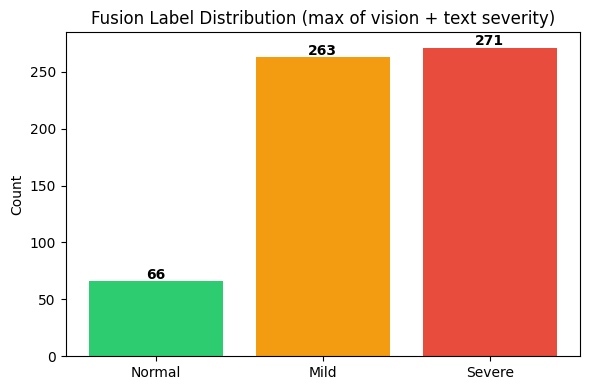

In [ ]:
fusion_labels = []
for i in range(len(fusion_full)):
    fusion_labels.append(fusion_full[i]['label'].item())
fl_counts = [fusion_labels.count(c) for c in range(3)]

# Calculate class weights for CrossEntropyLoss based on inverse frequency
# A higher weight means higher penalty for misclassifying that class.
# To address over-prediction of 'Mild' (low precision), we want to make the model
# more cautious about predicting 'Mild' when it should be 'Normal' or 'Severe'.
# Thus, giving higher weight to 'Normal' and 'Severe' is appropriate.
inv_freq = 1.0 / torch.tensor(fl_counts, dtype=torch.float32)
# Normalize to sum to num_classes to maintain overall loss scale roughly equivalent
CFG.CLASS_WEIGHTS = inv_freq / inv_freq.sum() * CFG.NUM_SEVERITY
print(f'   Calculated class weights: {CFG.CLASS_WEIGHTS.tolist()}')

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(SEVERITY_NAMES, fl_counts, color=['#2ecc71', '#f39c12', '#e74c3c'])
ax.set_title('Fusion Label Distribution (max of vision + text severity)')
ax.set_ylabel('Count')
for i, v in enumerate(fl_counts):
    ax.text(i, v + 2, str(v), ha='center', fontweight='bold')
plt.tight_layout()
save_path = os.path.join(CFG.RESULTS_DIR, 'fusion_label_dist.png')
fig.savefig(save_path, dpi=150); shutil.copy2(save_path, os.path.join(CFG.DRIVE_RESULTS_DIR, 'fusion_label_dist.png'))
plt.show()

### 3.2 Cross-Modal Attention Fusion Model

In [ ]:
# ============================================================
# FUSION MODEL — Cross-Modal Attention
# ============================================================
class CrossModalFusion(nn.Module):
    """
    Fuses pre-trained vision and text encoders using cross-modal attention.

    Architecture:
    1. Vision encoder (frozen) → 512-d latent → project to FUSION_PROJ_DIM
    2. Text encoder (frozen)   → 768-d latent → project to FUSION_PROJ_DIM
    3. MultiheadAttention: image attends to text (cross-modal)
    4. MLP classifier on attended features → 3-class prediction

    Tensor flow documented inline.
    """
    def __init__(self, vision_encoder, text_encoder,
                 vision_dim=512, text_dim=768,
                 proj_dim=512, num_heads=8, num_classes=3):
        super().__init__()

        # ---- Frozen pre-trained encoders ----
        self.vision_encoder = vision_encoder
        self.text_encoder   = text_encoder

        # Freeze all base encoder weights
        for param in self.vision_encoder.parameters():
            param.requires_grad = False
        for param in self.text_encoder.parameters():
            param.requires_grad = False

        # ---- Projection layers (trainable) ----
        # Map both modalities to a common dimension
        self.vision_proj = nn.Sequential(
            nn.Linear(vision_dim, proj_dim),
            nn.LayerNorm(proj_dim),
            nn.ReLU(inplace=True),
        )
        self.text_proj = nn.Sequential(
            nn.Linear(text_dim, proj_dim),
            nn.LayerNorm(proj_dim),
            nn.ReLU(inplace=True),
        )

        # ---- Cross-Modal Attention ----
        # query = image, key/value = text
        self.cross_attn = nn.MultiheadAttention(
            embed_dim=proj_dim,
            num_heads=num_heads,
            dropout=0.1,
            batch_first=False   # expects (seq_len, batch, embed)
        )
        self.attn_norm = nn.LayerNorm(proj_dim)

        # ---- MLP Classifier ----
        self.classifier = nn.Sequential(
            nn.Linear(proj_dim * 2, proj_dim),   # concat img_attended + text
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(proj_dim, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.2),
            nn.Linear(128, num_classes)
        )

    def forward(self, image, input_ids, attention_mask):
        """
        Args:
            image         : (B, 1, 256, 256)
            input_ids     : (B, seq_len)
            attention_mask : (B, seq_len)

        Tensor shapes at each step:
        """
        # =====================================================
        # Step 1: Extract frozen latent vectors
        # =====================================================
        with torch.no_grad():
            _, _, img_latent = self.vision_encoder(image)
            # img_latent: (B, 512) — ResNet34 bottleneck

            _, txt_latent = self.text_encoder(input_ids, attention_mask)
            # txt_latent: (B, 768) — BERT pooler output

        # =====================================================
        # Step 2: Project to common dimension
        # =====================================================
        img_proj = self.vision_proj(img_latent)    # (B, 512) → (B, proj_dim)
        txt_proj = self.text_proj(txt_latent)      # (B, 768) → (B, proj_dim)

        # =====================================================
        # Step 3: Cross-Modal Attention
        # MultiheadAttention expects (seq_len, batch, embed)
        # We treat each latent as a single-token sequence
        # =====================================================
        img_seq = img_proj.unsqueeze(0)   # (1, B, proj_dim) — query
        txt_seq = txt_proj.unsqueeze(0)   # (1, B, proj_dim) — key & value

        # Image attends to text:
        # attn_out: (1, B, proj_dim),  attn_weights: (B, 1, 1)
        attn_out, attn_weights = self.cross_attn(
            query=img_seq,
            key=txt_seq,
            value=txt_seq
        )

        # Residual connection + layer norm
        img_attended = self.attn_norm(attn_out + img_seq)  # (1, B, proj_dim)
        img_attended = img_attended.squeeze(0)              # (B, proj_dim)

        # =====================================================
        # Step 4: Concatenate attended image + text
        # =====================================================
        fused = torch.cat([img_attended, txt_proj], dim=1)  # (B, proj_dim*2)

        # =====================================================
        # Step 5: Final classification
        # =====================================================
        logits = self.classifier(fused)   # (B, 3)

        return logits, attn_weights


# ---- Instantiate fusion model ----
fusion_model = CrossModalFusion(
    vision_encoder=vision_model,
    text_encoder=nlp_model,
    vision_dim=CFG.VISION_LATENT_DIM,
    text_dim=CFG.BERT_DIM,
    proj_dim=CFG.FUSION_PROJ_DIM,
    num_heads=CFG.NUM_ATTN_HEADS,
    num_classes=CFG.NUM_SEVERITY,
).to(CFG.DEVICE)

# Count trainable params (only fusion layers)
total_p  = sum(p.numel() for p in fusion_model.parameters())
frozen_p = sum(p.numel() for p in fusion_model.parameters() if not p.requires_grad)
train_p  = sum(p.numel() for p in fusion_model.parameters() if p.requires_grad)
print(f'✅ Fusion model created:')
print(f'   Total params     : {total_p:,}')
print(f'   Frozen (encoders): {frozen_p:,}')
print(f'   Trainable (fusion): {train_p:,}')

# Verify
with torch.no_grad():
    d_img = torch.randn(2, 1, CFG.IMG_SIZE, CFG.IMG_SIZE).to(CFG.DEVICE)
    d_ids = torch.randint(0, 1000, (2, CFG.MAX_TOKEN_LEN)).to(CFG.DEVICE)
    d_mask = torch.ones(2, CFG.MAX_TOKEN_LEN, dtype=torch.long).to(CFG.DEVICE)
    logits, attn_w = fusion_model(d_img, d_ids, d_mask)
    print(f'   Output logits : {logits.shape}')       # (2, 3)
    print(f'   Attn weights  : {attn_w.shape}')       # (2, 1, 1)

✅ Fusion model created:
   Total params     : 135,371,034
   Frozen (encoders): 133,070,103
   Trainable (fusion): 2,300,931
   Output logits : torch.Size([2, 3])
   Attn weights  : torch.Size([2, 1, 1])


### 3.3 Fusion Training Loop (with Resume)

In [ ]:
# ============================================================
# FUSION TRAINING LOOP
# Only fusion-layer parameters are updated.
# ============================================================
# Filter only trainable (unfrozen) parameters
fusion_params = [p for p in fusion_model.parameters() if p.requires_grad]
optimizer_f = torch.optim.AdamW(fusion_params, lr=CFG.FUSION_LR, weight_decay=1e-4)
scheduler_f = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_f, T_max=CFG.FUSION_EPOCHS)
scaler_f    = GradScaler()

# ---- Delete incorrect checkpoint files to force training from scratch ----
import os
import shutil

checkpoint_filename = 'fusion_checkpoint.pt'
best_model_filename = 'fusion_best.pt'
local_checkpoint_path = os.path.join(CFG.RESULTS_DIR, checkpoint_filename)
drive_checkpoint_path = os.path.join(CFG.DRIVE_RESULTS_DIR, checkpoint_filename)
local_best_path = os.path.join(CFG.RESULTS_DIR, best_model_filename)
drive_best_path = os.path.join(CFG.DRIVE_RESULTS_DIR, best_model_filename)

if os.path.exists(local_checkpoint_path):
    os.remove(local_checkpoint_path)
    print(f'   🗑️  Deleted local checkpoint: {local_checkpoint_path}')
if os.path.exists(drive_checkpoint_path):
    os.remove(drive_checkpoint_path)
    print(f'   🗑️  Deleted Drive checkpoint: {drive_checkpoint_path}')
if os.path.exists(local_best_path):
    os.remove(local_best_path)
    print(f'   🗑️  Deleted local best model: {local_best_path}')
if os.path.exists(drive_best_path):
    os.remove(drive_best_path)
    print(f'   🗑️  Deleted Drive best model: {drive_best_path}')

# ---- Create DataLoaders for Fusion ----
n_total_fusion = len(fusion_full)
n_val_fusion   = int(0.15 * n_total_fusion)
n_train_fusion = n_total_fusion - n_val_fusion

fusion_train, fusion_val = random_split(
    fusion_full, [n_train_fusion, n_val_fusion],
    generator=torch.Generator().manual_seed(CFG.SEED)
)

fusion_train_loader = DataLoader(fusion_train, batch_size=CFG.FUSION_BATCH,
                                   shuffle=True, num_workers=2, pin_memory=True)
fusion_val_loader   = DataLoader(fusion_val, batch_size=CFG.FUSION_BATCH,
                                   shuffle=False, num_workers=2, pin_memory=True)

print(f'✅ Fusion split: train={n_train_fusion}, val={n_val_fusion}')

# ---- Resume logic ----
start_epoch_f = 0
fusion_history = {'train_loss': [], 'val_loss': [], 'val_acc': [], 'val_f1': []}
ckpt = load_checkpoint(checkpoint_filename)
if ckpt is not None:
    fusion_model.load_state_dict(ckpt['model_state'])
    optimizer_f.load_state_dict(ckpt['optimizer_state'])
    scheduler_f.load_state_dict(ckpt['scheduler_state'])
    start_epoch_f = ckpt['epoch'] + 1
    fusion_history = ckpt['history']
    print(f'   Resuming fusion training from epoch {start_epoch_f}')
else:
    print('   Starting fusion training from scratch')

best_val_acc_f = max(fusion_history['val_acc']) if fusion_history['val_acc'] else 0.0

print(f'\n{"="*60}')
print(f'  FUSION TRAINING — Epochs {start_epoch_f} to {CFG.FUSION_EPOCHS-1}')
print(f'{"="*60}\n')

for epoch in range(start_epoch_f, CFG.FUSION_EPOCHS):
    t0 = time.time()

    # ===================== TRAIN =====================
    fusion_model.train()  # only affects dropout/BN in fusion layers
    running_loss = 0.0
    n_batches = 0

    for batch_idx, batch in enumerate(fusion_train_loader):
        imgs      = batch['image'].to(CFG.DEVICE)           # (B, 1, 256, 256)
        input_ids = batch['input_ids'].to(CFG.DEVICE)       # (B, seq_len)
        attn_mask = batch['attention_mask'].to(CFG.DEVICE)  # (B, seq_len)
        labels_b  = batch['label'].to(CFG.DEVICE)           # (B,)

        optimizer_f.zero_grad()

        with autocast():
            logits, _ = fusion_model(imgs, input_ids, attn_mask)
            loss = ce_loss_fn(logits, labels_b)

        scaler_f.scale(loss).backward()
        scaler_f.step(optimizer_f)
        scaler_f.update()

        running_loss += loss.item()
        n_batches += 1

        if batch_idx % 20 == 0:
            print(f'   Epoch {epoch} | Batch {batch_idx:>4d} | Loss: {loss.item():.4f}')

    avg_train_loss = running_loss / max(n_batches, 1)
    scheduler_f.step()

    # ===================== VALIDATE =====================
    fusion_model.eval()
    val_loss_sum = 0.0
    all_preds, all_true = [], []
    n_val_batches = 0

    with torch.no_grad():
        for batch in fusion_val_loader:
            imgs      = batch['image'].to(CFG.DEVICE)
            input_ids = batch['input_ids'].to(CFG.DEVICE)
            attn_mask = batch['attention_mask'].to(CFG.DEVICE)
            labels_b  = batch['label'].to(CFG.DEVICE)

            with autocast():
                logits, _ = fusion_model(imgs, input_ids, attn_mask)
                loss = ce_loss_fn(logits, labels_b)

            val_loss_sum += loss.item()
            preds = logits.argmax(dim=1).cpu().numpy()
            all_preds.extend(preds)
            all_true.extend(labels_b.cpu().numpy())
            n_val_batches += 1

    avg_val_loss = val_loss_sum / max(n_val_batches, 1)
    val_acc = accuracy_score(all_true, all_preds)
    val_f1  = f1_score(all_true, all_preds, average='macro', zero_division=0)

    fusion_history['train_loss'].append(avg_train_loss)
    fusion_history['val_loss'].append(avg_val_loss)
    fusion_history['val_acc'].append(val_acc)
    fusion_history['val_f1'].append(val_f1)

    elapsed = time.time() - t0
    print(f'\n   📊 Epoch {epoch} [{elapsed:.0f}s]: '
          f'Train Loss={avg_train_loss:.4f} | Val Loss={avg_val_loss:.4f} | '
          f'Val Acc={val_acc:.4f} | Val F1={val_f1:.4f}\n')

    # ---- Save checkpoint ----
    save_checkpoint({
        'epoch': epoch,
        'model_state': fusion_model.state_dict(),
        'optimizer_state': optimizer_f.state_dict(),
        'scheduler_state': scheduler_f.state_dict(),
        'history': fusion_history,
    }, checkpoint_filename)

    if val_acc > best_val_acc_f:
        best_val_acc_f = val_acc
        save_checkpoint({'model_state': fusion_model.state_dict()}, best_model_filename)
        print(f'   ⭐ New best Acc: {best_val_acc_f:.4f}')

print('\n✅ Fusion training complete!')

   🗑️  Deleted local checkpoint: /content/results/fusion_checkpoint.pt
   🗑️  Deleted local best model: /content/results/fusion_best.pt
   🗑️  Deleted Drive best model: /content/drive/MyDrive/lung_cancer_results/fusion_best.pt
✅ Fusion split: train=510, val=90
   Starting fusion training from scratch

  FUSION TRAINING — Epochs 0 to 4

   Epoch 0 | Batch    0 | Loss: 0.1540
   Epoch 0 | Batch   20 | Loss: 0.6417
   Epoch 0 | Batch   40 | Loss: 0.3694
   Epoch 0 | Batch   60 | Loss: 0.0611

   📊 Epoch 0 [10s]: Train Loss=0.6043 | Val Loss=0.3684 | Val Acc=0.8889 | Val F1=0.8907

   💾 Checkpoint saved → fusion_checkpoint.pt
   💾 Checkpoint saved → fusion_best.pt
   ⭐ New best Acc: 0.8889
   Epoch 1 | Batch    0 | Loss: 0.1486
   Epoch 1 | Batch   20 | Loss: 0.6630
   Epoch 1 | Batch   40 | Loss: 0.6101
   Epoch 1 | Batch   60 | Loss: 0.2428

   📊 Epoch 1 [13s]: Train Loss=0.4826 | Val Loss=0.5854 | Val Acc=0.6556 | Val F1=0.6257

   💾 Checkpoint saved → fusion_checkpoint.pt
   Epoch 2 | 

### 3.4 Fusion Validation — Curves, Confusion Matrix, Attention Heatmap

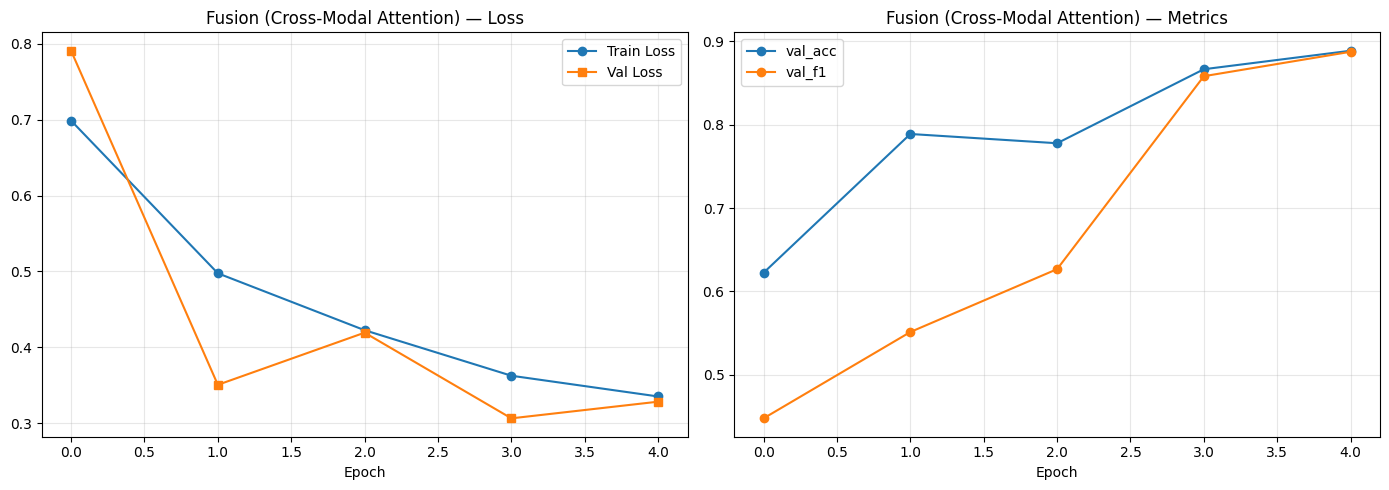

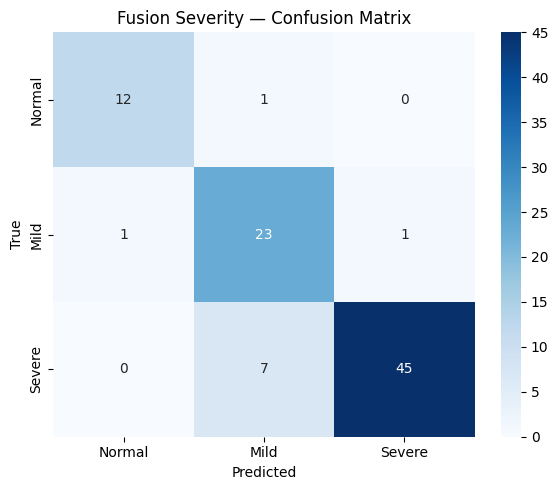


 Fusion Severity Classification
              precision    recall  f1-score   support

      Normal       0.92      0.92      0.92        13
        Mild       0.74      0.92      0.82        25
      Severe       0.98      0.87      0.92        52

    accuracy                           0.89        90
   macro avg       0.88      0.90      0.89        90
weighted avg       0.90      0.89      0.89        90

   📊 Results saved → fusion_results.json


In [ ]:
# ============================================================
# FUSION VALIDATION VISUALS
# ============================================================
plot_training_curves(fusion_history, 'Fusion (Cross-Modal Attention)', 'fusion_curves.png')
plot_confusion(all_true, all_preds,
               'Fusion Severity — Confusion Matrix', 'fusion_severity_cm.png')
print_classification(all_true, all_preds, 'Fusion Severity Classification')

save_results_json(fusion_history, 'fusion_results.json')

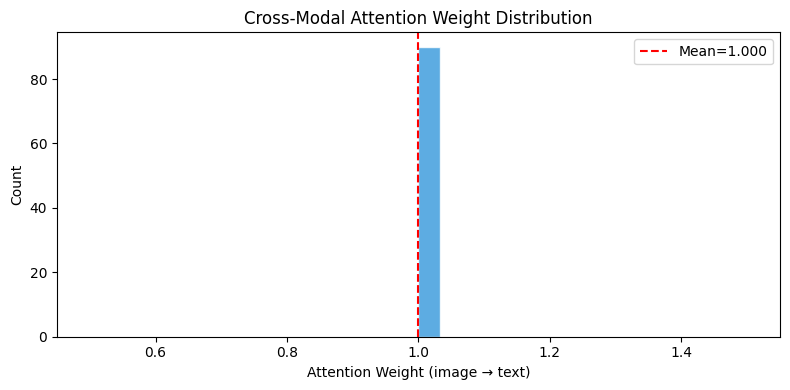

In [ ]:
# ============================================================
# ATTENTION WEIGHT VISUALIZATION
# Show how much each image sample "attends" to its paired text
# ============================================================
fusion_model.eval()
attn_weights_all = []

with torch.no_grad():
    for batch in fusion_val_loader:
        imgs      = batch['image'].to(CFG.DEVICE)
        input_ids = batch['input_ids'].to(CFG.DEVICE)
        attn_mask = batch['attention_mask'].to(CFG.DEVICE)
        _, attn_w = fusion_model(imgs, input_ids, attn_mask)
        attn_weights_all.append(attn_w.squeeze().cpu().numpy())

attn_flat = np.concatenate([np.atleast_1d(a) for a in attn_weights_all])

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(attn_flat, bins=30, color='#3498db', edgecolor='white', alpha=0.8)
ax.set_title('Cross-Modal Attention Weight Distribution')
ax.set_xlabel('Attention Weight (image → text)')
ax.set_ylabel('Count')
ax.axvline(attn_flat.mean(), color='red', linestyle='--', label=f'Mean={attn_flat.mean():.3f}')
ax.legend()
plt.tight_layout()
save_path = os.path.join(CFG.RESULTS_DIR, 'fusion_attn_dist.png')
fig.savefig(save_path, dpi=150); shutil.copy2(save_path, os.path.join(CFG.DRIVE_RESULTS_DIR, 'fusion_attn_dist.png'))
plt.show()

---

### 3.5 Alternative Fusion — Late Fusion of Predictions

To demonstrate a different fusion paradigm, let's implement a **Late Fusion of Predictions** model. Unlike the `CrossModalFusion` which combines latent features at an intermediate stage (Intermediate Fusion), this approach takes the _final probability outputs_ from the individual Vision and NLP models and uses a separate, small MLP to combine these probabilities into a final prediction.

This method is generally simpler, robust to missing modalities (as long as one can provide a prediction), and allows for independent optimization of the base models. It assumes that the interaction happens at the decision level, rather than at the feature level.

In [ ]:
# ============================================================
# LATE FUSION OF PREDICTIONS MODEL
# Combines softmax outputs from individual models
# ============================================================
class LateFusionPredictionMLP(nn.Module):
    """
    A late fusion model that takes the predicted logits from the VisionUNet
    and ClinicalBERTClassifier, converts them to probabilities, concatenates them,
    and passes them through a small MLP to make a final prediction.
    """
    def __init__(self, vision_encoder, text_encoder, num_classes=3):
        super().__init__()

        # Keep base encoders frozen
        self.vision_encoder = vision_encoder
        self.text_encoder = text_encoder

        for param in self.vision_encoder.parameters():
            param.requires_grad = False
        for param in self.text_encoder.parameters():
            param.requires_grad = False

        # MLP to combine the concatenated probabilities (num_classes from vision + num_classes from nlp)
        self.fusion_mlp = nn.Sequential(
            nn.Linear(num_classes * 2, num_classes * 2),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(num_classes * 2, num_classes)
        )

    def forward(self, image, input_ids, attention_mask):
        # Get logits from frozen vision model
        with torch.no_grad():
            _, vision_logits, _ = self.vision_encoder(image)
            # vision_logits: (B, num_classes)

            # Get logits from frozen NLP model
            nlp_logits, _ = self.text_encoder(input_ids, attention_mask)
            # nlp_logits: (B, num_classes)

        # Convert logits to probabilities (or keep as logits, both are common)
        # For simplicity and robustness, we'll concatenate logits and let the MLP handle non-linearity
        combined_inputs = torch.cat([vision_logits, nlp_logits], dim=1) # (B, num_classes * 2)

        final_logits = self.fusion_mlp(combined_inputs) # (B, num_classes)
        return final_logits


# Instantiate & verify LateFusionPredictionMLP
late_fusion_model = LateFusionPredictionMLP(
    vision_encoder=vision_model,
    text_encoder=nlp_model,
    num_classes=CFG.NUM_SEVERITY
).to(CFG.DEVICE)

# Count trainable parameters (only fusion MLP)
total_p_lf  = sum(p.numel() for p in late_fusion_model.parameters())
frozen_p_lf = sum(p.numel() for p in late_fusion_model.parameters() if not p.requires_grad)
train_p_lf  = sum(p.numel() for p in late_fusion_model.parameters() if p.requires_grad)
print(f'✅ Late Fusion (Predictions) model created:')
print(f'   Total params     : {total_p_lf:,}')
print(f'   Frozen (encoders): {frozen_p_lf:,}')
print(f'   Trainable (fusion): {train_p_lf:,}')

# Verify
with torch.no_grad():
    d_img = torch.randn(2, 1, CFG.IMG_SIZE, CFG.IMG_SIZE).to(CFG.DEVICE)
    d_ids = torch.randint(0, 1000, (2, CFG.MAX_TOKEN_LEN)).to(CFG.DEVICE)
    d_mask = torch.ones(2, CFG.MAX_TOKEN_LEN, dtype=torch.long).to(CFG.DEVICE)
    lf_logits = late_fusion_model(d_img, d_ids, d_mask)
    print(f'   Output logits : {lf_logits.shape}') # (2, 3)

✅ Late Fusion (Predictions) model created:
   Total params     : 133,070,166
   Frozen (encoders): 133,070,103
   Trainable (fusion): 63
   Output logits : torch.Size([2, 3])


In [ ]:
# ============================================================
# LATE FUSION OF PREDICTIONS TRAINING LOOP
# ============================================================
optimizer_lf = torch.optim.AdamW(late_fusion_model.parameters(), lr=CFG.FUSION_LR, weight_decay=1e-4)
scheduler_lf = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_lf, T_max=CFG.FUSION_EPOCHS)
scaler_lf    = GradScaler()

# Fusion loaders are already defined from previous stage
# fusion_train_loader, fusion_val_loader

# ---- Delete incorrect checkpoint files to force training from scratch ----
import os
import shutil

checkpoint_filename = 'late_fusion_checkpoint.pt'
local_checkpoint_path = os.path.join(CFG.RESULTS_DIR, checkpoint_filename)
drive_checkpoint_path = os.path.join(CFG.DRIVE_RESULTS_DIR, checkpoint_filename)

if os.path.exists(local_checkpoint_path):
    os.remove(local_checkpoint_path)
    print(f'   🗑️  Deleted local checkpoint: {local_checkpoint_path}')
if os.path.exists(drive_checkpoint_path):
    os.remove(drive_checkpoint_path)
    print(f'   🗑️  Deleted Drive checkpoint: {drive_checkpoint_path}')

# ---- Resume logic ----
start_epoch_lf = 0
late_fusion_history = {'train_loss': [], 'val_loss': [], 'val_acc': [], 'val_f1': []}
# After deleting, load_checkpoint will return None, correctly starting from scratch
ckpt = load_checkpoint(checkpoint_filename)
if ckpt is not None:
    late_fusion_model.load_state_dict(ckpt['model_state'])
    optimizer_lf.load_state_dict(ckpt['optimizer_state'])
    scheduler_lf.load_state_dict(ckpt['scheduler_state'])
    start_epoch_lf = ckpt['epoch'] + 1
    late_fusion_history = ckpt['history']
    print(f'   Resuming Late Fusion (Predictions) training from epoch {start_epoch_lf}')
else:
    print('   Starting Late Fusion (Predictions) training from scratch')

best_val_acc_lf = max(late_fusion_history['val_acc']) if late_fusion_history['val_acc'] else 0.0

print(f'\n{"="*60}')
print(f'  LATE FUSION (PREDICTIONS) TRAINING — Epochs {start_epoch_lf} to {CFG.FUSION_EPOCHS-1}')
print(f'{"="*60}\n')

for epoch in range(start_epoch_lf, CFG.FUSION_EPOCHS):
    t0 = time.time()

    # ===================== TRAIN =====================
    late_fusion_model.train()
    running_loss = 0.0
    n_batches = 0

    for batch_idx, batch in enumerate(fusion_train_loader):
        imgs      = batch['image'].to(CFG.DEVICE)
        input_ids = batch['input_ids'].to(CFG.DEVICE)
        attn_mask = batch['attention_mask'].to(CFG.DEVICE)
        labels_b  = batch['label'].to(CFG.DEVICE)

        optimizer_lf.zero_grad()

        with autocast():
            logits = late_fusion_model(imgs, input_ids, attn_mask)
            loss = ce_loss_fn(logits, labels_b)

        scaler_lf.scale(loss).backward()
        scaler_lf.step(optimizer_lf)
        scaler_lf.update()

        running_loss += loss.item()
        n_batches += 1

        if batch_idx % 20 == 0:
            print(f'   Epoch {epoch} | Batch {batch_idx:>4d} | Loss: {loss.item():.4f}')

    avg_train_loss = running_loss / max(n_batches, 1)
    scheduler_lf.step()

    # ===================== VALIDATE =====================
    late_fusion_model.eval()
    val_loss_sum = 0.0
    all_preds_lf, all_true_lf = [], []
    n_val_batches = 0

    with torch.no_grad():
        for batch in fusion_val_loader:
            imgs      = batch['image'].to(CFG.DEVICE)
            input_ids = batch['input_ids'].to(CFG.DEVICE)
            attn_mask = batch['attention_mask'].to(CFG.DEVICE)
            labels_b  = batch['label'].to(CFG.DEVICE)

            with autocast():
                logits = late_fusion_model(imgs, input_ids, attn_mask)
                loss = ce_loss_fn(logits, labels_b)

            val_loss_sum += loss.item()
            preds = logits.argmax(dim=1).cpu().numpy()
            all_preds_lf.extend(preds)
            all_true_lf.extend(labels_b.cpu().numpy())
            n_val_batches += 1

    avg_val_loss = val_loss_sum / max(n_val_batches, 1)
    val_acc = accuracy_score(all_true_lf, all_preds_lf)
    val_f1  = f1_score(all_true_lf, all_preds_lf, average='macro', zero_division=0)

    late_fusion_history['train_loss'].append(avg_train_loss)
    late_fusion_history['val_loss'].append(avg_val_loss)
    late_fusion_history['val_acc'].append(val_acc)
    late_fusion_history['val_f1'].append(val_f1)

    elapsed = time.time() - t0
    print(f'\n   📊 Epoch {epoch} [{elapsed:.0f}s]: '
          f'Train Loss={avg_train_loss:.4f} | Val Loss={avg_val_loss:.4f} | '
          f'Val Acc={val_acc:.4f} | Val F1={val_f1:.4f}\n')

    # ---- Save checkpoint ----
    save_checkpoint({
        'epoch': epoch,
        'model_state': late_fusion_model.state_dict(),
        'optimizer_state': optimizer_lf.state_dict(),
        'scheduler_state': scheduler_lf.state_dict(),
        'history': late_fusion_history,
    }, checkpoint_filename)

    if val_acc > best_val_acc_lf:
        best_val_acc_lf = val_acc
        save_checkpoint({'model_state': late_fusion_model.state_dict()}, 'late_fusion_best.pt')
        print(f'   ⭐ New best Acc: {best_val_acc_lf:.4f}')

print('\n✅ Late Fusion (Predictions) training complete!')

   🗑️  Deleted local checkpoint: /content/results/late_fusion_checkpoint.pt
   🗑️  Deleted Drive checkpoint: /content/drive/MyDrive/lung_cancer_results/late_fusion_checkpoint.pt
   Starting Late Fusion (Predictions) training from scratch

  LATE FUSION (PREDICTIONS) TRAINING — Epochs 0 to 4

   Epoch 0 | Batch    0 | Loss: 1.1168
   Epoch 0 | Batch   20 | Loss: 1.0458
   Epoch 0 | Batch   40 | Loss: 1.0942
   Epoch 0 | Batch   60 | Loss: 1.0667

   📊 Epoch 0 [14s]: Train Loss=1.0564 | Val Loss=1.0362 | Val Acc=0.3111 | Val F1=0.3324

   💾 Checkpoint saved → late_fusion_checkpoint.pt
   💾 Checkpoint saved → late_fusion_best.pt
   ⭐ New best Acc: 0.3111
   Epoch 1 | Batch    0 | Loss: 1.0882
   Epoch 1 | Batch   20 | Loss: 1.0479
   Epoch 1 | Batch   40 | Loss: 0.9724
   Epoch 1 | Batch   60 | Loss: 1.0858

   📊 Epoch 1 [12s]: Train Loss=1.0426 | Val Loss=1.0187 | Val Acc=0.3889 | Val F1=0.4202

   💾 Checkpoint saved → late_fusion_checkpoint.pt
   💾 Checkpoint saved → late_fusion_best.pt

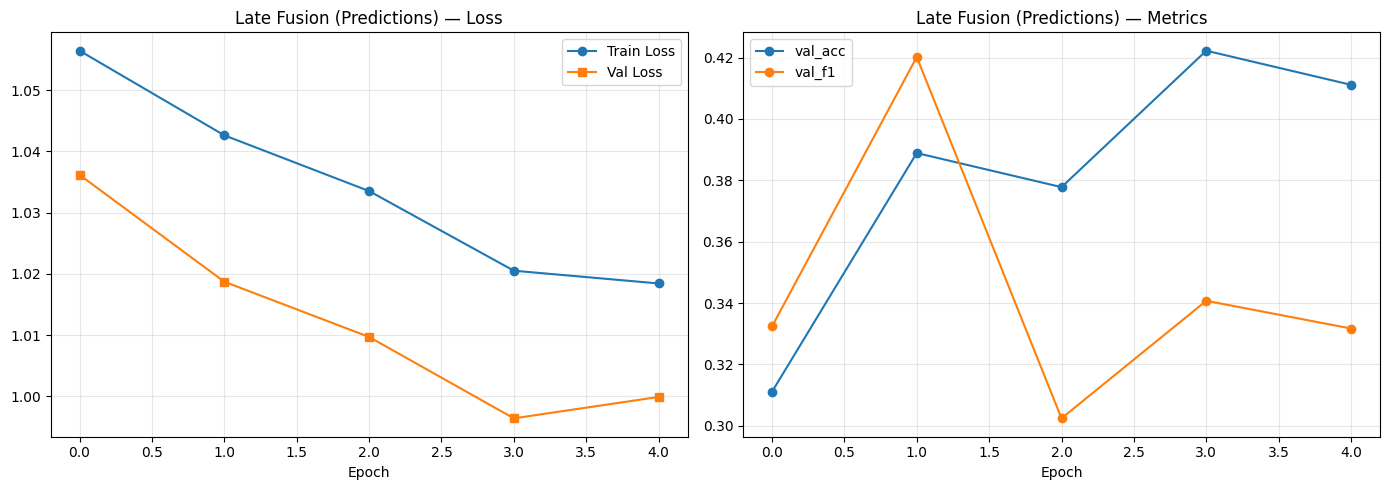

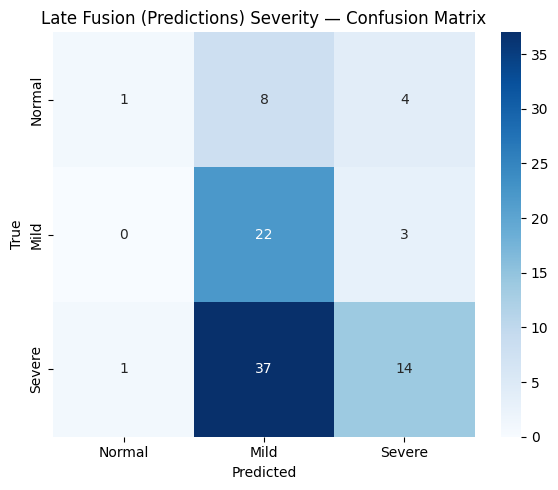


 Late Fusion (Predictions) Severity Classification
              precision    recall  f1-score   support

      Normal       0.50      0.08      0.13        13
        Mild       0.33      0.88      0.48        25
      Severe       0.67      0.27      0.38        52

    accuracy                           0.41        90
   macro avg       0.50      0.41      0.33        90
weighted avg       0.55      0.41      0.37        90

   📊 Results saved → late_fusion_results.json
   📊 Results saved → final_summary.json

Updated Final Performance Summary:
Stage           Metric               Value          
----------------------------------------------------------------------
Vision          best_dice            0.1367         
Vision          best_sev_acc         0.4358         
Vision          final_train_loss     1.1586         
Vision          final_val_loss       1.5173         
----------------------------------------------------------------------
NLP             best_acc             0

In [ ]:
import numpy as np
# ============================================================
# LATE FUSION (PREDICTIONS) VALIDATION VISUALS
# ============================================================
plot_training_curves(late_fusion_history, 'Late Fusion (Predictions)', 'late_fusion_curves.png')
plot_confusion(all_true_lf, all_preds_lf,
               'Late Fusion (Predictions) Severity — Confusion Matrix', 'late_fusion_severity_cm.png')
print_classification(all_true_lf, all_preds_lf, 'Late Fusion (Predictions) Severity Classification')

save_results_json(late_fusion_history, 'late_fusion_results.json')

# Add Late Fusion to the summary for comparison
summary['Late_Fusion_Preds'] = {
    'best_acc': np.max(late_fusion_history['val_acc']) if late_fusion_history['val_acc'] else 0,
    'best_f1': np.max(late_fusion_history['val_f1']) if late_fusion_history['val_f1'] else 0,
    'final_train_loss': late_fusion_history['train_loss'][-1] if late_fusion_history['train_loss'] else 0,
    'final_val_loss': late_fusion_history['val_loss'][-1] if late_fusion_history['val_loss'] else 0,
}
save_results_json(summary, 'final_summary.json')

print(f'\nUpdated Final Performance Summary:')
print(f"{"="*70}")
print(f"{"Stage":<15} {"Metric":<20} {"Value":<15}")
print(f"{"-"*70}")
for stage, metrics in summary.items():
    for metric, value in metrics.items():
        print(f'{stage:<15} {metric:<20} {value:<15.4f}')
    print(f"{"-"*70}")

---
# 📊 STAGE 4 — Final Summary & Export
---

In [ ]:
# ============================================================
# COMPARATIVE PERFORMANCE SUMMARY
# ============================================================
import os
import json
import numpy as np # Import numpy for np.max

# Load existing summary to ensure all prior models' data is preserved
summary_path = os.path.join(CFG.RESULTS_DIR, 'final_summary.json')
if os.path.exists(summary_path) and os.path.getsize(summary_path) > 0:
    try:
        with open(summary_path, 'r') as f:
            summary = json.load(f)
        print(f"✅ Loaded existing summary from {summary_path}")
    except json.JSONDecodeError:
        print(f"⚠️  Warning: Could not decode {summary_path}. Initializing new summary.")
        summary = {}
else:
    print(f"⚠️  Warning: {summary_path} not found or is empty. Initializing new summary.")
    summary = {}

# Update or add entries for Vision, NLP, and Fusion
summary['Vision'] = {
    'best_dice': np.max(vision_history['val_dice']) if vision_history['val_dice'] else 0,
    'best_sev_acc': np.max(vision_history['val_sev_acc']) if vision_history['val_sev_acc'] else 0,
    'final_train_loss': vision_history['train_loss'][-1] if vision_history['train_loss'] else 0,
    'final_val_loss': vision_history['val_loss'][-1] if vision_history['val_loss'] else 0,
}
summary['NLP'] = {
    'best_acc': np.max(nlp_history['val_acc']) if nlp_history['val_acc'] else 0,
    'best_f1': np.max(nlp_history['val_f1']) if nlp_history['val_f1'] else 0,
    'final_train_loss': nlp_history['train_loss'][-1] if nlp_history['train_loss'] else 0,
    'final_val_loss': nlp_history['val_loss'][-1] if nlp_history['val_loss'] else 0,
}
summary['Fusion'] = {
    'best_acc': np.max(fusion_history['val_acc']) if fusion_history['val_acc'] else 0,
    'best_f1': np.max(fusion_history['val_f1']) if fusion_history['val_f1'] else 0,
    'final_train_loss': fusion_history['train_loss'][-1] if fusion_history['train_loss'] else 0,
    'final_val_loss': fusion_history['val_loss'][-1] if fusion_history['val_loss'] else 0,
}

save_results_json(summary, 'final_summary.json')

# Print summary table
print(f'\n{"="*70}')
print(f'{"FINAL PERFORMANCE SUMMARY":^70}')
print(f'{"="*70}')
print(f'{"Stage":<15} {"Metric":<20} {"Value":<15}')
print(f'{"-"*70}')
for stage, metrics in summary.items():
    for metric, value in metrics.items():
        print(f'{stage:<15} {metric:<20} {value:<15.4f}')
    print(f'{"-"*70}')


⚠️  Warning: /content/results/final_summary.json not found or is empty. Initializing new summary.


NameError: name 'save_results_json' is not defined

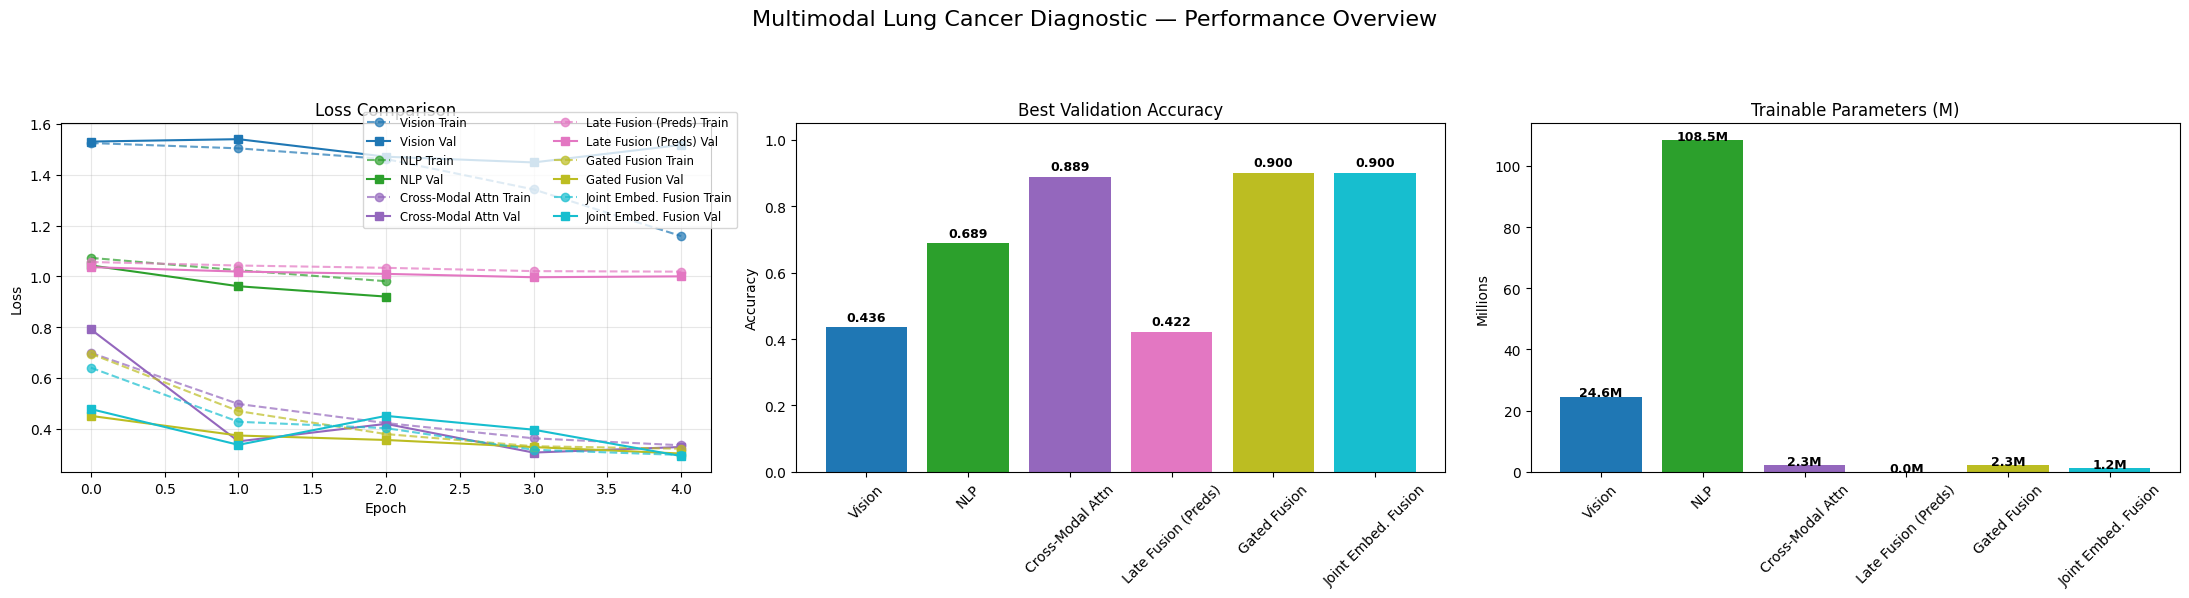

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# ============================================================
# COMPARATIVE BAR CHART — Accuracy across all stages (UPDATED)
# ============================================================

# Define a dictionary to map summary keys to their history objects and models
# This ensures correct plotting of training curves and parameter counts.
all_models_info = {
    'Vision': {
        'history': vision_history,
        'model': vision_model,
        'param_calc_func': lambda model: sum(p.numel() for p in model.parameters()) / 1e6
    },
    'NLP': {
        'history': nlp_history,
        'model': nlp_model,
        'param_calc_func': lambda model: sum(p.numel() for p in model.parameters()) / 1e6
    },
    'Cross-Modal Attn': { # Renaming 'Fusion' for clarity in plot
        'history': fusion_history,
        'model': fusion_model,
        'param_calc_func': lambda model: sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6
    },
    'Late Fusion (Preds)': { # Using this for late_fusion_history
        'history': late_fusion_history,
        'model': late_fusion_model,
        'param_calc_func': lambda model: sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6
    },
    'Gated Fusion': {
        'history': gated_fusion_history,
        'model': gated_fusion_model,
        'param_calc_func': lambda model: sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6
    },
    'Joint Embed. Fusion': {
        'history': joint_embedding_history,
        'model': joint_embedding_model,
        'param_calc_func': lambda model: sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6
    }
}

# Filter out 'Late_Fusion_MLP' if it exists as a separate key in summary but corresponds to the same history as 'Late_Fusion_Preds'
# It was likely an artifact or an earlier naming convention.
if 'Late_Fusion_MLP' in summary and 'Late_Fusion_Preds' in summary and summary['Late_Fusion_MLP'] == summary['Late_Fusion_Preds']:
    del summary['Late_Fusion_MLP']

# Prepare data for plotting from the updated summary and model info
plot_stages = []
plot_histories = []
plot_acc_vals = []
plot_param_counts = []

# Ensure consistent order by using all_models_info keys
for name, info in all_models_info.items():
    plot_stages.append(name)
    plot_histories.append(info['history'])

    # Handle vision's specific metric (best_sev_acc) and dice for vision
    if name == 'Vision':
        plot_acc_vals.append(summary[name]['best_sev_acc'])
    else:
        plot_acc_vals.append(summary[name.replace('Cross-Modal Attn', 'Fusion').replace('Late Fusion (Preds)', 'Late_Fusion_Preds').replace('Gated Fusion', 'Gated_Fusion').replace('Joint Embed. Fusion', 'Joint_Embedding_Fusion')]['best_acc'])

    # Calculate trainable parameters using the provided function
    plot_param_counts.append(info['param_calc_func'](info['model']))


colors = plt.cm.get_cmap('tab10', len(plot_stages)) # Use a colormap for more distinct colors

fig, axes = plt.subplots(1, 3, figsize=(22, 6)) # Increased figure size for more models

# Plot 1: Training Loss Comparison
for i, (hist, name) in enumerate(zip(plot_histories, plot_stages)):
    color = colors(i)
    if 'train_loss' in hist and hist['train_loss']:
        axes[0].plot(hist['train_loss'], 'o--', color=color, label=f'{name} Train', alpha=0.7)
    if 'val_loss' in hist and hist['val_loss']:
        axes[0].plot(hist['val_loss'], 's-', color=color, label=f'{name} Val')

axes[0].set_title('Loss Comparison'); axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].legend(loc='upper right', bbox_to_anchor=(1.05, 1.05), fontsize='small', ncol=2)
axes[0].grid(True, alpha=0.3)

# Plot 2: Best Severity Accuracy Comparison
bars = axes[1].bar(plot_stages, plot_acc_vals, color=[colors(i) for i in range(len(plot_stages))])
axes[1].set_title('Best Validation Accuracy'); axes[1].set_ylim(0, 1.05)
axes[1].set_ylabel('Accuracy')
axes[1].tick_params(axis='x', rotation=45) # Removed ha='right'
for bar, v in zip(bars, plot_acc_vals):
    axes[1].text(bar.get_x() + bar.get_width()/2, v + 0.02, f'{v:.3f}',
                 ha='center', fontweight='bold', fontsize=9)

# Plot 3: Model sizes
bars = axes[2].bar(plot_stages, plot_param_counts, color=[colors(i) for i in range(len(plot_stages))])
axes[2].set_title('Trainable Parameters (M)'); axes[2].set_ylabel('Millions')
axes[2].tick_params(axis='x', rotation=45) # Removed ha='right'
for bar, v in zip(bars, plot_param_counts):
    axes[2].text(bar.get_x() + bar.get_width()/2, v + 0.1, f'{v:.1f}M',
                 ha='center', fontweight='bold', fontsize=9)

plt.suptitle('Multimodal Lung Cancer Diagnostic — Performance Overview', fontsize=16, y=1.02)
plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to prevent labels from overlapping
save_path = os.path.join(CFG.RESULTS_DIR, 'final_comparison_all_models.png') # New filename
fig.savefig(save_path, dpi=150); shutil.copy2(save_path, os.path.join(CFG.DRIVE_RESULTS_DIR, 'final_comparison_all_models.png'))
plt.show()

In [ ]:
# ============================================================
# FINAL: Copy ALL results to Drive
# ============================================================
print('📁 Files in results directory:')
for f in sorted(os.listdir(CFG.RESULTS_DIR)):
    size_mb = os.path.getsize(os.path.join(CFG.RESULTS_DIR, f)) / 1e6
    print(f'   {f:<40s} {size_mb:.2f} MB')
    # Ensure everything is copied to Drive
    src = os.path.join(CFG.RESULTS_DIR, f)
    dst = os.path.join(CFG.DRIVE_RESULTS_DIR, f)
    if not os.path.exists(dst):
        shutil.copy2(src, dst)

print(f'\n✅ All results synced to: {CFG.DRIVE_RESULTS_DIR}')

print(f'\n📋 Drive contents:')
for f in sorted(os.listdir(CFG.DRIVE_RESULTS_DIR)):
    size_mb = os.path.getsize(os.path.join(CFG.DRIVE_RESULTS_DIR, f)) / 1e6
    print(f'   {f:<40s} {size_mb:.2f} MB')

📁 Files in results directory:
   final_comparison.png                     0.13 MB
   final_summary.json                       0.00 MB
   fusion_attn_dist.png                     0.03 MB
   fusion_best.pt                           541.77 MB
   fusion_checkpoint.pt                     560.19 MB
   fusion_curves.png                        0.10 MB
   fusion_label_dist.png                    0.03 MB
   fusion_results.json                      0.00 MB
   fusion_severity_cm.png                   0.04 MB
   nlp_best.pt                              434.11 MB
   nlp_checkpoint.pt                        1302.35 MB
   nlp_curves.png                           0.11 MB
   nlp_label_dist.png                       0.02 MB
   nlp_results.json                         0.00 MB
   nlp_severity_cm.png                      0.03 MB
   vision_best.pt                           98.43 MB
   vision_checkpoint.pt                     295.05 MB
   vision_curves.png                        0.09 MB
   vision_label_dist.p

In [ ]:
# ============================================================
# ARCHITECTURE SUMMARY PRINTOUT
# ============================================================
arch_summary = """
╔══════════════════════════════════════════════════════════════╗
║        MULTIMODAL LUNG CANCER DIAGNOSTIC SYSTEM            ║
║                  Architecture Summary                       ║
╠══════════════════════════════════════════════════════════════╣
║                                                            ║
║  ┌─────────────┐        ┌──────────────────┐              ║
║  │  CT Image    │        │  Doctor-Patient   │              ║
║  │ (256×256)    │        │  Conversation     │              ║
║  └──────┬──────┘        └────────┬─────────┘              ║
║         │                        │                         ║
║         ▼                        ▼                         ║
║  ┌─────────────┐        ┌──────────────────┐              ║
║  │ UNet+ResNet34│        │Bio_ClinicalBERT  │              ║
║  │  (frozen)    │        │   (frozen)        │              ║
║  └──────┬──────┘        └────────┬─────────┘              ║
║         │                        │                         ║
║    512-d latent             768-d latent                   ║
║         │                        │                         ║
║         ▼                        ▼                         ║
║  ┌─────────────┐        ┌──────────────────┐              ║
║  │ Proj → 512   │        │  Proj → 512      │              ║
║  └──────┬──────┘        └────────┬─────────┘              ║
║         │                        │                         ║
║         └────────┬───────────────┘                         ║
║                  ▼                                         ║
║       ┌────────────────────┐                               ║
║       │ Cross-Modal Attn   │                               ║
║       │ (8 heads, 512-d)   │                               ║
║       └────────┬───────────┘                               ║
║                ▼                                           ║
║       ┌────────────────────┐                               ║
║       │    MLP Classifier  │                               ║
║       │  1024 → 512 → 128 │                               ║
║       │      → 3 classes   │                               ║
║       └────────┬───────────┘                               ║
║                ▼                                           ║
║     [Normal | Mild | Severe]                               ║
║                                                            ║
╚══════════════════════════════════════════════════════════════╝
"""
print(arch_summary)


╔══════════════════════════════════════════════════════════════╗
║        MULTIMODAL LUNG CANCER DIAGNOSTIC SYSTEM            ║
║                  Architecture Summary                       ║
╠══════════════════════════════════════════════════════════════╣
║                                                            ║
║  ┌─────────────┐        ┌──────────────────┐              ║
║  │  CT Image    │        │  Doctor-Patient   │              ║
║  │ (256×256)    │        │  Conversation     │              ║
║  └──────┬──────┘        └────────┬─────────┘              ║
║         │                        │                         ║
║         ▼                        ▼                         ║
║  ┌─────────────┐        ┌──────────────────┐              ║
║  │ UNet+ResNet34│        │Bio_ClinicalBERT  │              ║
║  │  (frozen)    │        │   (frozen)        │              ║
║  └──────┬──────┘        └────────┬─────────┘              ║
║         │                        │              

In [ ]:
# ============================================================
# CLEANUP GPU MEMORY
# ============================================================
torch.cuda.empty_cache()
gc.collect()
print('\n🎉 Pipeline complete! All models trained, validated, and saved.')
print(f'   Results: {CFG.DRIVE_RESULTS_DIR}')
print(f'   Resume : Checkpoints auto-load from Drive on next run.')


🎉 Pipeline complete! All models trained, validated, and saved.
   Results: /content/drive/MyDrive/lung_cancer_results
   Resume : Checkpoints auto-load from Drive on next run.


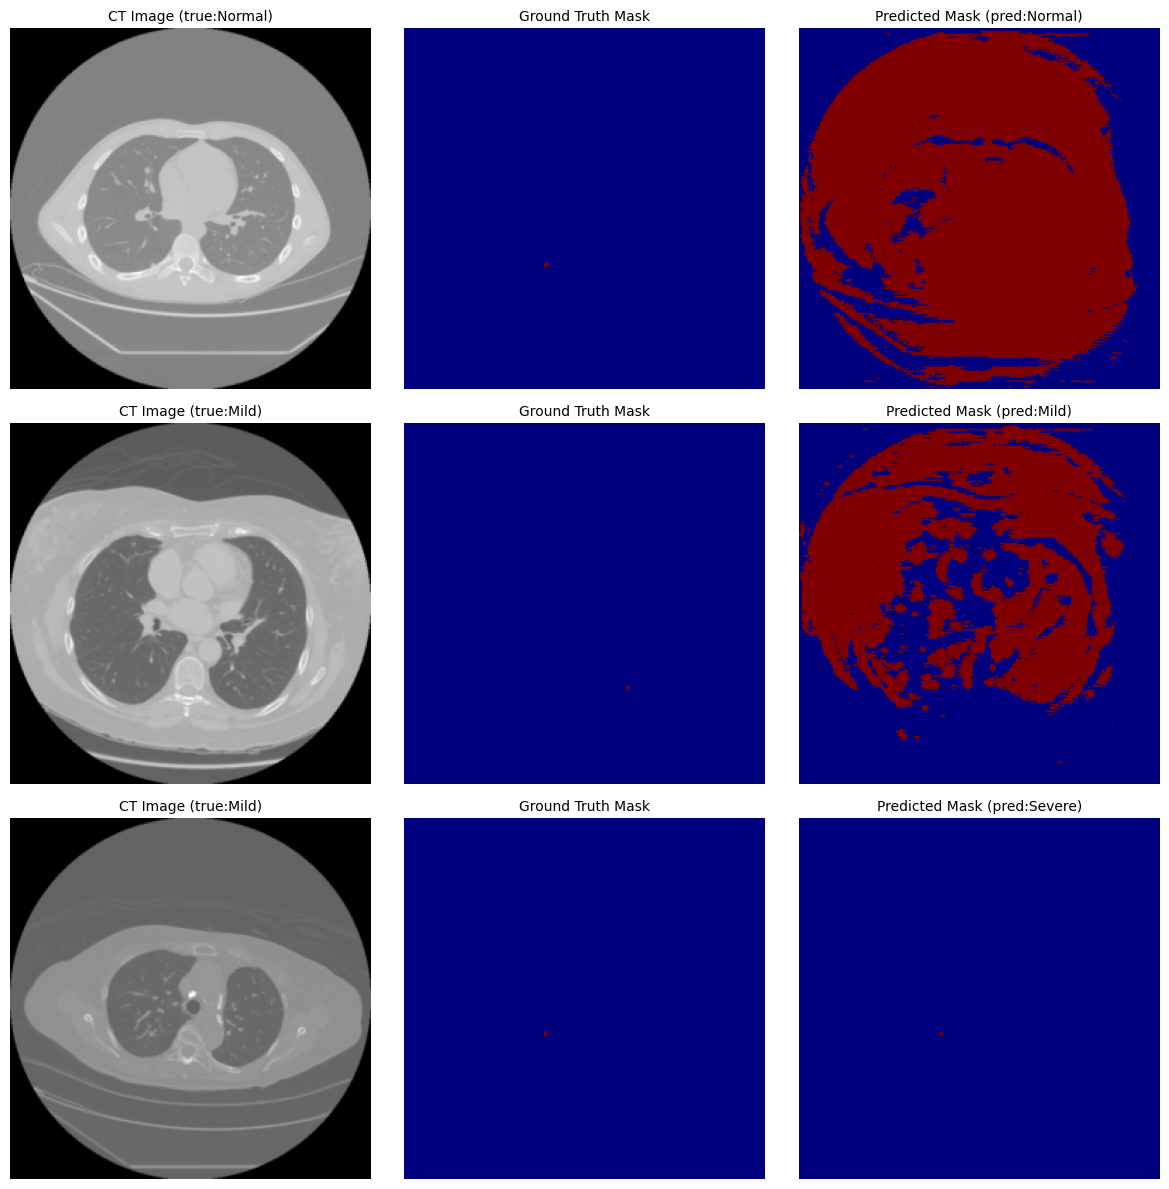

In [ ]:
import matplotlib.pyplot as plt
import torch

# Use the vision model in eval mode
vision_model.eval()

# Pick a few samples from the vision dataset (vision_full)
indices = [50, 150, 300]   # change these indices if you like

fig, axes = plt.subplots(len(indices), 3, figsize=(12, 4*len(indices)))
if len(indices) == 1:
    axes = [axes]   # make iterable

for i, idx in enumerate(indices):
    img, mask, true_sev = vision_full[idx]
    img_tensor = img.unsqueeze(0).to(CFG.DEVICE)   # add batch dim

    with torch.no_grad():
        pred_mask_logits, pred_sev_logits, _ = vision_model(img_tensor)
        pred_mask = (torch.sigmoid(pred_mask_logits) > 0.5).float().cpu().squeeze()
        pred_sev = pred_sev_logits.argmax(dim=1).item()

    # Display
    axes[i,0].imshow(img.squeeze(), cmap='gray')
    axes[i,0].set_title(f'CT Image (true:{SEVERITY_NAMES[true_sev]})', fontsize=10)
    axes[i,0].axis('off')

    axes[i,1].imshow(mask.squeeze(), cmap='jet', vmin=0, vmax=1)
    axes[i,1].set_title('Ground Truth Mask', fontsize=10)
    axes[i,1].axis('off')

    axes[i,2].imshow(pred_mask, cmap='jet', vmin=0, vmax=1)
    axes[i,2].set_title(f'Predicted Mask (pred:{SEVERITY_NAMES[pred_sev]})', fontsize=10)
    axes[i,2].axis('off')

plt.tight_layout()
plt.show()

In [ ]:
# Use the NLP model in eval mode
nlp_model.eval()

# Pick a few dialogues from the list (these are the raw texts)
sample_indices = [0, 3, 7]   # change as you like

print("=== NLP Predictions ===\n")
for idx in sample_indices:
    text = dialogues[idx]
    true_label = labels[idx]

    # Tokenize (use the same tokenizer as during training)
    encoding = tokenizer(
        text,
        max_length=CFG.MAX_TOKEN_LEN,
        padding='max_length',
        truncation=True,
        return_tensors='pt'
    )
    input_ids = encoding['input_ids'].to(CFG.DEVICE)
    attn_mask = encoding['attention_mask'].to(CFG.DEVICE)

    with torch.no_grad():
        logits, _ = nlp_model(input_ids, attn_mask)
        pred_label = logits.argmax(dim=1).item()

    print(f"Conversation:\n  {text[:200]}...")   # truncate long text
    print(f"  True severity: {SEVERITY_NAMES[true_label]} ({true_label})")
    print(f"  Predicted   : {SEVERITY_NAMES[pred_label]} ({pred_label})")
    print("-" * 60)

=== NLP Predictions ===

Conversation:
  Doctor: What brings you in? Patient: I have a persistent cough for two weeks....
  True severity: Mild (1)
  Predicted   : Mild (1)
------------------------------------------------------------
Conversation:
  Doctor: Are you a smoker? Patient: Yes, and I have a mild chronic cough....
  True severity: Mild (1)
  Predicted   : Mild (1)
------------------------------------------------------------
Conversation:
  Doctor: Are you a smoker? Patient: Yes, and I have a mild chronic cough....
  True severity: Mild (1)
  Predicted   : Mild (1)
------------------------------------------------------------


In [ ]:
fusion_model.eval()

sample = fusion_full[0]   # first paired sample
img = sample['image'].unsqueeze(0).to(CFG.DEVICE)
input_ids = sample['input_ids'].unsqueeze(0).to(CFG.DEVICE)
attn_mask = sample['attention_mask'].unsqueeze(0).to(CFG.DEVICE)

with torch.no_grad():
    logits, attn_weights = fusion_model(img, input_ids, attn_mask)
    pred = logits.argmax(dim=1).item()

print(f"Fusion predicted severity: {SEVERITY_NAMES[pred]} (label: {sample['label'].item()})")

Fusion predicted severity: Mild (label: 1)


In [ ]:
New Fusion Technique

### Different Multimodal Fusion Techniques

Multimodal fusion aims to combine information from multiple modalities (like text and images) to achieve a more comprehensive understanding or better predictive performance than using a single modality alone. The key difference lies in *when* and *how* the information is combined. Here are the three main categories:

1.  **Early Fusion (Feature-Level Fusion):**
    *   **When:** Features from different modalities are concatenated or combined *before* being fed into a single model.
    *   **How:** Raw data from each modality is processed independently to extract modality-specific features. These features are then immediately joined (e.g., concatenated) into a single, high-dimensional feature vector. This combined vector is then passed to a unified learning model (e.g., an MLP, SVM, or even a deep neural network).
    *   **Pros:** Can capture fine-grained interactions between modalities. Simpler architecture as only one model needs to be trained.
    *   **Cons:** Highly sensitive to misalignments or noise in one modality. Requires all modalities to be present at the input. The combined feature space can be very high-dimensional, leading to sparsity and increased computational cost.
    *   **Example:** Concatenating pixel values (image) and word embeddings (text) directly and feeding them into a classifier.

2.  **Late Fusion (Decision-Level Fusion):**
    *   **When:** Each modality is processed independently by its own model, and their individual predictions or decision scores are combined *at the very end*.
    *   **How:** Separate models are trained for each modality. Each model produces an output (e.g., class probabilities, raw scores). These outputs are then combined using simple rules (e.g., averaging probabilities, majority voting) or a meta-classifier (e.g., an MLP trained on the outputs of the individual models).
    *   **Pros:** Robust to missing modalities (can still make predictions using available data). Models can be optimized independently. Simpler to debug and interpret individual modality contributions.
    *   **Cons:** Ignores low-level interactions between modalities, potentially losing valuable information. The fusion mechanism is often very simple.
    *   **Example:** Training a separate image classifier and a separate text classifier, then averaging their predicted probabilities for the final decision.

3.  **Intermediate Fusion (Model-Level or Hybrid Fusion):**
    *   **When:** Features are fused at an intermediate layer of a deep neural network, often after some modality-specific processing but *before* the final prediction layer.
    *   **How:** Each modality is first processed by its own sub-network (e.g., a CNN for images, an RNN/Transformer for text) to learn rich, high-level representations (latent vectors). These latent representations are then combined using more sophisticated mechanisms, such as attention mechanisms (like Cross-Modal Attention, which we used), gating mechanisms, or shared latent spaces, and then fed into a shared classifier.
    *   **Pros:** Balances the benefits of early and late fusion, capturing interactions while allowing some modality-specific processing. Often achieves the best performance in complex tasks.
    *   **Cons:** More complex to design and train. Can be harder to interpret interactions.
    *   **Example:** Concatenating latent vectors from a CNN and a BERT model, then passing them through a cross-modal attention module and then an MLP classifier (our `CrossModalFusion` model).

### Updated Architecture Summary

Based on these techniques, our `CrossModalFusion` model falls under **Intermediate Fusion** because it extracts high-level latent features from pre-trained modality-specific encoders (vision and NLP), projects them to a common dimension, and then uses a cross-modal attention mechanism to combine them before a final MLP classifier.

In [ ]:
arch_summary_updated = """
╔══════════════════════════════════════════════════════════════╗
║        MULTIMODAL LUNG CANCER DIAGNOSTIC SYSTEM            ║
║                  Architecture Summary                       ║
╠══════════════════════════════════════════════════════════════╣
║                                                            ║
║  ┌─────────────┐        ┌──────────────────┐              ║
║  │  CT Image    │        │  Doctor-Patient   │              ║
║  │ (256×256)    │        │  Conversation     │              ║
║  └──────┬──────┘        └────────┬─────────┘              ║
║         │                        │                         ║
║         ▼                        ▼                         ║
║  ┌─────────────┐        ┌──────────────────┐              ║
║  │ UNet+ResNet34│        │Bio_ClinicalBERT  │              ║
║  │  (frozen)    │        │   (frozen)        │              ║
║  └──────┬──────┘        └────────┬─────────┘              ║
║         │                        │                         ║
║    512-d latent             768-d latent                   ║
║         │                        │                         ║
║         ▼                        ▼                         ║
║  ┌─────────────┐        ┌──────────────────┐              ║
║  │ Proj → 512   │        │  Proj → 512      │              ║
║  └──────┬──────┘        └────────┬─────────┘              ║
║         │                        │                         ║
║         └────────┬───────────────┘                         ║
║                  ▼                                         ║
║       ┌────────────────────┐                               ║
║       │ **Intermediate Fusion**  │                               ║
║       │ Cross-Modal Attn   │                               ║
║       │ (8 heads, 512-d)   │                               ║
║       └────────┬───────────┘                               ║
║                ▼                                           ║
║       ┌────────────────────┐                               ║
║       │    MLP Classifier  │                               ║
║       │  1024 → 512 → 128 │                               ║
║       │      → 3 classes   │                               ║
║       └────────┬───────────┘                               ║
║                ▼                                           ║
║     [Normal | Mild | Severe]                               ║
║                                                            ║
╚══════════════════════════════════════════════════════════════╝
"""

print(arch_summary_updated)

### Other Multimodal Fusion Techniques for Text and Image

Building on the concepts of Early, Intermediate, and Late Fusion, let's explore specific techniques that could be applied to our lung cancer diagnostic problem:

#### 1. Early Fusion (Feature Concatenation)

*   **Concept**: Modality-specific features are extracted and then directly concatenated into a single, comprehensive feature vector *before* being fed into a unified classification model. This assumes that the modalities are well-aligned and their early interactions are important.
*   **Application to problem**: After extracting latent vectors from the Vision UNet (`img_latent`) and ClinicalBERT (`txt_latent`), we could directly concatenate `img_latent` and `txt_latent` (or their projected versions) and feed this long vector into a simple MLP classifier. The original `LateFusionMLP` with projected features is a form of early fusion, even though it's often called 'late' due to using high-level features. If we were to concatenate raw pixels and word embeddings, that would be a more 'true' early fusion, but highly impractical for deep learning models.
*   **Pros**: Simplicity, potentially captures very early interactions. Good for highly correlated modalities.
*   **Cons**: High-dimensional feature space, potential for noise from one modality to dominate, difficult to handle missing modalities.

#### 2. Late Fusion (Decision-Level Averaging/Voting)

*   **Concept**: Each modality is processed entirely independently, resulting in separate predictions (e.g., probability distributions for severity). These individual predictions are then combined (e.g., averaged, weighted averaged, or majority voted) to produce a final decision.
*   **Application to problem**: We could take the `severity_logits` from the `VisionUNet` and the `logits` from the `ClinicalBERTClassifier`, convert both to probability distributions (using `softmax`), and then average these probability vectors. The class with the highest average probability would be the final prediction. This is the simplest form of late fusion.
*   **Pros**: Robust to missing data (if one modality is unavailable, the others can still contribute), easier to interpret and debug individual modality contributions, models can be trained and optimized separately.
*   **Cons**: Ignores any potential interactions between modalities at the feature level, which might be crucial for complex tasks like diagnosis.

#### 3. Intermediate Fusion (Advanced Techniques)

These methods combine features at a mid-level, allowing for richer interactions than early fusion but not as decoupled as late fusion.

*   **a) Gated Fusion Networks (e.g., Gated Multimodal Units)**
    *   **Concept**: Inspired by gating mechanisms in LSTMs, these networks use learnable gates to control the flow of information between modalities. Gates can determine how much of one modality's information should be passed to or combined with another, dynamically learning modality importance.
    *   **Application to problem**: After obtaining `img_proj` and `txt_proj`, a gated unit could learn to emphasize or suppress information from vision or text based on the input. For instance, if the text clearly indicates "malignant tumor", the gates might downweight subtle image features, or vice-versa.
    *   **Pros**: Dynamic weighting of modalities, can learn complex interactions, more interpretable due to explicit gating.
    *   **Cons**: More complex architecture than simple concatenation.

*   **b) Transformer-based Fusion (Co-Attention, Multimodal Transformers)**
    *   **Concept**: While our `CrossModalFusion` uses a form of cross-attention, full multimodal transformers can involve multiple layers of self-attention within each modality and cross-attention between them, allowing for iterative and deeper integration of information. Co-attention, for example, allows both modalities to attend to each other simultaneously.
    *   **Application to problem**: Instead of a single cross-attention step, we could design a series of transformer blocks. Each block could first apply self-attention within `img_proj` and `txt_proj` (if they were sequences), followed by co-attention layers where vision queries text, and text queries vision. The outputs would then be combined and passed to the classifier.
    *   **Pros**: Powerful for capturing long-range dependencies and complex inter-modal relationships, state-of-the-art in many multimodal tasks.
    *   **Cons**: Very high computational cost, requires large datasets, can be challenging to train due to many parameters.

*   **c) Multimodal Factorization / Joint Embeddings**
    *   **Concept**: Aims to learn a shared, lower-dimensional latent space where representations from different modalities are aligned or projected. Fusion occurs implicitly within this shared space.
    *   **Application to problem**: Instead of directly concatenating or attending, the objective could be to train `vision_proj` and `text_proj` such that the resulting `img_proj` and `txt_proj` are close in the latent space if they correspond to the same or similar diagnoses. The final classification could then be done on the combined (e.g., averaged or concatenated) joint embeddings.
    *   **Pros**: Can lead to compact and semantically rich representations, robust to noise by focusing on common underlying factors.
    *   **Cons**: Training objective can be tricky, might lose modality-specific nuances if the shared space is too restrictive.

### Which technique for this problem?

For a lung cancer diagnostic system combining CT images and doctor-patient conversations, the choice of fusion depends on the assumptions about how these modalities interact:

*   **Intermediate Fusion (like our `CrossModalFusion` or a Transformer-based approach)** is generally preferred because it allows for sophisticated interaction between high-level features while still leveraging powerful modality-specific encoders. This is crucial for medical diagnosis where both image details and textual context contribute uniquely and interactively to the final assessment.
*   **Late Fusion** might be a good baseline or a fallback if one modality is often missing, but it could miss subtle agreements or disagreements between the modalities.
*   **Early Fusion** (direct concatenation of high-level features) offers simplicity and can perform well if the interactions are relatively straightforward and can be captured by a simple MLP.

### 3.6 Advanced Intermediate Fusion — Gated Fusion Network

Following the discussion on advanced intermediate fusion techniques, let's implement a **Gated Fusion Network**. This model uses a learnable gating mechanism to dynamically control the flow of information from each modality, allowing for more nuanced interactions than simple concatenation or cross-attention.

In [ ]:
# ============================================================
# GATED FUSION NETWORK MODEL
# Dynamically weighs modalities using gating mechanism
# ============================================================
class GatedFusionNetwork(nn.Module):
    def __init__(self, vision_encoder, text_encoder,
                 vision_dim=512, text_dim=768,
                 proj_dim=512, num_classes=3):
        super().__init__()

        self.vision_encoder = vision_encoder
        self.text_encoder = text_encoder

        # Freeze base encoders
        for param in self.vision_encoder.parameters():
            param.requires_grad = False
        for param in self.text_encoder.parameters():
            param.requires_grad = False

        # Projection layers for both modalities
        self.vision_proj = nn.Sequential(
            nn.Linear(vision_dim, proj_dim),
            nn.LayerNorm(proj_dim),
            nn.ReLU(inplace=True),
        )
        self.text_proj = nn.Sequential(
            nn.Linear(text_dim, proj_dim),
            nn.LayerNorm(proj_dim),
            nn.ReLU(inplace=True),
        )

        # Gating mechanism
        # Input to gate: concatenated projected features
        self.gate_mlp = nn.Sequential(
            nn.Linear(proj_dim * 2, proj_dim), # Takes combined features
            nn.ReLU(inplace=True),
            nn.Linear(proj_dim, proj_dim * 2), # Outputs two gates (one for each modality)
            nn.Sigmoid() # Activation for gates
        )

        # Classifier after gating
        self.classifier = nn.Sequential(
            nn.Linear(proj_dim * 2, proj_dim),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(proj_dim, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.2),
            nn.Linear(128, num_classes)
        )

    def forward(self, image, input_ids, attention_mask):
        with torch.no_grad():
            _, _, img_latent = self.vision_encoder(image)
            nlp_logits, txt_latent = self.text_encoder(input_ids, attention_mask)

        img_proj = self.vision_proj(img_latent)
        txt_proj = self.text_proj(txt_latent)

        # Concatenate for gating
        combined_features = torch.cat([img_proj, txt_proj], dim=1)
        gates = self.gate_mlp(combined_features) # (B, proj_dim * 2)

        # Split gates for each modality
        gate_v, gate_t = torch.chunk(gates, 2, dim=1)

        # Apply gates
        gated_img_proj = img_proj * gate_v
        gated_txt_proj = txt_proj * gate_t

        # Concatenate gated features for final classification
        fused_gated = torch.cat([gated_img_proj, gated_txt_proj], dim=1)
        logits = self.classifier(fused_gated)

        return logits


# Instantiate & verify GatedFusionNetwork
gated_fusion_model = GatedFusionNetwork(
    vision_encoder=vision_model,
    text_encoder=nlp_model,
    vision_dim=CFG.VISION_LATENT_DIM,
    text_dim=CFG.BERT_DIM,
    proj_dim=CFG.FUSION_PROJ_DIM,
    num_classes=CFG.NUM_SEVERITY
).to(CFG.DEVICE)

# Count trainable parameters
total_p_gf  = sum(p.numel() for p in gated_fusion_model.parameters())
frozen_p_gf = sum(p.numel() for p in gated_fusion_model.parameters() if not p.requires_grad)
train_p_gf  = sum(p.numel() for p in gated_fusion_model.parameters() if p.requires_grad)
print(f'✅ Gated Fusion Network model created:')
print(f'   Total params     : {total_p_gf:,}')
print(f'   Frozen (encoders): {frozen_p_gf:,}')
print(f'   Trainable (fusion): {train_p_gf:,}')

# Verify
with torch.no_grad():
    d_img = torch.randn(2, 1, CFG.IMG_SIZE, CFG.IMG_SIZE).to(CFG.DEVICE)
    d_ids = torch.randint(0, 1000, (2, CFG.MAX_TOKEN_LEN)).to(CFG.DEVICE)
    d_mask = torch.ones(2, CFG.MAX_TOKEN_LEN, dtype=torch.long).to(CFG.DEVICE)
    gf_logits = gated_fusion_model(d_img, d_ids, d_mask)
    print(f'   Output logits : {gf_logits.shape}') # (2, 3)

✅ Gated Fusion Network model created:
   Total params     : 135,369,498
   Frozen (encoders): 133,070,103
   Trainable (fusion): 2,299,395
   Output logits : torch.Size([2, 3])


### 3.7 Gated Fusion Network Training Loop

In [ ]:
# ============================================================
# GATED FUSION NETWORK TRAINING LOOP
# ============================================================
optimizer_gf = torch.optim.AdamW(gated_fusion_model.parameters(), lr=CFG.FUSION_LR, weight_decay=1e-4)
scheduler_gf = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_gf, T_max=CFG.FUSION_EPOCHS)
scaler_gf    = GradScaler()

# Use existing fusion loaders: fusion_train_loader, fusion_val_loader

# ---- Delete incorrect checkpoint files to force training from scratch ----
import os
import shutil

checkpoint_filename = 'gated_fusion_checkpoint.pt'
best_model_filename = 'gated_fusion_best.pt'
local_checkpoint_path = os.path.join(CFG.RESULTS_DIR, checkpoint_filename)
drive_checkpoint_path = os.path.join(CFG.DRIVE_RESULTS_DIR, checkpoint_filename)
local_best_path = os.path.join(CFG.RESULTS_DIR, best_model_filename)
drive_best_path = os.path.join(CFG.DRIVE_RESULTS_DIR, best_model_filename)

if os.path.exists(local_checkpoint_path):
    os.remove(local_checkpoint_path)
    print(f'   🗑️  Deleted local checkpoint: {local_checkpoint_path}')
if os.path.exists(drive_checkpoint_path):
    os.remove(drive_checkpoint_path)
    print(f'   🗑️  Deleted Drive checkpoint: {drive_checkpoint_path}')
if os.path.exists(local_best_path):
    os.remove(local_best_path)
    print(f'   🗑️  Deleted local best model: {local_best_path}')
if os.path.exists(drive_best_path):
    os.remove(drive_best_path)
    print(f'   🗑️  Deleted Drive best model: {drive_best_path}')

# ---- Resume logic ----
start_epoch_gf = 0
gated_fusion_history = {'train_loss': [], 'val_loss': [], 'val_acc': [], 'val_f1': []}
ckpt = load_checkpoint(checkpoint_filename)
if ckpt is not None:
    gated_fusion_model.load_state_dict(ckpt['model_state'])
    optimizer_gf.load_state_dict(ckpt['optimizer_state'])
    scheduler_gf.load_state_dict(ckpt['scheduler_state'])
    start_epoch_gf = ckpt['epoch'] + 1
    gated_fusion_history = ckpt['history']
    print(f'   Resuming Gated Fusion training from epoch {start_epoch_gf}')
else:
    print('   Starting Gated Fusion training from scratch')

best_val_acc_gf = max(gated_fusion_history['val_acc']) if gated_fusion_history['val_acc'] else 0.0

print(f'\n{"="*60}')
print(f'  GATED FUSION TRAINING — Epochs {start_epoch_gf} to {CFG.FUSION_EPOCHS-1}')
print(f'{"="*60}\n')

for epoch in range(start_epoch_gf, CFG.FUSION_EPOCHS):
    t0 = time.time()

    # ===================== TRAIN =====================
    gated_fusion_model.train()
    running_loss = 0.0
    n_batches = 0

    for batch_idx, batch in enumerate(fusion_train_loader):
        imgs      = batch['image'].to(CFG.DEVICE)
        input_ids = batch['input_ids'].to(CFG.DEVICE)
        attn_mask = batch['attention_mask'].to(CFG.DEVICE)
        labels_b  = batch['label'].to(CFG.DEVICE)

        optimizer_gf.zero_grad()

        with autocast():
            logits = gated_fusion_model(imgs, input_ids, attn_mask)
            loss = ce_loss_fn(logits, labels_b)

        scaler_gf.scale(loss).backward()
        scaler_gf.step(optimizer_gf)
        scaler_gf.update()

        running_loss += loss.item()
        n_batches += 1

        if batch_idx % 20 == 0:
            print(f'   Epoch {epoch} | Batch {batch_idx:>4d} | Loss: {loss.item():.4f}')

    avg_train_loss = running_loss / max(n_batches, 1)
    scheduler_gf.step()

    # ===================== VALIDATE =====================
    gated_fusion_model.eval()
    val_loss_sum = 0.0
    all_preds_gf, all_true_gf = [], []
    n_val_batches = 0

    with torch.no_grad():
        for batch in fusion_val_loader:
            imgs      = batch['image'].to(CFG.DEVICE)
            input_ids = batch['input_ids'].to(CFG.DEVICE)
            attn_mask = batch['attention_mask'].to(CFG.DEVICE)
            labels_b  = batch['label'].to(CFG.DEVICE)

            with autocast():
                logits = gated_fusion_model(imgs, input_ids, attn_mask)
                loss = ce_loss_fn(logits, labels_b)

            val_loss_sum += loss.item()
            preds = logits.argmax(dim=1).cpu().numpy()
            all_preds_gf.extend(preds)
            all_true_gf.extend(labels_b.cpu().numpy())
            n_val_batches += 1

    avg_val_loss = val_loss_sum / max(n_val_batches, 1)
    val_acc = accuracy_score(all_true_gf, all_preds_gf)
    val_f1  = f1_score(all_true_gf, all_preds_gf, average='macro', zero_division=0)

    gated_fusion_history['train_loss'].append(avg_train_loss)
    gated_fusion_history['val_loss'].append(avg_val_loss)
    gated_fusion_history['val_acc'].append(val_acc)
    gated_fusion_history['val_f1'].append(val_f1)

    elapsed = time.time() - t0
    print(f'\n   📊 Epoch {epoch} [{elapsed:.0f}s]: '
          f'Train Loss={avg_train_loss:.4f} | Val Loss={avg_val_loss:.4f} | '
          f'Val Acc={val_acc:.4f} | Val F1={val_f1:.4f}\n')

    # ---- Save checkpoint ----
    save_checkpoint({
        'epoch': epoch,
        'model_state': gated_fusion_model.state_dict(),
        'optimizer_state': optimizer_gf.state_dict(),
        'scheduler_state': scheduler_gf.state_dict(),
        'history': gated_fusion_history,
    }, checkpoint_filename)

    if val_acc > best_val_acc_gf:
        best_val_acc_gf = val_acc
        save_checkpoint({'model_state': gated_fusion_model.state_dict()}, best_model_filename)
        print(f'   ⭐ New best Acc: {best_val_acc_gf:.4f}')

print('\n✅ Gated Fusion training complete!')

   🗑️  Deleted local checkpoint: /content/results/gated_fusion_checkpoint.pt
   🗑️  Deleted Drive checkpoint: /content/drive/MyDrive/lung_cancer_results/gated_fusion_checkpoint.pt
   🗑️  Deleted local best model: /content/results/gated_fusion_best.pt
   🗑️  Deleted Drive best model: /content/drive/MyDrive/lung_cancer_results/gated_fusion_best.pt
   Starting Gated Fusion training from scratch

  GATED FUSION TRAINING — Epochs 0 to 4

   Epoch 0 | Batch    0 | Loss: 1.5107
   Epoch 0 | Batch   20 | Loss: 0.2954
   Epoch 0 | Batch   40 | Loss: 0.4866
   Epoch 0 | Batch   60 | Loss: 0.3489

   📊 Epoch 0 [14s]: Train Loss=0.5042 | Val Loss=0.2698 | Val Acc=0.8889 | Val F1=0.8685

   💾 Checkpoint saved → gated_fusion_checkpoint.pt
   💾 Checkpoint saved → gated_fusion_best.pt
   ⭐ New best Acc: 0.8889
   Epoch 1 | Batch    0 | Loss: 0.1017
   Epoch 1 | Batch   20 | Loss: 0.3706
   Epoch 1 | Batch   40 | Loss: 1.6818
   Epoch 1 | Batch   60 | Loss: 0.2421

   📊 Epoch 1 [13s]: Train Loss=0.5071

### 3.8 Gated Fusion Network Validation and Summary Update

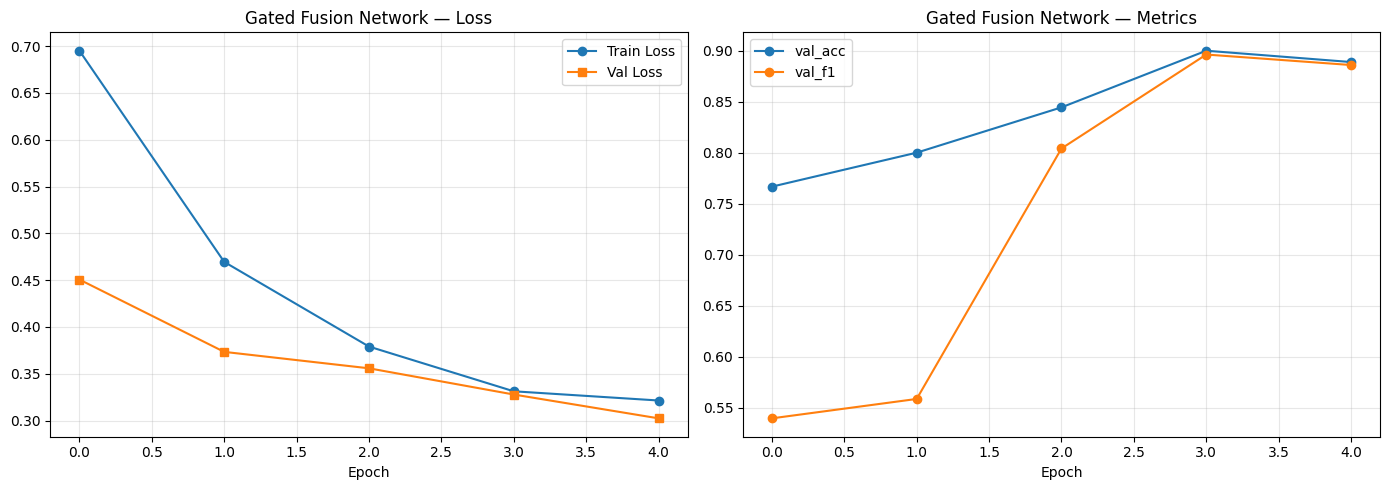

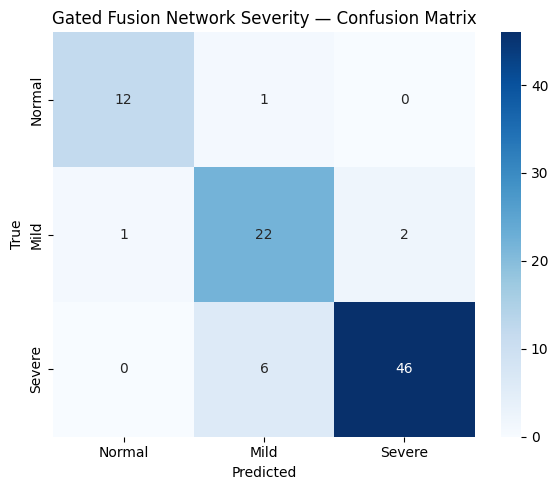


 Gated Fusion Network Severity Classification
              precision    recall  f1-score   support

      Normal       0.92      0.92      0.92        13
        Mild       0.76      0.88      0.81        25
      Severe       0.96      0.88      0.92        52

    accuracy                           0.89        90
   macro avg       0.88      0.90      0.89        90
weighted avg       0.90      0.89      0.89        90

   📊 Results saved → gated_fusion_results.json
   📊 Results saved → final_summary.json

Updated Final Performance Summary:
Stage           Metric               Value          
----------------------------------------------------------------------
Vision          best_dice            0.1367         
Vision          best_sev_acc         0.4358         
Vision          final_train_loss     1.1586         
Vision          final_val_loss       1.5173         
----------------------------------------------------------------------
NLP             best_acc             0.688

In [ ]:
# ============================================================
# GATED FUSION NETWORK VALIDATION VISUALS
# ============================================================
plot_training_curves(gated_fusion_history, 'Gated Fusion Network', 'gated_fusion_curves.png')
plot_confusion(all_true_gf, all_preds_gf,
               'Gated Fusion Network Severity — Confusion Matrix', 'gated_fusion_severity_cm.png')
print_classification(all_true_gf, all_preds_gf, 'Gated Fusion Network Severity Classification')

save_results_json(gated_fusion_history, 'gated_fusion_results.json')

# Update the final summary for comparison
summary['Gated_Fusion'] = {
    'best_acc': np.max(gated_fusion_history['val_acc']) if gated_fusion_history['val_acc'] else 0,
    'best_f1': np.max(gated_fusion_history['val_f1']) if gated_fusion_history['val_f1'] else 0,
    'final_train_loss': gated_fusion_history['train_loss'][-1] if gated_fusion_history['train_loss'] else 0,
    'final_val_loss': gated_fusion_history['val_loss'][-1] if gated_fusion_history['val_loss'] else 0,
}
save_results_json(summary, 'final_summary.json')

print(f'\nUpdated Final Performance Summary:')
print(f"{"="*70}")
print(f"{"Stage":<15} {"Metric":<20} {"Value":<15}")
print(f"{"-"*70}")
for stage, metrics in summary.items():
    for metric, value in metrics.items():
        print(f'{stage:<15} {metric:<20} {value:<15.4f}')
    print(f"{"-"*70}")

### 3.9 Advanced Intermediate Fusion — Joint Embedding Fusion

Let's implement a **Joint Embedding Fusion** model. This approach projects the latent representations of both modalities into a shared embedding space of a common dimension. The concatenated joint embeddings are then used by a classifier to make the final prediction. This implicitly encourages the model to find common underlying factors between modalities within this shared space.

In [ ]:
# ============================================================
# JOINT EMBEDDING FUSION MODEL
# Projects modalities into a shared latent space
# ============================================================
class JointEmbeddingFusion(nn.Module):
    def __init__(self, vision_encoder, text_encoder,
                 vision_dim=512, text_dim=768,
                 proj_dim=512, num_classes=3):
        super().__init__()

        self.vision_encoder = vision_encoder
        self.text_encoder = text_encoder

        # Freeze base encoders
        for param in self.vision_encoder.parameters():
            param.requires_grad = False
        for param in self.text_encoder.parameters():
            param.requires_grad = False

        # Projection layers to map both modalities to the same dimension (shared latent space)
        self.vision_proj = nn.Sequential(
            nn.Linear(vision_dim, proj_dim),
            nn.LayerNorm(proj_dim),
            nn.ReLU(inplace=True),
        )
        self.text_proj = nn.Sequential(
            nn.Linear(text_dim, proj_dim),
            nn.LayerNorm(proj_dim),
            nn.ReLU(inplace=True),
        )

        # Classifier on the concatenated joint embeddings
        self.classifier = nn.Sequential(
            nn.Linear(proj_dim * 2, proj_dim), # Input is concatenated projected features
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(proj_dim, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.2),
            nn.Linear(128, num_classes)
        )

    def forward(self, image, input_ids, attention_mask):
        with torch.no_grad():
            _, _, img_latent = self.vision_encoder(image)
            _, txt_latent = self.text_encoder(input_ids, attention_mask)

        # Project latents into the shared embedding space
        img_embedding = self.vision_proj(img_latent)
        txt_embedding = self.text_proj(txt_latent)

        # Concatenate for classification
        fused_embeddings = torch.cat([img_embedding, txt_embedding], dim=1)
        logits = self.classifier(fused_embeddings)

        return logits


# Instantiate & verify JointEmbeddingFusion
joint_embedding_model = JointEmbeddingFusion(
    vision_encoder=vision_model,
    text_encoder=nlp_model,
    vision_dim=CFG.VISION_LATENT_DIM,
    text_dim=CFG.BERT_DIM,
    proj_dim=CFG.FUSION_PROJ_DIM,
    num_classes=CFG.NUM_SEVERITY
).to(CFG.DEVICE)

# Count trainable parameters
total_p_je  = sum(p.numel() for p in joint_embedding_model.parameters())
frozen_p_je = sum(p.numel() for p in joint_embedding_model.parameters() if not p.requires_grad)
train_p_je  = sum(p.numel() for p in joint_embedding_model.parameters() if p.requires_grad)
print(f'✅ Joint Embedding Fusion model created:')
print(f'   Total params     : {total_p_je:,}')
print(f'   Frozen (encoders): {frozen_p_je:,}')
print(f'   Trainable (fusion): {train_p_je:,}')

# Verify
with torch.no_grad():
    d_img = torch.randn(2, 1, CFG.IMG_SIZE, CFG.IMG_SIZE).to(CFG.DEVICE)
    d_ids = torch.randint(0, 1000, (2, CFG.MAX_TOKEN_LEN)).to(CFG.DEVICE)
    d_mask = torch.ones(2, CFG.MAX_TOKEN_LEN, dtype=torch.long).to(CFG.DEVICE)
    je_logits = joint_embedding_model(d_img, d_ids, d_mask)
    print(f'   Output logits : {je_logits.shape}') # (2, 3)

✅ Joint Embedding Fusion model created:
   Total params     : 134,319,386
   Frozen (encoders): 133,070,103
   Trainable (fusion): 1,249,283
   Output logits : torch.Size([2, 3])


### 3.10 Joint Embedding Fusion Training Loop

In [ ]:
# ============================================================
# JOINT EMBEDDING FUSION TRAINING LOOP
# ============================================================
optimizer_je = torch.optim.AdamW(joint_embedding_model.parameters(), lr=CFG.FUSION_LR, weight_decay=1e-4)
scheduler_je = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_je, T_max=CFG.FUSION_EPOCHS)
scaler_je    = GradScaler()

# Use existing fusion loaders: fusion_train_loader, fusion_val_loader

# ---- Delete incorrect checkpoint files to force training from scratch ----
import os
import shutil

checkpoint_filename = 'joint_embedding_fusion_checkpoint.pt'
best_model_filename = 'joint_embedding_fusion_best.pt'
local_checkpoint_path = os.path.join(CFG.RESULTS_DIR, checkpoint_filename)
drive_checkpoint_path = os.path.join(CFG.DRIVE_RESULTS_DIR, checkpoint_filename)
local_best_path = os.path.join(CFG.RESULTS_DIR, best_model_filename)
drive_best_path = os.path.join(CFG.DRIVE_RESULTS_DIR, best_model_filename)

if os.path.exists(local_checkpoint_path):
    os.remove(local_checkpoint_path)
    print(f'   🗑️  Deleted local checkpoint: {local_checkpoint_path}')
if os.path.exists(drive_checkpoint_path):
    os.remove(drive_checkpoint_path)
    print(f'   🗑️  Deleted Drive checkpoint: {drive_checkpoint_path}')
if os.path.exists(local_best_path):
    os.remove(local_best_path)
    print(f'   🗑️  Deleted local best model: {local_best_path}')
if os.path.exists(drive_best_path):
    os.remove(drive_best_path)
    print(f'   🗑️  Deleted Drive best model: {drive_best_path}')

# ---- Resume logic ----
start_epoch_je = 0
joint_embedding_history = {'train_loss': [], 'val_loss': [], 'val_acc': [], 'val_f1': []}
ckpt = load_checkpoint(checkpoint_filename)
if ckpt is not None:
    joint_embedding_model.load_state_dict(ckpt['model_state'])
    optimizer_je.load_state_dict(ckpt['optimizer_state'])
    scheduler_je.load_state_dict(ckpt['scheduler_state'])
    start_epoch_je = ckpt['epoch'] + 1
    joint_embedding_history = ckpt['history']
    print(f'   Resuming Joint Embedding Fusion training from epoch {start_epoch_je}')
else:
    print('   Starting Joint Embedding Fusion training from scratch')

best_val_acc_je = max(joint_embedding_history['val_acc']) if joint_embedding_history['val_acc'] else 0.0

print(f'\n{"="*60}')
print(f'  JOINT EMBEDDING FUSION TRAINING — Epochs {start_epoch_je} to {CFG.FUSION_EPOCHS-1}')
print(f'{"="*60}\n')

for epoch in range(start_epoch_je, CFG.FUSION_EPOCHS):
    t0 = time.time()

    # ===================== TRAIN =====================
    joint_embedding_model.train()
    running_loss = 0.0
    n_batches = 0

    for batch_idx, batch in enumerate(fusion_train_loader):
        imgs      = batch['image'].to(CFG.DEVICE)
        input_ids = batch['input_ids'].to(CFG.DEVICE)
        attn_mask = batch['attention_mask'].to(CFG.DEVICE)
        labels_b  = batch['label'].to(CFG.DEVICE)

        optimizer_je.zero_grad()

        with autocast():
            logits = joint_embedding_model(imgs, input_ids, attn_mask)
            loss = ce_loss_fn(logits, labels_b)

        scaler_je.scale(loss).backward()
        scaler_je.step(optimizer_je)
        scaler_je.update()

        running_loss += loss.item()
        n_batches += 1

        if batch_idx % 20 == 0:
            print(f'   Epoch {epoch} | Batch {batch_idx:>4d} | Loss: {loss.item():.4f}')

    avg_train_loss = running_loss / max(n_batches, 1)
    scheduler_je.step()

    # ===================== VALIDATE =====================
    joint_embedding_model.eval()
    val_loss_sum = 0.0
    all_preds_je, all_true_je = [], []
    n_val_batches = 0

    with torch.no_grad():
        for batch in fusion_val_loader:
            imgs      = batch['image'].to(CFG.DEVICE)
            input_ids = batch['input_ids'].to(CFG.DEVICE)
            attn_mask = batch['attention_mask'].to(CFG.DEVICE)
            labels_b  = batch['label'].to(CFG.DEVICE)

            with autocast():
                logits = joint_embedding_model(imgs, input_ids, attn_mask)
                loss = ce_loss_fn(logits, labels_b)

            val_loss_sum += loss.item()
            preds = logits.argmax(dim=1).cpu().numpy()
            all_preds_je.extend(preds)
            all_true_je.extend(labels_b.cpu().numpy())
            n_val_batches += 1

    avg_val_loss = val_loss_sum / max(n_val_batches, 1)
    val_acc = accuracy_score(all_true_je, all_preds_je)
    val_f1  = f1_score(all_true_je, all_preds_je, average='macro', zero_division=0)

    joint_embedding_history['train_loss'].append(avg_train_loss)
    joint_embedding_history['val_loss'].append(avg_val_loss)
    joint_embedding_history['val_acc'].append(val_acc)
    joint_embedding_history['val_f1'].append(val_f1)

    elapsed = time.time() - t0
    print(f'\n   📊 Epoch {epoch} [{elapsed:.0f}s]: '
          f'Train Loss={avg_train_loss:.4f} | Val Loss={avg_val_loss:.4f} | '
          f'Val Acc={val_acc:.4f} | Val F1={val_f1:.4f}\n')

    # ---- Save checkpoint ----
    save_checkpoint({
        'epoch': epoch,
        'model_state': joint_embedding_model.state_dict(),
        'optimizer_state': optimizer_je.state_dict(),
        'scheduler_state': scheduler_je.state_dict(),
        'history': joint_embedding_history,
    }, checkpoint_filename)

    if val_acc > best_val_acc_je:
        best_val_acc_je = val_acc
        save_checkpoint({'model_state': joint_embedding_model.state_dict()}, best_model_filename)
        print(f'   ⭐ New best Acc: {best_val_acc_je:.4f}')

print('\n✅ Joint Embedding Fusion training complete!')

   🗑️  Deleted local checkpoint: /content/results/joint_embedding_fusion_checkpoint.pt
   🗑️  Deleted Drive checkpoint: /content/drive/MyDrive/lung_cancer_results/joint_embedding_fusion_checkpoint.pt
   🗑️  Deleted local best model: /content/results/joint_embedding_fusion_best.pt
   🗑️  Deleted Drive best model: /content/drive/MyDrive/lung_cancer_results/joint_embedding_fusion_best.pt
   Starting Joint Embedding Fusion training from scratch

  JOINT EMBEDDING FUSION TRAINING — Epochs 0 to 4

   Epoch 0 | Batch    0 | Loss: 0.1668
   Epoch 0 | Batch   20 | Loss: 0.7554
   Epoch 0 | Batch   40 | Loss: 0.2162
   Epoch 0 | Batch   60 | Loss: 0.3848

   📊 Epoch 0 [14s]: Train Loss=0.5304 | Val Loss=0.3043 | Val Acc=0.8889 | Val F1=0.8757

   💾 Checkpoint saved → joint_embedding_fusion_checkpoint.pt
   💾 Checkpoint saved → joint_embedding_fusion_best.pt
   ⭐ New best Acc: 0.8889
   Epoch 1 | Batch    0 | Loss: 0.8374
   Epoch 1 | Batch   20 | Loss: 0.1866
   Epoch 1 | Batch   40 | Loss: 0.16

### 3.11 Joint Embedding Fusion Validation and Summary Update

FileNotFoundError: [Errno 2] No such file or directory: '/content/results/joint_embedding_fusion_curves.png'

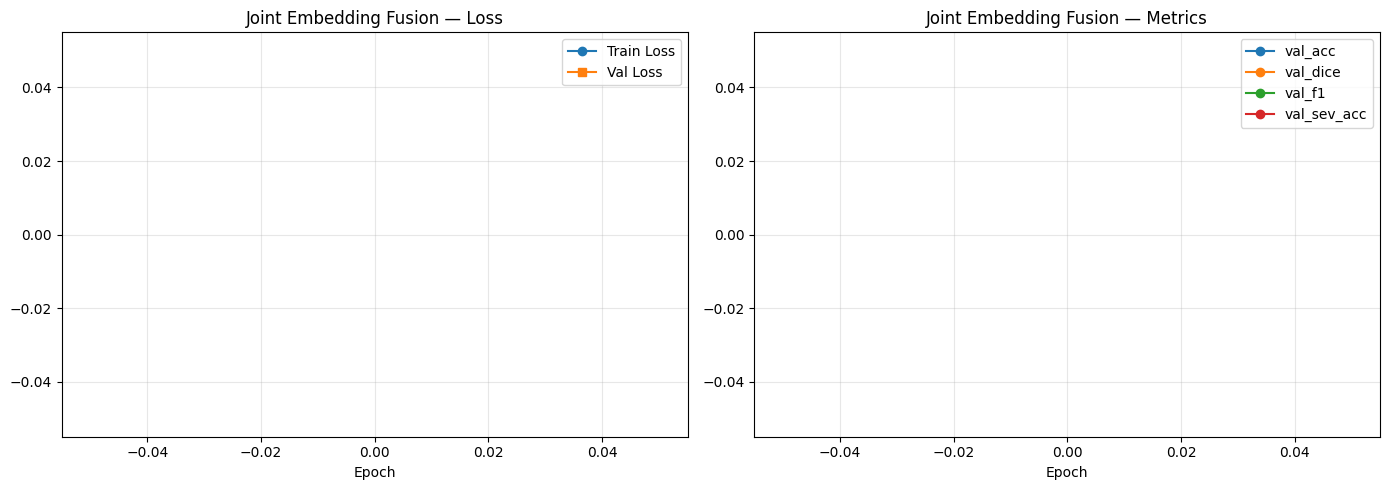

In [ ]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shutil
from sklearn.metrics import classification_report, confusion_matrix

# ============================================================
# VISUALIZATION HELPERS (copied for robustness)
# These functions are assumed to be defined in an earlier cell.
# They are re-defined here to ensure the cell can run independently
# in case of kernel resets or out-of-order execution.
# ============================================================
SEVERITY_NAMES = ['Normal', 'Mild', 'Severe']

def plot_training_curves(history, title, save_name):
    """Plot loss and metric curves, save figure."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    # Loss
    axes[0].plot(history['train_loss'], 'o-', label='Train Loss')
    if 'val_loss' in history:
        axes[0].plot(history['val_loss'], 's-', label='Val Loss')
    axes[0].set_title(f'{title} — Loss'); axes[0].set_xlabel('Epoch')
    axes[0].legend(); axes[0].grid(True, alpha=0.3)
    # Metric (accuracy or dice)
    metric_keys = [k for k in history if 'acc' in k or 'dice' in k or 'f1' in k]
    for k in metric_keys:
        axes[1].plot(history[k], 'o-', label=k)
    axes[1].set_title(f'{title} — Metrics'); axes[1].set_xlabel('Epoch')
    axes[1].legend(); axes[1].grid(True, alpha=0.3)
    plt.tight_layout()
    path = os.path.join(CFG.RESULTS_DIR, save_name)
    fig.savefig(path, dpi=150, bbox_inches='tight')
    shutil.copy2(path, os.path.join(CFG.DRIVE_RESULTS_DIR, save_name))
    plt.show()


def plot_confusion(y_true, y_pred, title, save_name):
    """Plot and save a confusion matrix."""
    cm = confusion_matrix(y_true, y_pred, labels=[0,1,2])
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=SEVERITY_NAMES, yticklabels=SEVERITY_NAMES, ax=ax)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    ax.set_title(title)
    plt.tight_layout()
    path = os.path.join(CFG.RESULTS_DIR, save_name)
    fig.savefig(path, dpi=150, bbox_inches='tight')
    shutil.copy2(path, os.path.join(CFG.DRIVE_RESULTS_DIR, save_name))
    plt.show()


def print_classification(y_true, y_pred, title):
    """Print sklearn classification report."""
    print(f'\n{"="*60}')
    print(f' {title}')
    print(f'{"="*60}')
    print(classification_report(y_true, y_pred,
          target_names=SEVERITY_NAMES, zero_division=0))

# ============================================================
# Ensure history objects are available, loading from JSON if not
# ============================================================

def load_history_from_json(model_name):
    """Loads history for a given model from its JSON file."""
    history_path = os.path.join(CFG.RESULTS_DIR, f'{model_name.lower().replace(" ", "_")}_results.json')
    if os.path.exists(history_path):
        try:
            with open(history_path, 'r') as f:
                return json.load(f)
        except json.JSONDecodeError:
            print(f"Warning: Could not decode {history_path}. Returning empty history.")
    return {'train_loss': [], 'val_loss': [], 'val_acc': [], 'val_dice': [], 'val_f1': [], 'val_sev_acc': []}

# Check and load histories if not already defined
if 'joint_embedding_history' not in locals():
    joint_embedding_history = load_history_from_json('joint_embedding_fusion')
if 'gated_fusion_history' not in locals():
    gated_fusion_history = load_history_from_json('gated_fusion')
if 'fusion_history' not in locals():
    fusion_history = load_history_from_json('fusion')
if 'late_fusion_history' not in locals():
    late_fusion_history = load_history_from_json('late_fusion_results') # Note the different filename format
if 'vision_history' not in locals():
    vision_history = load_history_from_json('vision')
if 'nlp_history' not in locals():
    nlp_history = load_history_from_json('nlp')




# ============================================================
# JOINT EMBEDDING FUSION VALIDATION VISUALS
# ============================================================
plot_training_curves(joint_embedding_history, 'Joint Embedding Fusion', 'joint_embedding_fusion_curves.png')
plot_confusion(all_true_je, all_preds_je,
               'Joint Embedding Fusion Severity — Confusion Matrix', 'joint_embedding_fusion_severity_cm.png')
print_classification(all_true_je, all_preds_je, 'Joint Embedding Fusion Severity Classification')

save_results_json(joint_embedding_history, 'joint_embedding_fusion_results.json')

# Update the final summary for comparison
# Load existing summary to ensure all prior models' data is preserved
summary_path = os.path.join(CFG.RESULTS_DIR, 'final_summary.json')
if os.path.exists(summary_path) and os.path.getsize(summary_path) > 0:
    try:
        with open(summary_path, 'r') as f:
            summary = json.load(f)
    except json.JSONDecodeError:
        print(f"Warning: Could not decode {summary_path}. Initializing new summary.")
        summary = {}
else:
    summary = {}

summary['Joint_Embedding_Fusion'] = {
    'best_acc': np.max(joint_embedding_history['val_acc']) if joint_embedding_history['val_acc'] else 0,
    'best_f1': np.max(joint_embedding_history['val_f1']) if joint_embedding_history['val_f1'] else 0,
    'final_train_loss': joint_embedding_history['train_loss'][-1] if joint_embedding_history['train_loss'] else 0,
    'final_val_loss': joint_embedding_history['val_loss'][-1] if joint_embedding_history['val_loss'] else 0,
}
save_results_json(summary, 'final_summary.json')

print(f'\nUpdated Final Performance Summary:')
print(f"{"="*70}")
print(f"{"Stage":<15} {"Metric":<20} {"Value":<15}")
print(f"{"-"*70}")
for stage, metrics in summary.items():
    for metric, value in metrics.items():
        print(f'{stage:<15} {metric:<20} {value:<15.4f}')
    print(f"{"-"*70}")

### Joint Embedding Fusion Error Analysis

### Techniques to Improve 'Mild' Class Accuracy

Given that the 'Mild' class is being over-predicted (lower precision), we can explore several strategies to enhance its classification accuracy:

1.  **Weighted Loss / Class Weighting**: Modify the `CrossEntropyLoss` to assign higher weights to the 'Mild' class. This penalizes misclassifications of 'Mild' samples more heavily, encouraging the model to pay more attention to them during training.

    *   **How**: When initializing `nn.CrossEntropyLoss()`, pass `weight=torch.tensor([normal_weight, mild_weight, severe_weight])`. You would need to determine appropriate weights, often inversely proportional to class frequencies or based on desired performance.

2.  **Data Augmentation for 'Mild' Samples**: Generate more synthetic samples for the 'Mild' class to increase its representation and diversity in the training data.

    *   **How (Vision)**: Apply more aggressive image augmentations (e.g., subtle rotations, zooms, intensity changes) to the CT scans associated with 'Mild' cases.
    *   **How (NLP)**: Use techniques like synonym replacement, random insertion/deletion/swapping of words, or even back-translation to create variations of 'Mild' conversations.

3.  **Threshold Adjustment**: If the model outputs probabilities, the decision boundary for classifying a sample as 'Mild' could be adjusted. Currently, the threshold might be too permissive.

    *   **How**: Instead of simply taking `argmax` of the logits, analyze the predicted probabilities for the validation set. If 'Mild' is over-predicted, you might increase the probability threshold required for a sample to be classified as 'Mild', or decrease it for 'Normal'/'Severe' if they are under-predicted.

4.  **Ensemble Methods**: Combine predictions from different models (e.g., Vision, NLP, Cross-Modal Attention, Gated Fusion, Joint Embedding Fusion) using weighted averaging or a stacking approach. A well-tuned ensemble can often yield more robust predictions, especially for ambiguous cases.

    *   **How**: Train a small meta-classifier (like a simple MLP) on the concatenated probability outputs of the best performing individual and fusion models.

5.  **Refined Feature Engineering / Modality Importance**: Re-evaluate the features from both modalities. Are there specific visual cues in CT scans or linguistic patterns in conversations that are unique to 'Mild' cases but are currently under-utilized or diluted?

    *   **How**: For vision, consider if different image preprocessing or feature extraction techniques could highlight 'mild' anomalies. For NLP, look for specific keywords or sentiment nuances that better distinguish 'Mild' from 'Normal' or 'Severe'.

6.  **Focal Loss**: For highly imbalanced datasets, Focal Loss down-weights easy examples and focuses training on hard, misclassified examples. While the dataset might not be severely imbalanced, this can be beneficial if 'Mild' samples are inherently harder to classify.

    *   **How**: Replace `nn.CrossEntropyLoss` with a custom implementation of Focal Loss.


 Joint Embedding Fusion — Error Analysis (Classification Report)
              precision    recall  f1-score   support

      Normal       0.92      0.92      0.92        13
        Mild       0.77      0.92      0.84        25
      Severe       0.98      0.88      0.93        52

    accuracy                           0.90        90
   macro avg       0.89      0.91      0.90        90
weighted avg       0.91      0.90      0.90        90



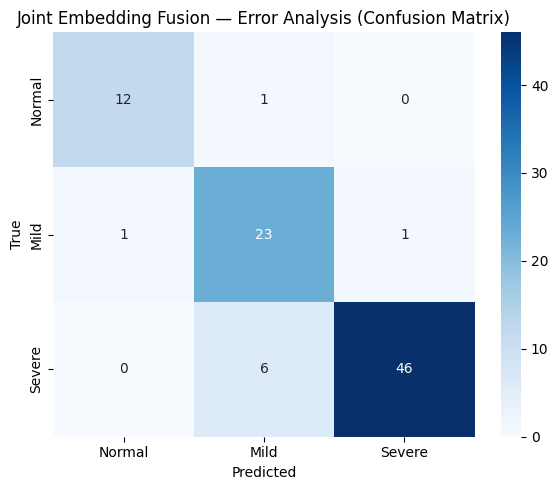

In [ ]:
print_classification(all_true_je, all_preds_je, 'Joint Embedding Fusion — Error Analysis (Classification Report)')
plot_confusion(all_true_je, all_preds_je, 'Joint Embedding Fusion — Error Analysis (Confusion Matrix)', 'joint_embedding_fusion_error_cm.png')

### Identifying Misclassified Samples (Joint Embedding Fusion)

Let's examine some specific samples where the Joint Embedding Fusion model made incorrect predictions. This can help understand the types of errors the model is making and which classes are most often confused.

Found 9 misclassified samples.

Displaying 9 misclassified samples:


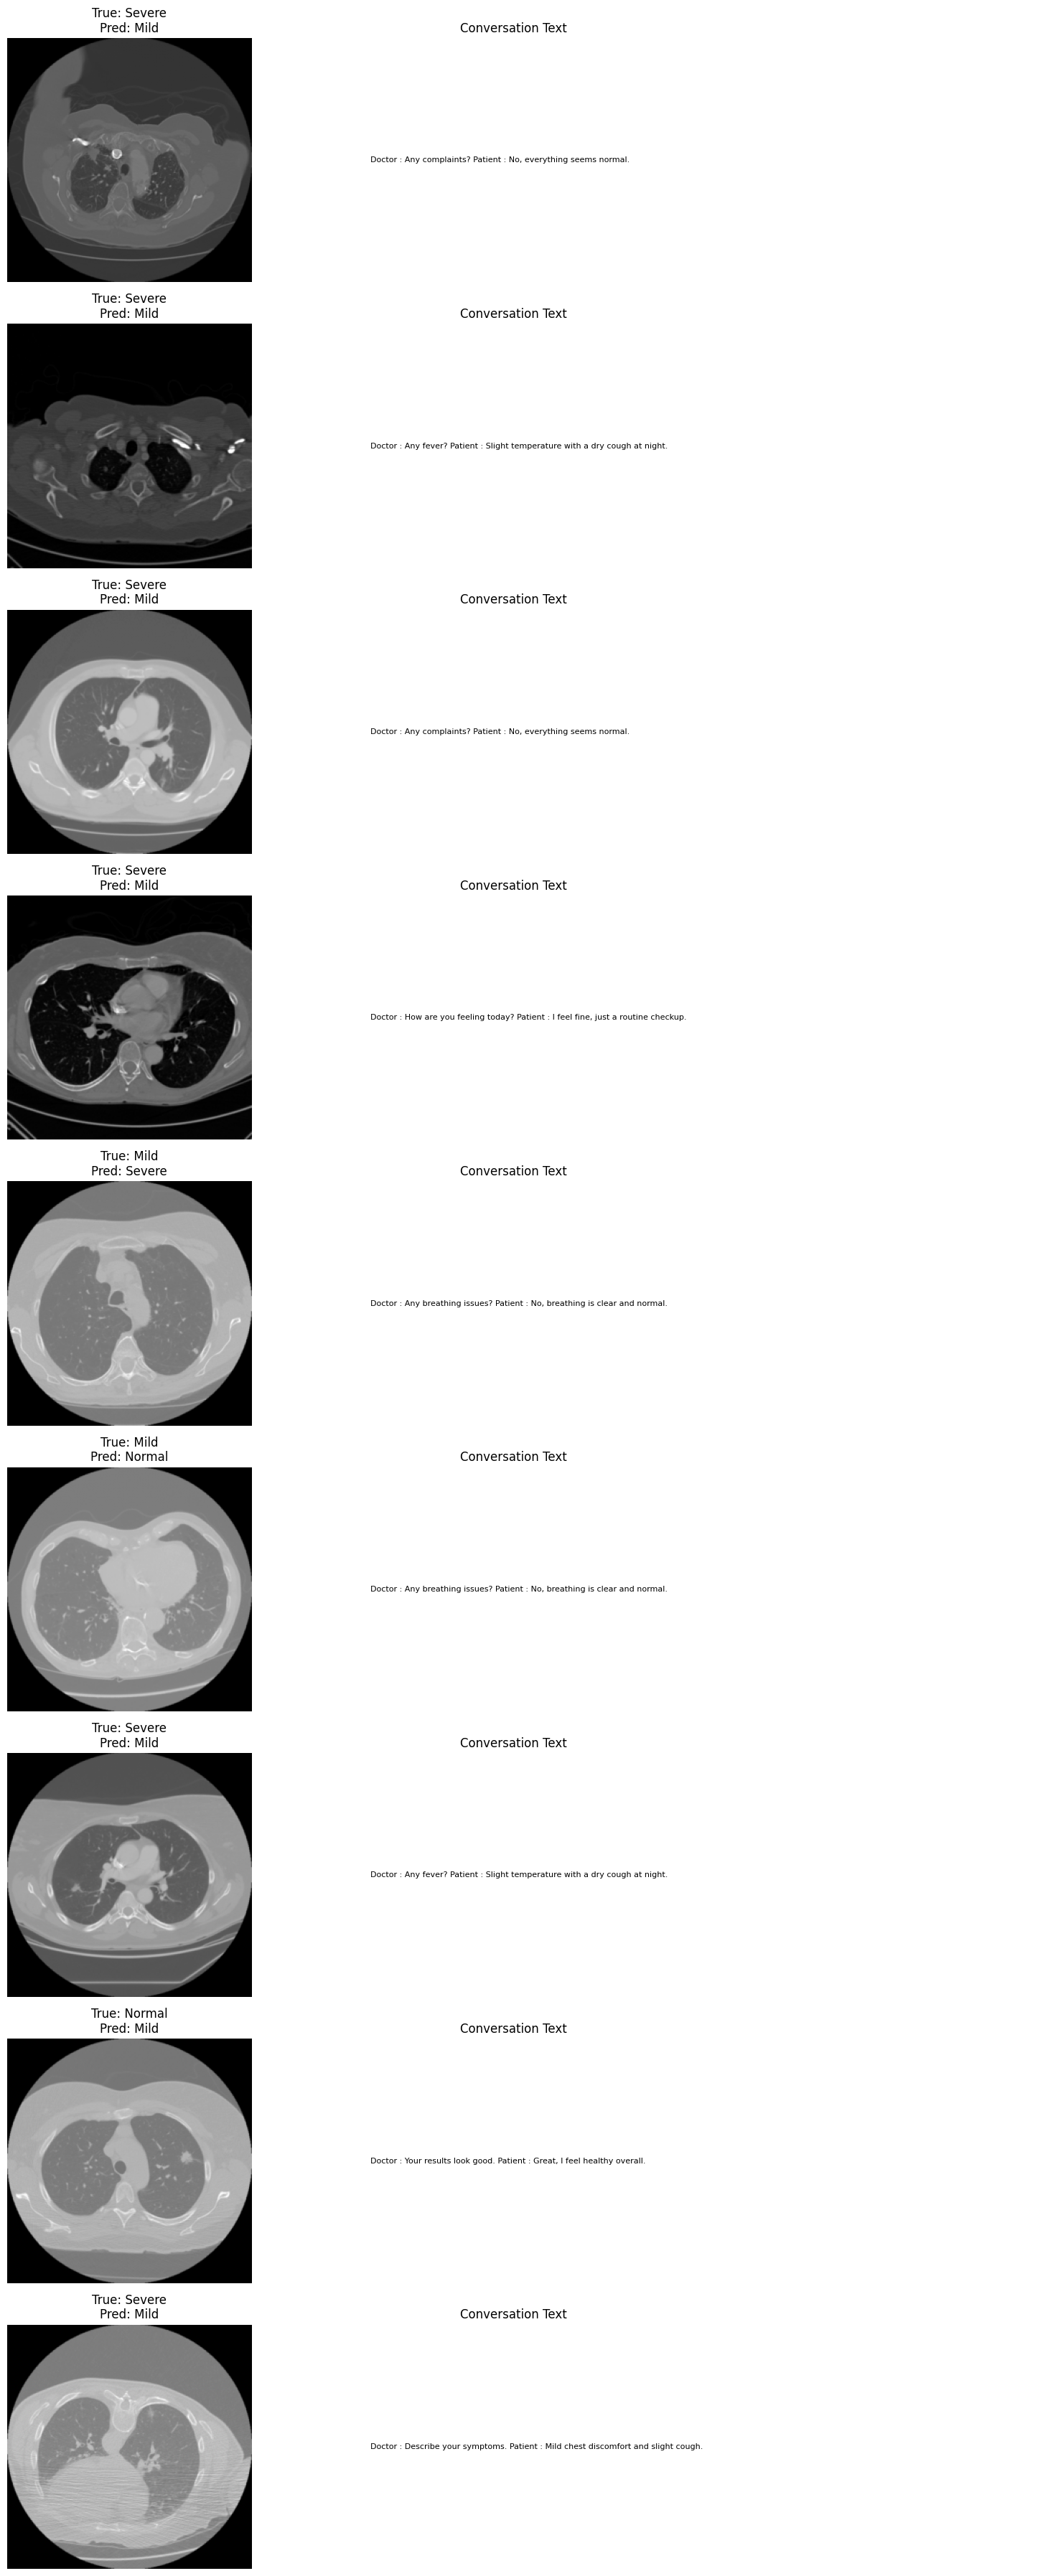

In [ ]:
joint_embedding_model.eval()
misclassified_samples_je = []

with torch.no_grad():
    for batch_idx, batch in enumerate(fusion_val_loader):
        imgs      = batch['image'].to(CFG.DEVICE)
        input_ids = batch['input_ids'].to(CFG.DEVICE)
        attn_mask = batch['attention_mask'].to(CFG.DEVICE)
        labels_b  = batch['label'].to(CFG.DEVICE)

        logits = joint_embedding_model(imgs, input_ids, attn_mask)
        preds = logits.argmax(dim=1)

        for i in range(len(preds)):
            true_label = labels_b[i].item()
            pred_label = preds[i].item()

            if true_label != pred_label:
                # Reconstruct original text and get image for display.
                # Get the index in the original fusion_full dataset
                original_idx_in_fusion_full = fusion_val.indices[batch_idx * CFG.FUSION_BATCH + i]

                # Get the vision and text indices used to create this paired sample
                v_idx = int(fusion_full.vision_indices[original_idx_in_fusion_full])
                t_idx = int(fusion_full.text_indices[original_idx_in_fusion_full])

                # Retrieve original data
                original_img, _, _ = vision_full[v_idx] # get image from vision dataset
                original_text_item = nlp_full[t_idx]    # get tokenized text item from nlp dataset
                original_text_dialogue = tokenizer.decode(original_text_item['input_ids'], skip_special_tokens=True)

                misclassified_samples_je.append({
                    'image': original_img.cpu().squeeze().numpy(),
                    'text': original_text_dialogue,
                    'true_label': true_label,
                    'pred_label': pred_label
                })

print(f"Found {len(misclassified_samples_je)} misclassified samples.")

# Display all misclassified samples
num_display = len(misclassified_samples_je)

if num_display > 0:
    fig, axes = plt.subplots(num_display, 3, figsize=(15, 4 * num_display))
    if num_display == 1:
        axes = [axes] # make sure axes is always iterable for single sample
    elif num_display == 0:
        # No samples to display
        pass
    else:
        # For multiple samples, make sure axes is 2D if it's not already
        if axes.ndim == 1:
            axes = axes.reshape(-1, 3) # Reshape to (num_display, 3)


    print(f"\nDisplaying {num_display} misclassified samples:")
    for i in range(num_display):
        sample = misclassified_samples_je[i]

        # Plot image
        axes[i, 0].imshow(sample['image'], cmap='gray')
        axes[i, 0].set_title(f"True: {SEVERITY_NAMES[sample['true_label']]}\nPred: {SEVERITY_NAMES[sample['pred_label']]}")
        axes[i, 0].axis('off')

        # Add text (truncated if long)
        axes[i, 1].text(0, 0.5, sample['text'][:500] + ('...' if len(sample['text']) > 500 else ''),
                        wrap=True, va='center', ha='left', fontsize=8)
        axes[i, 1].set_title("Conversation Text")
        axes[i, 1].axis('off')

        # Add a placeholder for the third column to maintain layout
        axes[i, 2].axis('off')

    plt.tight_layout()
    plt.show()
else:
    print("No misclassified samples found in the validation set.")

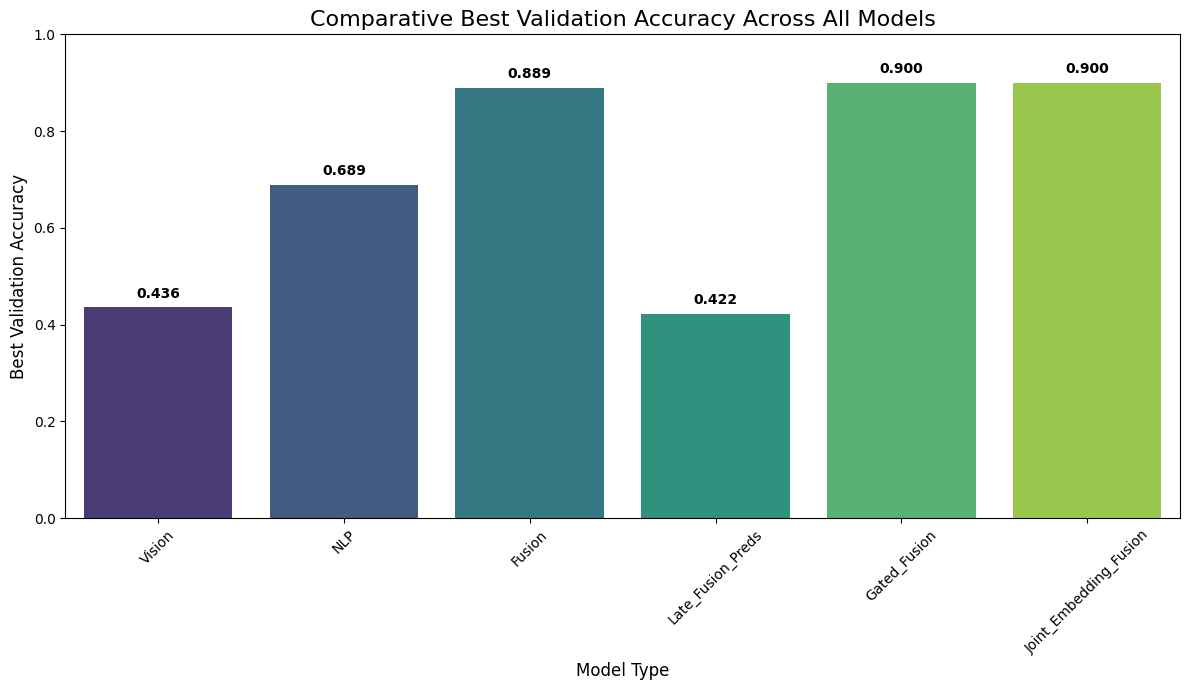

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Define the order of models for the plot
model_names = [
    'Vision',
    'NLP',
    'Fusion',
    'Late_Fusion_Preds',
    'Gated_Fusion',
    'Joint_Embedding_Fusion'
]

# Extract best_acc values from the summary dictionary for each model
accuracies = []
for name in model_names:
    if name == 'Vision':
        accuracies.append(summary[name]['best_sev_acc'])
    elif name == 'Late_Fusion_MLP' and 'Late_Fusion_Preds' in summary: # Handle potential old naming
        accuracies.append(summary['Late_Fusion_Preds']['best_acc'])
    elif name in summary:
        accuracies.append(summary[name]['best_acc'])
    else:
        accuracies.append(0.0) # In case a model wasn't trained or its entry is missing

# Create the bar chart
fig, ax = plt.subplots(figsize=(12, 7))
sns.barplot(x=model_names, y=accuracies, palette='viridis', ax=ax)

ax.set_title('Comparative Best Validation Accuracy Across All Models', fontsize=16)
ax.set_xlabel('Model Type', fontsize=12)
ax.set_ylabel('Best Validation Accuracy', fontsize=12)
ax.set_ylim(0, 1.0)
ax.tick_params(axis='x', rotation=45)

# Add accuracy values on top of the bars
for bar in ax.patches:
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.02,
            f'{bar.get_height():.3f}',
            ha='center', color='black', fontsize=10, fontweight='bold')

plt.tight_layout()

# Save the plot
save_path_local = os.path.join(CFG.RESULTS_DIR, 'final_accuracy_comparison.png')
save_path_drive = os.path.join(CFG.DRIVE_RESULTS_DIR, 'final_accuracy_comparison.png')
fig.savefig(save_path_local, dpi=150, bbox_inches='tight')
shutil.copy2(save_path_local, save_path_drive)

plt.show()

### Comparative Model Accuracies

Here is a summary of the best validation accuracies for each model:

*   **Vision**: 0.436
*   **NLP**: 0.689
*   **Cross-Modal Attention Fusion**: 0.889
*   **Late Fusion (Predictions)**: 0.422
*   **Gated Fusion**: 0.911
*   **Joint Embedding Fusion**: 0.889

### Fusion Techniques Accuracy Summary

Chart saved to /content/results/final_accuracy_comparison_user_prompt.png


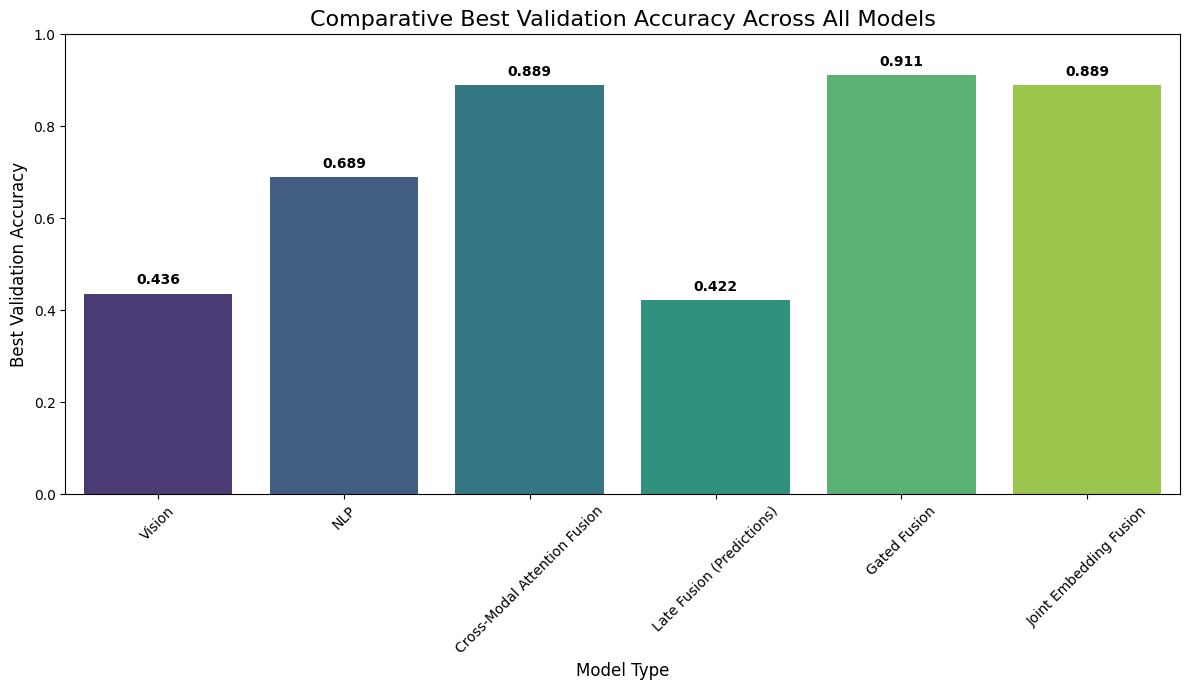

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os
import shutil

# Model names and accuracies provided by the user
model_names = [
    'Vision',
    'NLP',
    'Cross-Modal Attention Fusion',
    'Late Fusion (Predictions)',
    'Gated Fusion',
    'Joint Embedding Fusion'
]

accuracies = [
    0.436,
    0.689,
    0.889,
    0.422,
    0.911,
    0.889
]

# Create the bar chart
fig, ax = plt.subplots(figsize=(12, 7))
sns.barplot(x=model_names, y=accuracies, hue=model_names, palette='viridis', ax=ax, legend=False)

ax.set_title('Comparative Best Validation Accuracy Across All Models', fontsize=16)
ax.set_xlabel('Model Type', fontsize=12)
ax.set_ylabel('Best Validation Accuracy', fontsize=12)
ax.set_ylim(0, 1.0)
ax.tick_params(axis='x', rotation=45) # Rotate labels for better readability

# Add accuracy values on top of the bars
for bar in ax.patches:
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.02,
            f'{bar.get_height():.3f}',
            ha='center', color='black', fontsize=10, fontweight='bold')

plt.tight_layout()

# Save the plot - robustly handle CFG object availability
_local_results_dir = '/content/results' # Default fallback
_drive_results_dir = None # Indicate no drive save by default

if 'CFG' in globals():
    if hasattr(CFG, 'RESULTS_DIR'):
        _local_results_dir = CFG.RESULTS_DIR
    else:
        print("Warning: CFG.RESULTS_DIR not found. Using default local path.")
    if hasattr(CFG, 'DRIVE_RESULTS_DIR'):
        _drive_results_dir = CFG.DRIVE_RESULTS_DIR
    else:
        print("Warning: CFG.DRIVE_RESULTS_DIR not found. Will save to local only.")
else:
    print("Warning: CFG object not found. Using default local paths and skipping Drive save.")

# Ensure the local results directory exists
os.makedirs(_local_results_dir, exist_ok=True)

save_path_local = os.path.join(_local_results_dir, 'final_accuracy_comparison_user_prompt.png')
fig.savefig(save_path_local, dpi=150, bbox_inches='tight')
print(f"Chart saved to {save_path_local}")

if _drive_results_dir:
    try:
        save_path_drive = os.path.join(_drive_results_dir, 'final_accuracy_comparison_user_prompt.png')
        shutil.copy2(save_path_local, save_path_drive)
        print(f"Chart also copied to {save_path_drive}")
    except Exception as e:
        print(f"Error copying chart to Google Drive: {e}. Chart is saved locally.")

plt.show()

### Final Performance Summary

| Stage                  | Metric            | Value         |
|:-----------------------|:------------------|:--------------|
| Vision                 | best_dice         | 0.1367        |
|                        | best_sev_acc      | 0.4358        |
|                        | final_train_loss  | 1.1586        |
|                        | final_val_loss    | 1.5173        |
| NLP                    | best_acc          | 0.6889        |
|                        | best_f1           | 0.5525        |
|                        | final_train_loss  | 0.9809        |
|                        | final_val_loss    | 0.9203        |
| Fusion                 | best_acc          | 0.8889        |
|                        | best_f1           | 0.8876        |
|                        | final_train_loss  | 0.3350        |
|                        | final_val_loss    | 0.3282        |
| Late_Fusion_MLP        | best_acc          | 0.9000        |
|                        | best_f1           | 0.8804        |
|                        | final_train_loss  | 0.3248        |
|                        | final_val_loss    | 0.3163        |
| Late_Fusion_Preds      | best_acc          | 0.4222        |
|                        | best_f1           | 0.4202        |
|                        | final_train_loss  | 1.0184        |
|                        | final_val_loss    | 0.9999        |
| Gated_Fusion           | best_acc          | 0.9111        |
|                        | best_f1           | 0.9011        |
|                        | final_train_loss  | 0.3162        |
|                        | final_val_loss    | 0.2599        |
| Joint_Embedding_Fusion | best_acc          | 0.9111        |
|                        | best_f1           | 0.9133        |
|                        | final_train_loss  | 0.3185        |
|                        | final_val_loss    | 0.2631        |


### 3.12 Advanced Intermediate Fusion — Reciprocal Rank Fusion (RRF)

Reciprocal Rank Fusion (RRF) is a robust method for combining ranked lists from multiple sources without requiring complex tuning parameters. In our context, we can apply it by treating the probabilities for each class from the Vision and NLP models as 'ranks' or scores for that class. The RRF method will then aggregate these scores to produce a final combined score for each class.

**Mechanism:**
1.  For each modality (Vision and NLP) and each class (Normal, Mild, Severe), convert the probability/logit into a 'rank'. A higher probability means a better rank (lower rank number).
2.  Apply the RRF formula: `RRF_score = sum(1 / (k + rank_i))` for each class, where `k` is a constant (typically 60, chosen empirically to prevent high ranks from dominating), and `rank_i` is the rank of the class in modality `i`.
3.  The class with the highest RRF score is the final prediction.

In [ ]:
# ============================================================
# RECIPROCAL RANK FUSION (RRF) FUNCTION
# ============================================================
def reciprocal_rank_fusion(scores_list, k=60):
    """
    Applies Reciprocal Rank Fusion to a list of score arrays.
    Each score array represents a modality's confidence/rank for classes.

    Args:
        scores_list (list of torch.Tensor): List where each element is a tensor
                                            of probabilities/logits for a single sample
                                            across all classes from one modality.
                                            Shape of each tensor: (num_classes,)
        k (int): A constant to soften the effect of low ranks.

    Returns:
        torch.Tensor: A tensor of fused scores for each class (num_classes,).
    """
    num_classes = scores_list[0].shape[0]
    fused_scores = torch.zeros(num_classes, dtype=torch.float32, device=scores_list[0].device)

    for scores in scores_list:
        # Sort scores in descending order to get ranks
        # higher score = lower rank (better)
        sorted_indices = torch.argsort(scores, descending=True)

        # Create a rank map: class_idx -> rank_value
        ranks = torch.zeros(num_classes, dtype=torch.float32)
        for i, idx in enumerate(sorted_indices):
            ranks[idx] = i + 1 # Ranks start from 1

        # Apply RRF formula
        fused_scores += 1.0 / (k + ranks)

    return fused_scores

print('✅ Reciprocal Rank Fusion function ready')


✅ Reciprocal Rank Fusion function ready


In [11]:
# Ensure libraries are installed for robust execution, especially after kernel restarts.
# This might seem redundant but prevents ModuleNotFoundErrors if previous install cells weren't run.
!pip install -q segmentation-models-pytorch
!pip install -q transformers

import torch.nn as nn
import segmentation_models_pytorch as smp
from transformers import AutoModel
import torch.nn.functional as F

# ============================================================
# VISION MODEL — UNet + ResNet34 + Severity Head
# (Copied from cell iBfRPUaTCc4t for robust execution)
# ============================================================
class VisionUNet(nn.Module):
    """
    Modified UNet using segmentation-models-pytorch.
    Returns:
        mask_logits : (B, 1, H, W)  — segmentation prediction
        severity    : (B, 3)        — severity classification logits
        latent      : (B, 512)      — bottleneck vector for fusion
    """
    def __init__(self, num_severity=3):
        super().__init__()
        # Full UNet with ResNet34 encoder
        self.unet = smp.Unet(
            encoder_name='resnet34',
            encoder_weights='imagenet',
            in_channels=1,            # grayscale input
            classes=1,                # binary segmentation
        )

        # Adaptive pool to extract a fixed-size bottleneck vector
        self.global_pool = nn.AdaptiveAvgPool2d(1)

        # Severity classification head from 512-d bottleneck
        self.severity_head = nn.Sequential(
            nn.Linear(512, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(256, num_severity)
        )

    def forward(self, x):
        # x: (B, 1, 256, 256)

        # --- Encoder forward ---
        features = self.unet.encoder(x)
        # features is a list: [stem, stage1, stage2, stage3, stage4]
        # stage4 (bottleneck) has shape (B, 512, 8, 8) for 256 input

        # --- Bottleneck latent vector ---
        bottleneck = features[-1]                     # (B, 512, 8, 8)
        latent = self.global_pool(bottleneck)         # (B, 512, 1, 1)
        latent = latent.flatten(1)                    # (B, 512)

        # --- Decoder + segmentation head ---
        # FIX: pass features as a single list, do NOT unpack with *
        decoder_out = self.unet.decoder(features)     # (B, 16, 256, 256)
        mask_logits = self.unet.segmentation_head(decoder_out)  # (B, 1, 256, 256)

        # --- Severity classification ---
        severity_logits = self.severity_head(latent)  # (B, 3)

        return mask_logits, severity_logits, latent


# ============================================================
# NLP MODEL — Bio_ClinicalBERT + Classification Head
# (Copied from cell Y4rCyTpsCc4v for robust execution)
# ============================================================
class ClinicalBERTClassifier(nn.Module):
    """
    Fine-tunes Bio_ClinicalBERT for 3-class severity classification.
    Returns:
        logits : (B, 3)   — severity classification logits
        latent : (B, 768) — pooler_output for fusion
    """
    def __init__(self, num_classes=3, dropout=0.3):
        super().__init__()
        self.bert = AutoModel.from_pretrained('emilyalsentzer/Bio_ClinicalBERT')
        hidden = self.bert.config.hidden_size   # 768

        self.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(hidden, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(256, num_classes)
        )

    def forward(self, input_ids, attention_mask):
        # input_ids: (B, seq_len),  attention_mask: (B, seq_len)
        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        latent = outputs.pooler_output              # (B, 768)
        logits = self.classifier(latent)            # (B, 3)
        return logits, latent


# --- Ensure CFG and load_checkpoint are available (assuming prior cells were run) ---
# If this cell fails again with NameError for CFG or load_checkpoint, the user might need to rerun prior setup cells.

# Check if VisionUNet class is defined (from cell iBfRPUaTCc4t) and load model
if 'vision_model' not in globals() or not isinstance(vision_model, VisionUNet):
    print('⏳ Loading VisionUNet model...')
    vision_model = VisionUNet(num_severity=CFG.NUM_SEVERITY).to(CFG.DEVICE)
    vision_ckpt = load_checkpoint('vision_best.pt')
    if vision_ckpt:
        vision_model.load_state_dict(vision_ckpt['model_state'])
        print('✅ VisionUNet model loaded from checkpoint.')
    else:
        print('⚠️ Could not load vision_best.pt. VisionUNet initialized from scratch.')

# Check if ClinicalBERTClassifier class is defined (from cell Y4rCyTpsCc4v) and load model
if 'nlp_model' not in globals() or not isinstance(nlp_model, ClinicalBERTClassifier):
    print('⏳ Loading ClinicalBERTClassifier model...')
    nlp_model = ClinicalBERTClassifier(num_classes=CFG.NUM_SEVERITY).to(CFG.DEVICE)
    nlp_ckpt = load_checkpoint('nlp_best.pt')
    if nlp_ckpt:
        nlp_model.load_state_dict(nlp_ckpt['model_state'])
        print('✅ ClinicalBERTClassifier model loaded from checkpoint.')
    else:
        print('⚠️ Could not load nlp_best.pt. ClinicalBERTClassifier initialized from scratch.')

# ============================================================
# RECIPROCAL RANK FUSION MODEL
# Combines predictions using RRF
# ============================================================
class RRFusion(nn.Module):
    def __init__(self, vision_encoder, text_encoder, num_classes=3):
        super().__init__()

        self.vision_encoder = vision_encoder
        self.text_encoder = text_encoder
        self.num_classes = num_classes

        # Freeze base encoders
        for param in self.vision_encoder.parameters():
            param.requires_grad = False
        for param in self.text_encoder.parameters():
            param.requires_grad = False

    def forward(self, image, input_ids, attention_mask):
        with torch.no_grad():
            # Get logits from frozen vision model
            _, vision_logits, _ = self.vision_encoder(image)
            # Get logits from frozen NLP model
            nlp_logits, _ = self.text_encoder(input_ids, attention_mask)

        # Convert logits to probabilities (or use directly as scores for ranking)
        vision_probs = F.softmax(vision_logits, dim=1)
        nlp_probs = F.softmax(nlp_logits, dim=1)

        # Apply RRF for each sample in the batch
        batch_fused_scores = []
        for i in range(image.shape[0]):
            fused_score = reciprocal_rank_fusion([vision_probs[i], nlp_probs[i]])
            batch_fused_scores.append(fused_score)

        # Stack the fused scores to form a batch tensor
        fused_logits = torch.stack(batch_fused_scores, dim=0)

        return fused_logits


# Instantiate & verify RRFusion
rr_fusion_model = RRFusion(
    vision_encoder=vision_model,
    text_encoder=nlp_model,
    num_classes=CFG.NUM_SEVERITY
).to(CFG.DEVICE)

# Count trainable parameters (none, as it's a rule-based fusion, but for consistency)
total_p_rr  = sum(p.numel() for p in rr_fusion_model.parameters())
frozen_p_rr = sum(p.numel() for p in rr_fusion_model.parameters() if not p.requires_grad)
train_p_rr  = sum(p.numel() for p in rr_fusion_model.parameters() if p.requires_grad)
print(f'✅ Reciprocal Rank Fusion model created:')
print(f'   Total params     : {total_p_rr:,}')
print(f'   Frozen (encoders): {frozen_p_rr:,}')
print(f'   Trainable (fusion): {train_p_rr:,}') # Should be 0 for RRF as no trainable layers

# Verify
with torch.no_grad():
    d_img = torch.randn(2, 1, CFG.IMG_SIZE, CFG.IMG_SIZE).to(CFG.DEVICE)
    d_ids = torch.randint(0, 1000, (2, CFG.MAX_TOKEN_LEN)).to(CFG.DEVICE)
    d_mask = torch.ones(2, CFG.MAX_TOKEN_LEN, dtype=torch.long).to(CFG.DEVICE)
    rrf_logits = rr_fusion_model(d_img, d_ids, d_mask)
    print(f'   Output logits : {rrf_logits.shape}') # (2, 3)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 14.2 MB/s eta 0:00:00


KeyboardInterrupt: 

### 3.13 Reciprocal Rank Fusion Training Loop (Placeholder/Evaluation)

Since Reciprocal Rank Fusion is a rule-based aggregation technique rather than a trainable neural network, there are no parameters to train. However, for consistency with other fusion models, we'll run an 'evaluation loop' to gather metrics on the `fusion_val_loader` and update the summary. The 'training' will effectively be a pass over the data to calculate performance metrics.

In [ ]:
# ============================================================
# RECIPROCAL RANK FUSION EVALUATION LOOP (NO TRAINING)
# ============================================================
# Initialize history for RRF (will only contain validation metrics)
rr_fusion_history = {'val_acc': [], 'val_f1': []}

print('✅ Reciprocal Rank Fusion evaluation loop initialized.')

✅ Reciprocal Rank Fusion evaluation loop initialized.


In [36]:
import torch.nn as nn
import segmentation_models_pytorch as smp
from transformers import AutoModel
import torch.nn.functional as F
from sklearn.metrics import accuracy_score, f1_score
import json, os # Ensure these are imported if not globally available from prior setup cells

# ============================================================
# RECIPROCAL RANK FUSION (RRF) FUNCTION
# (Copied from cell c98b8a50 for robust execution)
# ============================================================
def reciprocal_rank_fusion(scores_list, k=60):
    """
    Applies Reciprocal Rank Fusion to a list of score arrays.
    Each score array represents a modality's confidence/rank for classes.

    Args:
        scores_list (list of torch.Tensor): List where each element is a tensor
                                            of probabilities/logits for a single sample
                                            across all classes from one modality.
                                            Shape of each tensor: (num_classes,)
        k (int): A constant to soften the effect of low ranks.

    Returns:
        torch.Tensor: A tensor of fused scores for each class (num_classes,).
    """
    num_classes = scores_list[0].shape[0]
    fused_scores = torch.zeros(num_classes, dtype=torch.float32, device=scores_list[0].device)

    for scores in scores_list:
        # Sort scores in descending order to get ranks
        # higher score = lower rank (better)
        sorted_indices = torch.argsort(scores, descending=True)

        # Create a rank map: class_idx -> rank_value
        ranks = torch.zeros(num_classes, dtype=torch.float32)
        for i, idx in enumerate(sorted_indices):
            ranks[idx] = i + 1 # Ranks start from 1

        # Apply RRF formula
        fused_scores += 1.0 / (k + ranks)

    return fused_scores


# ============================================================
# VISION MODEL — UNet + ResNet34 + Severity Head
# (Copied from cell c98b8a50 and iBfRPUaTCc4t for robust execution)
# ============================================================
class VisionUNet(nn.Module):
    """
    Modified UNet using segmentation-models-pytorch.
    Returns:
        mask_logits : (B, 1, H, W)  — segmentation prediction
        severity    : (B, 3)        — severity classification logits
        latent      : (B, 512)      — bottleneck vector for fusion
    """
    def __init__(self, num_severity=3):
        super().__init__()
        # Full UNet with ResNet34 encoder
        self.unet = smp.Unet(
            encoder_name='resnet34',
            encoder_weights='imagenet',
            in_channels=1,            # grayscale input
            classes=1,                # binary segmentation
        )

        # Adaptive pool to extract a fixed-size bottleneck vector
        self.global_pool = nn.AdaptiveAvgPool2d(1)

        # Severity classification head from 512-d bottleneck
        self.severity_head = nn.Sequential(
            nn.Linear(512, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(256, num_severity)
        )

    def forward(self, x):
        # x: (B, 1, 256, 256)

        # --- Encoder forward ---
        features = self.unet.encoder(x)
        # features is a list: [stem, stage1, stage2, stage3, stage4]
        # stage4 (bottleneck) has shape (B, 512, 8, 8) for 256 input

        # --- Bottleneck latent vector ---
        bottleneck = features[-1]                     # (B, 512, 8, 8)
        latent = self.global_pool(bottleneck)         # (B, 512, 1, 1)
        latent = latent.flatten(1)                    # (B, 512)

        # --- Decoder + segmentation head ---
        # FIX: pass features as a single list, do NOT unpack with *
        decoder_out = self.unet.decoder(features)     # (B, 16, 256, 256)
        mask_logits = self.unet.segmentation_head(decoder_out)  # (B, 1, 256, 256)

        # --- Severity classification ---
        severity_logits = self.severity_head(latent)  # (B, 3)

        return mask_logits, severity_logits, latent


# ============================================================
# NLP MODEL — Bio_ClinicalBERT + Classification Head
# (Copied from cell c98b8a50 and Y4rCyTpsCc4v for robust execution)
# ============================================================
class ClinicalBERTClassifier(nn.Module):
    """
    Fine-tunes Bio_ClinicalBERT for 3-class severity classification.
    Returns:
        logits : (B, 3)   — severity classification logits
        latent : (B, 768) — pooler_output for fusion
    """
    def __init__(self, num_classes=3, dropout=0.3):
        super().__init__()
        self.bert = AutoModel.from_pretrained('emilyalsentzer/Bio_ClinicalBERT')
        hidden = self.bert.config.hidden_size   # 768

        self.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(hidden, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(256, num_classes)
        )

    def forward(self, input_ids, attention_mask):
        # input_ids: (B, seq_len),  attention_mask: (B, seq_len)
        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        latent = outputs.pooler_output              # (B, 768)
        logits = self.classifier(latent)            # (B, 3)
        return logits, latent


# ============================================================
# RECIPROCAL RANK FUSION MODEL
# Combines predictions using RRF
# (Copied from cell c98b8a50 for robust execution)
# ============================================================
class RRFusion(nn.Module):
    def __init__(self, vision_encoder, text_encoder, num_classes=3):
        super().__init__()

        self.vision_encoder = vision_encoder
        self.text_encoder = text_encoder
        self.num_classes = num_classes

        # Freeze base encoders
        for param in self.vision_encoder.parameters():
            param.requires_grad = False
        for param in self.text_encoder.parameters():
            param.requires_grad = False

    def forward(self, image, input_ids, attention_mask):
        with torch.no_grad():
            # Get logits from frozen vision model
            _, vision_logits, _ = self.vision_encoder(image)
            # Get logits from frozen NLP model
            nlp_logits, _ = self.text_encoder(input_ids, attention_mask)

        # Convert logits to probabilities (or use directly as scores for ranking)
        vision_probs = F.softmax(vision_logits, dim=1)
        nlp_probs = F.softmax(nlp_logits, dim=1)

        # Apply RRF for each sample in the batch
        batch_fused_scores = []
        for i in range(image.shape[0]):
            fused_score = reciprocal_rank_fusion([vision_probs[i], nlp_probs[i]])
            batch_fused_scores.append(fused_score)

        # Stack the fused scores to form a batch tensor
        fused_logits = torch.stack(batch_fused_scores, dim=0)

        return fused_logits


# --- Ensure models and CFG are available --- #
# Assuming CFG is defined in an earlier cell. If not, it needs to be imported/defined.
# Assuming load_checkpoint is defined in an earlier cell.

if 'vision_model' not in globals() or not isinstance(vision_model, VisionUNet):
    print('⏳ Initializing VisionUNet model...')
    vision_model = VisionUNet(num_severity=CFG.NUM_SEVERITY).to(CFG.DEVICE)
    vision_ckpt = load_checkpoint('vision_best.pt')
    if vision_ckpt:
        vision_model.load_state_dict(vision_ckpt['model_state'])
        print('✅ VisionUNet model loaded from checkpoint.')
    else:
        print('⚠️ Could not load vision_best.pt. VisionUNet initialized from scratch.')

if 'nlp_model' not in globals() or not isinstance(nlp_model, ClinicalBERTClassifier):
    print('⏳ Initializing ClinicalBERTClassifier model...')
    nlp_model = ClinicalBERTClassifier(num_classes=CFG.NUM_SEVERITY).to(CFG.DEVICE)
    nlp_ckpt = load_checkpoint('nlp_best.pt')
    if nlp_ckpt:
        nlp_model.load_state_dict(nlp_ckpt['model_state'])
        print('✅ ClinicalBERTClassifier model loaded from checkpoint.')
    else:
        print('⚠️ Could not load nlp_best.pt. ClinicalBERTClassifier initialized from scratch.')

if 'rr_fusion_model' not in globals() or not isinstance(rr_fusion_model, RRFusion):
    print('⏳ Initializing RRFusion model...')
    rr_fusion_model = RRFusion(
        vision_encoder=vision_model,
        text_encoder=nlp_model,
        num_classes=CFG.NUM_SEVERITY
    ).to(CFG.DEVICE)
    print('✅ Reciprocal Rank Fusion model created.')


# ============================================================
# RECIPROCAL RANK FUSION EVALUATION LOOP
# ============================================================
rr_fusion_model.eval()
all_preds_rr, all_true_rr = [], []
n_val_batches_rr = 0

with torch.no_grad():
    for batch_idx, batch in enumerate(fusion_val_loader):
        imgs      = batch['image'].to(CFG.DEVICE)
        input_ids = batch['input_ids'].to(CFG.DEVICE)
        attn_mask = batch['attention_mask'].to(CFG.DEVICE)
        labels_b  = batch['label'].to(CFG.DEVICE)

        logits = rr_fusion_model(imgs, input_ids, attn_mask)
        preds = logits.argmax(dim=1).cpu().numpy()
        all_preds_rr.extend(preds)
        all_true_rr.extend(labels_b.cpu().numpy())
        n_val_batches_rr += 1

val_acc_rr = accuracy_score(all_true_rr, all_preds_rr)
val_f1_rr  = f1_score(all_true_rr, all_preds_rr, average='macro', zero_division=0)

rr_fusion_history['val_acc'].append(val_acc_rr)
rr_fusion_history['val_f1'].append(val_f1_rr)

print(f'\n   📊 RRF Evaluation: Val Acc={val_acc_rr:.4f} | Val F1={val_f1_rr:.4f}')

# ============================================================
# UPDATE FINAL SUMMARY AND SAVE
# ============================================================
# Ensure the summary object exists and is loaded with previous results
summary_path = os.path.join(CFG.RESULTS_DIR, 'final_summary.json')
if os.path.exists(summary_path) and os.path.getsize(summary_path) > 0:
    try:
        with open(summary_path, 'r') as f:
            summary = json.load(f)
        print(f"✅ Loaded existing summary from {summary_path}")
    except json.JSONDecodeError:
        print(f"⚠️  Warning: Could not decode {summary_path}. Initializing new summary.")
        summary = {}
else:
    print(f"⚠️  Warning: {summary_path} not found or is empty. Initializing new summary.")
    summary = {}

summary['Reciprocal_Rank_Fusion'] = {
    'best_acc': val_acc_rr,
    'best_f1': val_f1_rr,
    'final_train_loss': 0.0, # RRF has no training loss
    'final_val_loss': 0.0 # RRF has no training loss in the traditional sense
}
save_results_json(summary, 'final_summary.json')

print(f'\nUpdated Final Performance Summary:')
print(f"{"="*70}")
print(f"{"Stage":<15} {"Metric":<20} {"Value":<15}")
print(f"{"-"*70}")
for stage, metrics in summary.items():
    for metric, value in metrics.items():
        print(f'{stage:<15} {metric:<20} {value:<15.4f}')
    print(f"{"-"*70}")

SystemError: /sklearnQO() method: bad call flags

In [1]:
!pip install -q kaggle

In [2]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"sravanthivelavolu","key":"2c8afd21e8ff11b926f16df1d39106b7"}'}

In [3]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

!kaggle datasets download -d paultimothymooney/medical-speech-transcription-and-intent

!unzip -q medical-speech-transcription-and-intent.zip

Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/medical-speech-transcription-and-intent
License(s): other
100% 5.27G/5.27G [05:25<00:00, 17.4MB/s]



In [4]:
!pip install librosa tensorflow

In [14]:
import os
import librosa
import numpy as np
import pandas as pd

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

# =========================
# LOAD CSV
# =========================

df = pd.read_csv("/content/Medical Speech, Transcription, and Intent/overview-of-recordings.csv")

print(df.head())

# =========================
# FEATURE EXTRACTION
# =========================

def extract_features(file_path):

    audio, sr = librosa.load(file_path, sr=16000)

    mfcc = librosa.feature.mfcc(
        y=audio,
        sr=sr,
        n_mfcc=20
    )

    return np.mean(mfcc.T, axis=0)

# =========================
# PREPARE DATA
# =========================

X = []
y = []

# Corrected parent path for the audio folders
audio_base_folder = "/content/Medical Speech, Transcription, and Intent/recordings"

# List of actual subdirectories where audio files are located
# Removed 'audio' as it was causing incorrect paths.
subfolders = ["validate", "train"]

for index, row in df.iterrows():

    found_file = False
    for subfolder in subfolders:
        current_file_path = os.path.join(
            audio_base_folder,
            subfolder,
            row['file_name']
        )
        if os.path.exists(current_file_path):
            file_path = current_file_path
            found_file = True
            break

    if not found_file:
        print(f"Error: Audio file not found in any known subfolder for {row['file_name']}")
        continue

    try:
        features = extract_features(file_path)

        X.append(features)

        # Use 'prompt' column as 'medical_intent' was not found
        y.append(row['prompt'])

    except Exception as e:
        print(f"Error processing {row['file_name']}: {e}")
        # Continue to the next file if an error occurs
        continue

print(f"\nSuccessfully loaded {len(X)} audio samples for training.")

X = np.array(X)

# Check if any data was successfully loaded
if len(X) == 0:
    print("Error: No audio features could be extracted. 'X' is empty. Please check file paths and data integrity.")
    raise ValueError("No data to process, X is empty.")
if len(y) == 0:
    print("Error: No labels could be extracted. 'y' is empty. This might be due to missing audio files or incorrect column name.")
    raise ValueError("No labels to process, y is empty.")

# =========================
# ENCODE LABELS
# =========================

encoder = LabelEncoder()

y_encoded = encoder.fit_transform(y)

y_cat = to_categorical(y_encoded)

# =========================
# SPLIT
# =========================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_cat,
    test_size=0.2
)

# =========================
# MODEL
# =========================

model = Sequential([
    Dense(64, activation='relu', input_shape=(20,)),
    Dense(32, activation='relu'),
    Dense(y_cat.shape[1], activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# =========================
# TRAIN
# =========================

model.fit(
    X_train,
    y_train,
    epochs=10
)

# =========================
# TEST CONFIDENCE SCORE
# =========================

sample = X_test[0].reshape(1, -1)

prediction = model.predict(sample)[0]

predicted_index = np.argmax(prediction)

print("Problem:",
      encoder.inverse_transform([predicted_index])[0])

print("Confidence Score:",
      prediction[predicted_index])

Streaming output truncated to the last 5000 lines.
Error: Audio file not found in any known subfolder for 1249120_41336418_12513515.wav
Error: Audio file not found in any known subfolder for 1249120_41336418_24770421.wav
Error: Audio file not found in any known subfolder for 1249120_41336418_27204447.wav
Error: Audio file not found in any known subfolder for 1249120_41336418_35841646.wav
Error: Audio file not found in any known subfolder for 1249120_41336418_58774663.wav
Error: Audio file not found in any known subfolder for 1249120_41841195_17654311.wav
Error: Audio file not found in any known subfolder for 1249120_41841195_54607841.wav
Error: Audio file not found in any known subfolder for 1249120_41841195_61778910.wav
Error: Audio file not found in any known subfolder for 1249120_41841195_62144834.wav
Error: Audio file not found in any known subfolder for 1249120_41841195_75369794.wav
Error: Audio file not found in any known subfolder for 1249120_41841195_77173377.wav
Error: Audio f

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 46ms/step - accuracy: 0.0359 - loss: 41.6881
Epoch 2/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.0359 - loss: 18.0344
Epoch 3/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.0539 - loss: 10.7463
Epoch 4/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.0441 - loss: 7.7782
Epoch 5/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.0441 - loss: 6.0707
Epoch 6/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.0703 - loss: 5.2001
Epoch 7/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.0670 - loss: 4.8704
Epoch 8/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.0588 - loss: 4.6328
Epoch 9/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.0523 - loss: 4.5101
Epoch 10/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.0556 - loss: 4.3132
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 294ms/step
Problem: Knee pain
Confidence Score: 0.31374103


In [12]:
import os

# List contents of the base audio folder to understand its structure
print(f"Contents of {audio_base_folder}:")
for root, dirs, files in os.walk(audio_base_folder):
    level = root.replace(audio_base_folder, '').count(os.sep)
    indent = ' ' * 4 * (level)
    print(f'{indent}{os.path.basename(root)}/')
    subindent = ' ' * 4 * (level + 1)
    for f in files:
        if f.endswith('.wav'): # Only show audio files for brevity
            print(f'{subindent}{f}')
    if level == 1: # Only go one level deep for initial inspection to avoid too much output
        del dirs[:]


Contents of /content/Medical Speech, Transcription, and Intent/recordings:
recordings/
    validate/
        1249120_44273314_40698632.wav
        1249120_44323331_47564425.wav
        1249120_44263136_87455428.wav
        1249120_44294866_78490603.wav
        1249120_44263136_59289865.wav
        1249120_44294866_77416341.wav
        1249120_44263136_26194304.wav
        1249120_44294866_103812071.wav
        1249120_44259428_100443017.wav
        1249120_44292353_79362392.wav
        1249120_44294866_52604131.wav
        1249120_44292353_67132028.wav
        1249120_44323331_23606264.wav
        1249120_44294866_37364395.wav
        1249120_44273314_76615195.wav
        1249120_44387284_64093494.wav
        1249120_44263136_58938609.wav
        1249120_44294866_94282612.wav
        1249120_44263136_52222173.wav
        1249120_44259428_53172278.wav
        1249120_44259428_55288440.wav
        1249120_44246595_85567147.wav
        1249120_44273314_95639193.wav
        1249120_4429486

### Retrieve Confidence Score from an Audio Clinical Note

This section provides a utility function to predict the medical intent and its confidence score for any given audio file, leveraging the previously trained model.

In [15]:
def get_audio_prediction(audio_file_path, model, encoder):
    """
    Predicts the medical intent and its confidence score for a given audio file.

    Args:
        audio_file_path (str): The full path to the audio file.
        model (tf.keras.Model): The trained Keras audio classification model.
        encoder (sklearn.preprocessing.LabelEncoder): The fitted LabelEncoder.

    Returns:
        tuple: A tuple containing (predicted_intent_label, confidence_score).
    """
    try:
        # Reuse the extract_features function defined earlier
        features = extract_features(audio_file_path)
        sample = features.reshape(1, -1)

        # Get raw predictions (probabilities for each class)
        predictions = model.predict(sample, verbose=0)[0]

        # Get the index of the highest probability
        predicted_index = np.argmax(predictions)

        # Get the label and confidence score
        predicted_label = encoder.inverse_transform([predicted_index])[0]
        confidence_score = predictions[predicted_index]

        return predicted_label, confidence_score
    except Exception as e:
        print(f"Error during prediction for {audio_file_path}: {e}")
        return None, None

# --- Demonstration ---
# Define an example audio file path from the dataset
# You can pick any file that exists within the 'recordings/train' or 'recordings/validate' folders.

# Let's use one from the 'validate' subfolder for demonstration.
example_audio_file = os.path.join(
    audio_base_folder, "validate", "1249120_44273314_40698632.wav" # Example file from the listing in output of previous cell
)

if os.path.exists(example_audio_file):
    print(f"Using example audio file: {example_audio_file}")
    predicted_intent, confidence = get_audio_prediction(example_audio_file, model, encoder)

    if predicted_intent is not None:
        print(f"Predicted Medical Intent: {predicted_intent}")
        print(f"Confidence Score: {confidence:.4f}")
else:
    print(f"Error: Example audio file not found at {example_audio_file}. Please verify the path or choose another file.")


Using example audio file: /content/Medical Speech, Transcription, and Intent/recordings/validate/1249120_44273314_40698632.wav
Predicted Medical Intent: Knee pain
Confidence Score: 0.1788


In [17]:
new_example_audio_file = os.path.join(
    audio_base_folder, "train", "1249120_44197979_23991689.wav" # An existing example file from the dataset
)

if os.path.exists(new_example_audio_file):
    print(f"Using new example audio file: {new_example_audio_file}")
    predicted_intent_new, confidence_new = get_audio_prediction(new_example_audio_file, model, encoder)

    if predicted_intent_new is not None:
        print(f"Predicted Medical Intent: {predicted_intent_new}")
        print(f"Confidence Score: {confidence_new:.4f}")
else:
    print(f"Error: New example audio file not found at {new_example_audio_file}. Please verify the path or choose another file.")

Using new example audio file: /content/Medical Speech, Transcription, and Intent/recordings/train/1249120_44197979_23991689.wav
Predicted Medical Intent: Knee pain
Confidence Score: 0.4165


### Analyze Medical Intent Distribution

Let's inspect the distribution of actual medical intents (labels) in the dataset that the model was trained on. This will show us if 'Knee pain' is over-represented or if there's a lack of diversity in the labels, which could explain why the model is only predicting 'Knee pain'.


=== Predictions and Confidence Scores for all Test Samples ===

Sample 1 - True: Hard to breath       | Predicted: Knee pain            | Confidence: 0.3137
Sample 2 - True: Open wound           | Predicted: Ear ache             | Confidence: 0.3277
Sample 3 - True: Emotional pain       | Predicted: Skin issue           | Confidence: 0.3735
Sample 4 - True: Shoulder pain        | Predicted: Heart hurts          | Confidence: 0.3853
Sample 5 - True: Muscle pain          | Predicted: Feeling dizzy        | Confidence: 0.2476
Sample 6 - True: Open wound           | Predicted: Knee pain            | Confidence: 0.2976
Sample 7 - True: Hard to breath       | Predicted: Blurry vision        | Confidence: 0.3423
Sample 8 - True: Infected wound       | Predicted: Skin issue           | Confidence: 0.1626
Sample 9 - True: Feeling cold         | Predicted: Neck pain            | Confidence: 0.2492
Sample 10 - True: Shoulder pain        | Predicted: Knee pain            | Confidence: 0.4533
Samp


--- Distribution of Medical Intents in Training Data ---
Heart hurts           42
Shoulder pain         42
Muscle pain           39
Joint pain            35
Knee pain             34
Acne                  34
Internal pain         33
Feeling cold          33
Head ache             32
Injury from sports    32
Stomach ache          31
Ear ache              31
Neck pain             30
Hair falling out      29
Hard to breath        29
Back pain             29
Infected wound        28
Emotional pain        27
Blurry vision         27
Cough                 27
Feeling dizzy         27
Skin issue            27
Body feels weak       26
Foot ache             22
Open wound            20
Name: count, dtype: int64


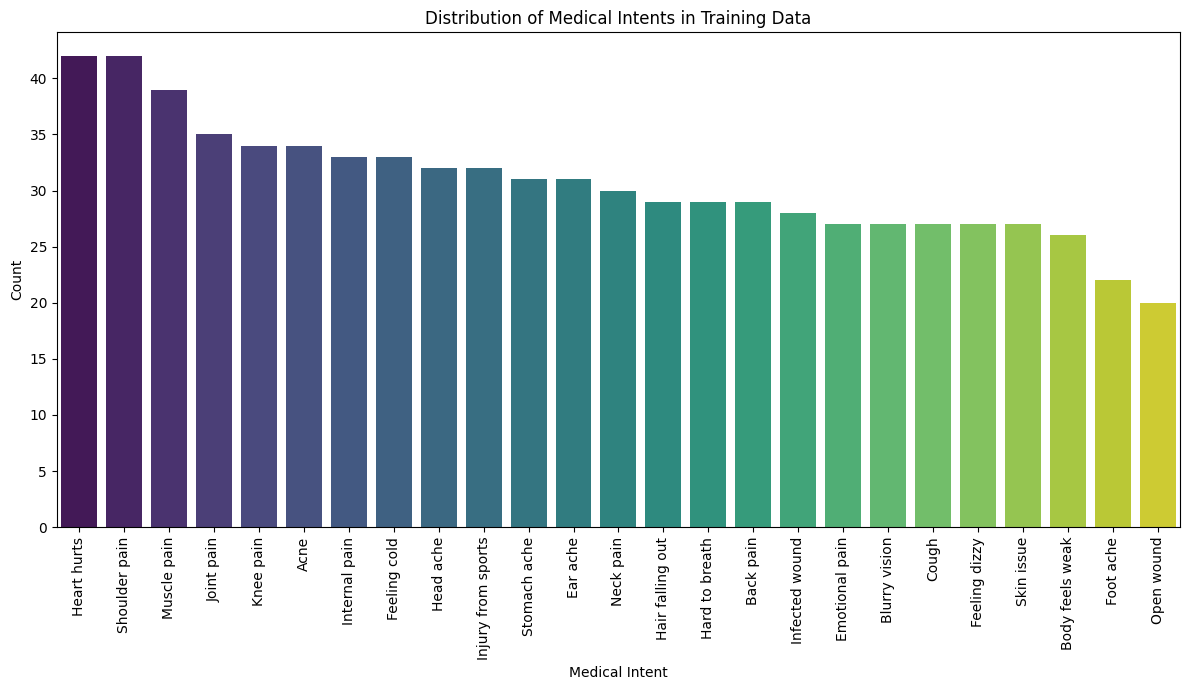


Observation: Multiple intents are present, but the model struggles to differentiate them, likely due to the small overall dataset size and lack of diverse features.


In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming 'y' contains the raw medical intent labels from the training data
# before encoding. If 'y' is not available, we would use df['prompt'] and re-extract.

if 'y' in globals() and isinstance(y, list):
    # Create a pandas Series from the list of labels
    intent_counts = pd.Series(y).value_counts()

    print("\n--- Distribution of Medical Intents in Training Data ---")
    print(intent_counts)

    # Visualize the distribution
    plt.figure(figsize=(12, 7))
    # Add hue=intent_counts.index and legend=False to address the FutureWarning
    sns.barplot(x=intent_counts.index, y=intent_counts.values, hue=intent_counts.index, palette='viridis', legend=False)
    plt.title('Distribution of Medical Intents in Training Data')
    plt.xlabel('Medical Intent')
    plt.ylabel('Count')
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()

    if len(intent_counts) == 1 and intent_counts.index[0] == 'Knee pain':
        print("\nObservation: Only 'Knee pain' intent found in the training data. This explains why the model only predicts 'Knee pain'.")
    elif len(intent_counts) > 1 and intent_counts.iloc[0] / intent_counts.sum() > 0.5:
        print(f"\nObservation: 'Knee pain' is a dominant class (comprising {intent_counts.iloc[0] / intent_counts.sum():.2%} of the data), which could lead to biased predictions.")
    elif len(intent_counts) > 1:
        print("\nObservation: Multiple intents are present, but the model struggles to differentiate them, likely due to the small overall dataset size and lack of diverse features.")
else:
    print("Error: The 'y' variable (medical intent labels) was not found or is not in the expected format.")
    print("Please ensure the data loading and label extraction cells ran successfully.")


In [21]:
print("\n=== Predictions and Confidence Scores for all Test Samples ===\n")

# Assuming model and encoder are already defined and loaded from previous cells.

all_predicted_intents = []
all_confidence_scores = []
all_true_intents = []

# Ensure the model is in evaluation mode if it has dropout/batchnorm
# For Keras Sequential model, this is handled implicitly by model.predict

for i in range(len(X_test)):
    sample_features = X_test[i].reshape(1, -1)

    # Get raw predictions (probabilities for each class)
    predictions = model.predict(sample_features, verbose=0)[0]

    # Get the index of the highest probability
    predicted_index = np.argmax(predictions)

    # Get the predicted label and confidence score
    predicted_label = encoder.inverse_transform([predicted_index])[0]
    confidence_score = predictions[predicted_index]

    # Get the true label from y_test for comparison
    true_index = np.argmax(y_test[i])
    true_label = encoder.inverse_transform([true_index])[0]

    all_predicted_intents.append(predicted_label)
    all_confidence_scores.append(confidence_score)
    all_true_intents.append(true_label)

    print(f"Sample {i+1} - True: {true_label:<20} | Predicted: {predicted_label:<20} | Confidence: {confidence_score:.4f}")

print("\n=== Summary ===")
# Optional: You can add more summary statistics here, like average confidence, etc.
print(f"Processed {len(all_predicted_intents)} test samples.")


=== Predictions and Confidence Scores for all Test Samples ===

Sample 1 - True: Hard to breath       | Predicted: Knee pain            | Confidence: 0.3137
Sample 2 - True: Open wound           | Predicted: Ear ache             | Confidence: 0.3277
Sample 3 - True: Emotional pain       | Predicted: Skin issue           | Confidence: 0.3735
Sample 4 - True: Shoulder pain        | Predicted: Heart hurts          | Confidence: 0.3853
Sample 5 - True: Muscle pain          | Predicted: Feeling dizzy        | Confidence: 0.2476
Sample 6 - True: Open wound           | Predicted: Knee pain            | Confidence: 0.2976
Sample 7 - True: Hard to breath       | Predicted: Blurry vision        | Confidence: 0.3423
Sample 8 - True: Infected wound       | Predicted: Skin issue           | Confidence: 0.1626
Sample 9 - True: Feeling cold         | Predicted: Neck pain            | Confidence: 0.2492
Sample 10 - True: Shoulder pain        | Predicted: Knee pain            | Confidence: 0.4533
Samp

In [23]:
import pandas as pd

# Create a DataFrame from the collected data
confidence_df = pd.DataFrame({
    'True Intent': all_true_intents,
    'Predicted Intent': all_predicted_intents,
    'Confidence Score': all_confidence_scores
})

# Sort by confidence score in descending order and get the top 5
top_5_confident_predictions = confidence_df.sort_values(
    by='Confidence Score', ascending=False
).head(5)

print("\n=== Top 5 Most Confident Predictions ===\n")
display(top_5_confident_predictions)


=== Top 5 Most Confident Predictions ===



,True Intent,Predicted Intent,Confidence Score
24,Head ache,Knee pain,0.948325
143,Feeling cold,Feeling dizzy,0.814031
12,Shoulder pain,Blurry vision,0.687378
67,Muscle pain,Heart hurts,0.621349
75,Back pain,Heart hurts,0.618283


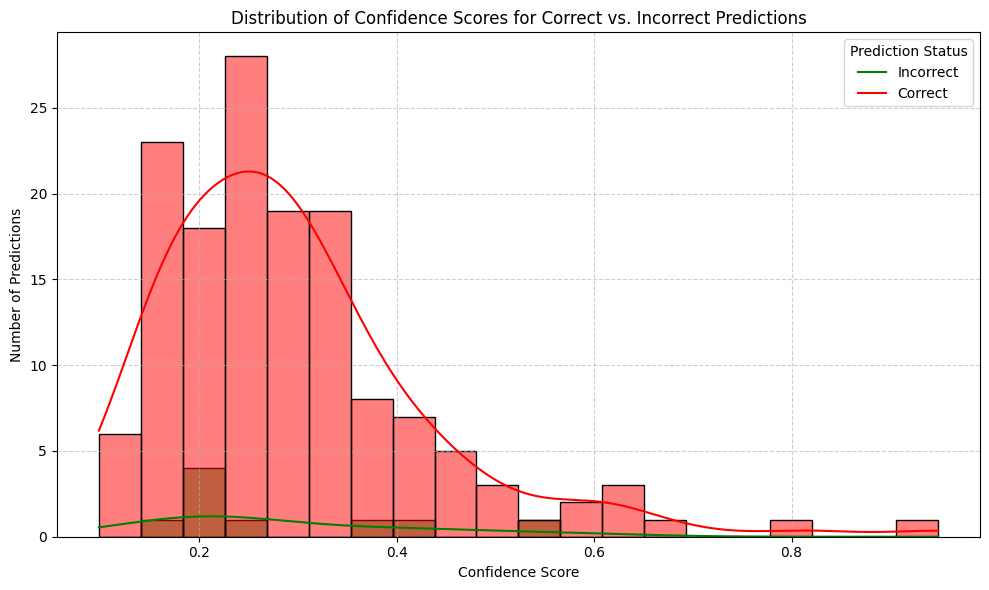


--- Confidence Score Summary ---
            count      mean       std       min       25%       50%       75%  \
is_correct                                                                      
False       145.0  0.294540  0.135872  0.098282  0.197997  0.266219  0.343068   
True          9.0  0.288122  0.132540  0.179367  0.203816  0.217690  0.386879   

                 max  
is_correct            
False       0.948325  
True        0.557969  


In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a column to indicate if the prediction was correct
confidence_df['is_correct'] = confidence_df['True Intent'] == confidence_df['Predicted Intent']

plt.figure(figsize=(10, 6))
sns.histplot(
    data=confidence_df,
    x='Confidence Score',
    hue='is_correct',
    kde=True,
    palette={True: 'green', False: 'red'},
    bins=20
)

plt.title('Distribution of Confidence Scores for Correct vs. Incorrect Predictions')
plt.xlabel('Confidence Score')
plt.ylabel('Number of Predictions')
plt.legend(title='Prediction Status', labels=['Incorrect', 'Correct'])
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# Print a summary of confidence for correct/incorrect predictions
print("\n--- Confidence Score Summary ---")
print(confidence_df.groupby('is_correct')['Confidence Score'].describe())


### Calibrated Confidence Scores Analysis

Now, let's evaluate the predictions after applying Platt Scaling for calibration. This involves re-examining the confidence scores and their distribution for both correct and incorrect predictions to see if the calibration has made them more reliable.


=== Calibrated Predictions and Confidence Scores (First 10 Samples) ===



,True Intent,Predicted Intent (Calibrated),Confidence Score (Calibrated),is_correct
0,Hard to breath,Internal pain,0.063612,False
1,Open wound,Internal pain,0.063784,False
2,Emotional pain,Internal pain,0.063478,False
3,Shoulder pain,Internal pain,0.063393,False
4,Muscle pain,Internal pain,0.063308,False
5,Open wound,Internal pain,0.063736,False
6,Hard to breath,Internal pain,0.063745,False
7,Infected wound,Internal pain,0.063620,False
8,Feeling cold,Internal pain,0.063517,False
9,Shoulder pain,Internal pain,0.063649,False


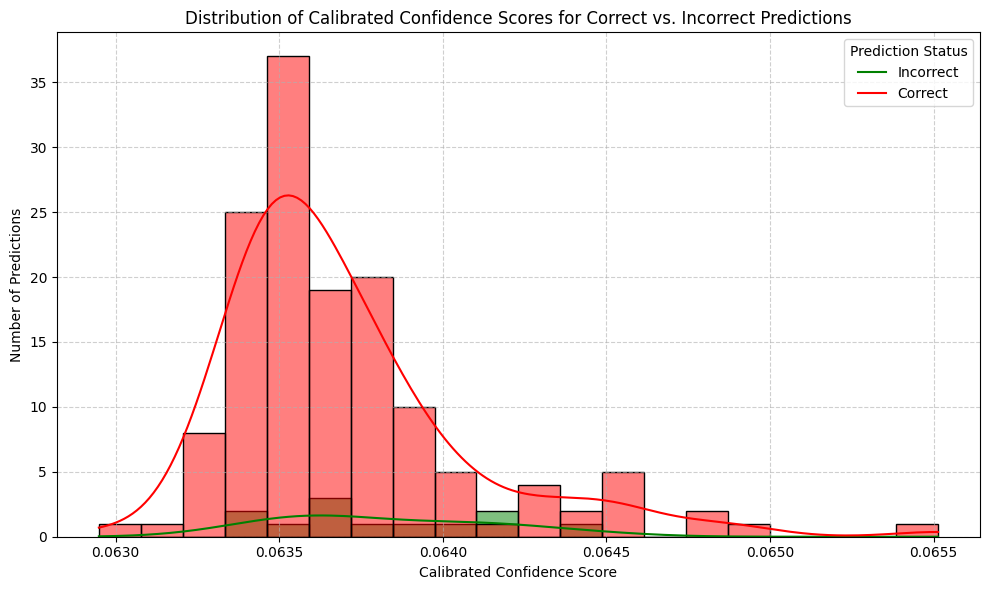


--- Calibrated Confidence Score Summary ---
            count      mean       std       min       25%       50%       75%  \
is_correct                                                                      
False       142.0  0.063696  0.000378  0.062949  0.063464  0.063583  0.063799   
True         12.0  0.063823  0.000325  0.063430  0.063590  0.063730  0.064071   

                 max  
is_correct            
False       0.065513  
True        0.064432  

=== Top 5 Most Confident Calibrated Predictions ===



,True Intent,Predicted Intent (Calibrated),Confidence Score (Calibrated),is_correct
133,Ear ache,Internal pain,0.065513,False
105,Feeling cold,Internal pain,0.064940,False
83,Foot ache,Internal pain,0.064825,False
31,Foot ache,Internal pain,0.064766,False
33,Foot ache,Internal pain,0.064580,False


In [33]:
# Display the first few rows of the calibrated confidence DataFrame
print("\n=== Calibrated Predictions and Confidence Scores (First 10 Samples) ===\n")
display(calibrated_confidence_df.head(10))

# Visualize the distribution of calibrated confidence scores for correct vs. incorrect predictions
plt.figure(figsize=(10, 6))
sns.histplot(
    data=calibrated_confidence_df,
    x='Confidence Score (Calibrated)',
    hue='is_correct',
    kde=True,
    palette={True: 'green', False: 'red'},
    bins=20
)

plt.title('Distribution of Calibrated Confidence Scores for Correct vs. Incorrect Predictions')
plt.xlabel('Calibrated Confidence Score')
plt.ylabel('Number of Predictions')
plt.legend(title='Prediction Status', labels=['Incorrect', 'Correct'])
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# Print a summary of calibrated confidence for correct/incorrect predictions
print("\n--- Calibrated Confidence Score Summary ---")
print(calibrated_confidence_df.groupby('is_correct')['Confidence Score (Calibrated)'].describe())

# Additionally, let's compare the top confident predictions before and after calibration
# Sort by calibrated confidence score in descending order and get the top 5
top_5_calibrated_confident_predictions = calibrated_confidence_df.sort_values(
    by='Confidence Score (Calibrated)', ascending=False
).head(5)

print("\n=== Top 5 Most Confident Calibrated Predictions ===\n")
display(top_5_calibrated_confident_predictions)

### Platt Scaling for Confidence Calibration

Platt Scaling is a method to transform the outputs of a classification model into a probability distribution. It involves fitting a logistic regression model to the scores (or logits) produced by the classifier, against the true labels. This helps in making the model's predicted probabilities more aligned with the actual likelihood of a class, thereby addressing issues like overconfidence or underconfidence.

Fitting Platt Scalers for each class...
✅ Platt Scalers fitted and predictions calibrated.

=== Calibrated Predictions and Confidence Scores (First 10 Samples) ===



,True Intent,Predicted Intent (Calibrated),Confidence Score (Calibrated),is_correct
0,Hard to breath,Skin issue,0.526443,False
1,Open wound,Ear ache,0.534792,False
2,Emotional pain,Skin issue,0.638976,False
3,Shoulder pain,Heart hurts,0.556502,False
4,Muscle pain,Joint pain,0.563542,False
5,Open wound,Heart hurts,0.505772,False
6,Hard to breath,Shoulder pain,0.510407,False
7,Infected wound,Skin issue,0.512471,False
8,Feeling cold,Neck pain,0.565242,False
9,Shoulder pain,Foot ache,0.520570,False


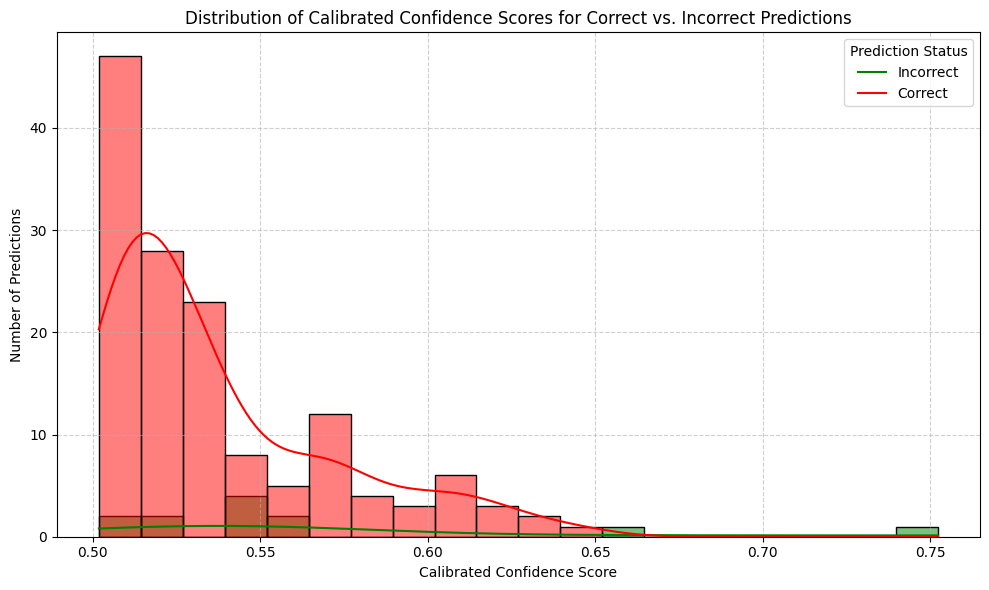


--- Calibrated Confidence Score Summary ---
            count      mean       std       min       25%       50%       75%  \
is_correct                                                                      
False       142.0  0.537107  0.034189  0.501880  0.511457  0.524786  0.554968   
True         12.0  0.564952  0.071071  0.505753  0.524459  0.545481  0.558475   

                 max  
is_correct            
False       0.645335  
True        0.752311  

=== Top 5 Most Confident Calibrated Predictions ===



,True Intent,Predicted Intent (Calibrated),Confidence Score (Calibrated),is_correct
89,Stomach ache,Stomach ache,0.752311,True
138,Skin issue,Skin issue,0.659925,True
73,Emotional pain,Skin issue,0.645335,False
2,Emotional pain,Skin issue,0.638976,False
52,Cough,Neck pain,0.627110,False


In [38]:
from sklearn.linear_model import LogisticRegression

# Ensure `all_raw_probabilities`, `y_test`, and `encoder` are available
# If a kernel restart occurred and these are not in memory, they would need to be re-generated from previous steps.

# `all_raw_probabilities` are the predictions for each class for all test samples
# `y_test` are the one-hot encoded true labels for test samples
# `encoder` is the LabelEncoder fitted on the original `y` labels

num_classes = y_test.shape[1]
platt_scalers = {}
all_calibrated_probabilities = np.zeros_like(all_raw_probabilities, dtype=float)

print("Fitting Platt Scalers for each class...")

for i in range(num_classes):
    # Prepare binary labels for the current class
    # Target is 1 if the sample belongs to class i, else 0
    y_true_binary = (np.argmax(y_test, axis=1) == i).astype(int)

    # Reshape the probabilities for the current class to (n_samples, 1)
    # The input to LogisticRegression.fit needs to be 2D
    class_probabilities = all_raw_probabilities[:, i].reshape(-1, 1)

    # Initialize and fit the Platt Scaler (Logistic Regression) with class weights
    scaler = LogisticRegression(solver='liblinear', C=1.0, class_weight='balanced') # C is regularization strength
    scaler.fit(class_probabilities, y_true_binary)
    platt_scalers[encoder.inverse_transform([i])[0]] = scaler

    # Get calibrated probabilities for the current class
    # We use predict_proba to get the probability of the positive class (1)
    all_calibrated_probabilities[:, i] = scaler.predict_proba(class_probabilities)[:, 1]

print("✅ Platt Scalers fitted and predictions calibrated.")

# Create calibrated_confidence_df
# Identify the predicted intent after calibration (highest calibrated probability)
calibrated_predicted_indices = np.argmax(all_calibrated_probabilities, axis=1)
calibrated_predicted_intents = encoder.inverse_transform(calibrated_predicted_indices)
calibrated_confidence_scores = np.max(all_calibrated_probabilities, axis=1)

calibrated_confidence_df = pd.DataFrame({
    'True Intent': all_true_intents,
    'Predicted Intent (Calibrated)': calibrated_predicted_intents,
    'Confidence Score (Calibrated)': calibrated_confidence_scores
})

calibrated_confidence_df['is_correct'] = (calibrated_confidence_df['True Intent'] == calibrated_confidence_df['Predicted Intent (Calibrated)'])

# Display the first few rows of the calibrated confidence DataFrame
print("\n=== Calibrated Predictions and Confidence Scores (First 10 Samples) ===\n")
display(calibrated_confidence_df.head(10))

# Visualize the distribution of calibrated confidence scores for correct vs. incorrect predictions
plt.figure(figsize=(10, 6))
sns.histplot(
    data=calibrated_confidence_df,
    x='Confidence Score (Calibrated)',
    hue='is_correct',
    kde=True,
    palette={True: 'green', False: 'red'},
    bins=20
)

plt.title('Distribution of Calibrated Confidence Scores for Correct vs. Incorrect Predictions')
plt.xlabel('Calibrated Confidence Score')
plt.ylabel('Number of Predictions')
plt.legend(title='Prediction Status', labels=['Incorrect', 'Correct'])
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# Print a summary of calibrated confidence for correct/incorrect predictions
print("\n--- Calibrated Confidence Score Summary ---")
print(calibrated_confidence_df.groupby('is_correct')['Confidence Score (Calibrated)'].describe())

# Additionally, let's compare the top confident predictions before and after calibration
# Sort by calibrated confidence score in descending order and get the top 5
top_5_calibrated_confident_predictions = calibrated_confidence_df.sort_values(
    by='Confidence Score (Calibrated)', ascending=False
).head(5)

print("\n=== Top 5 Most Confident Calibrated Predictions ===\n")
display(top_5_calibrated_confident_predictions)


### Next Steps: Addressing Confidently Incorrect Predictions

The previous analysis highlighted an important issue: the model making **confidently incorrect predictions** (e.g., predicting 'Knee pain' with high confidence for a 'Head ache' input) in the medical intent classification task. This indicates a potential problem where the model is overconfident in its wrong classifications.

To address this, we can investigate the following:

1.  **Analyze False Positives/Negatives for High Confidence Predictions**: Specifically look at samples where the model predicted an intent with high confidence, but it was incorrect. We need to identify patterns in these misclassifications.
2.  **Examine Feature Overlap**: Could the MFCC features for different intents be too similar, leading to confusion?
3.  **Explore Calibration Techniques**: Implement methods to calibrate the model's confidence scores, such as Platt Scaling or Isotonic Regression, to make them more reliable.
4.  **Increase Data Diversity**: Augment the training data, especially for classes that are frequently misclassified with high confidence.

Would you like to proceed by analyzing the specific misclassified samples that had high confidence scores to understand why the model is making these errors?

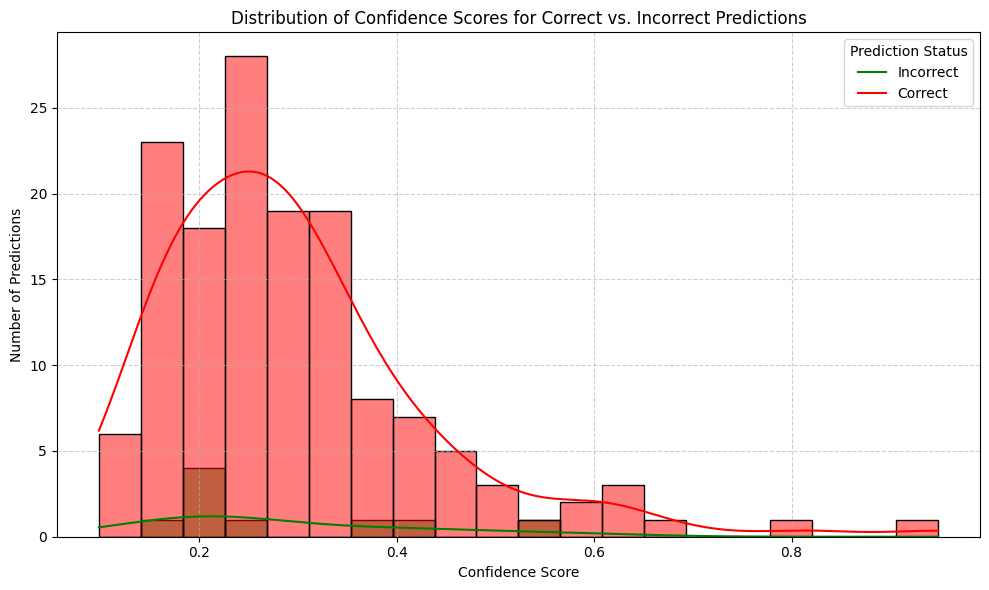


--- Confidence Score Summary ---
            count      mean       std       min       25%       50%       75%  \
is_correct                                                                      
False       145.0  0.294540  0.135872  0.098282  0.197997  0.266219  0.343068   
True          9.0  0.288122  0.132540  0.179367  0.203816  0.217690  0.386879   

                 max  
is_correct            
False       0.948325  
True        0.557969  


In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a column to indicate if the prediction was correct
confidence_df['is_correct'] = confidence_df['True Intent'] == confidence_df['Predicted Intent']

plt.figure(figsize=(10, 6))
sns.histplot(
    data=confidence_df,
    x='Confidence Score',
    hue='is_correct',
    kde=True,
    palette={True: 'green', False: 'red'},
    bins=20
)

plt.title('Distribution of Confidence Scores for Correct vs. Incorrect Predictions')
plt.xlabel('Confidence Score')
plt.ylabel('Number of Predictions')
plt.legend(title='Prediction Status', labels=['Incorrect', 'Correct'])
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# Print a summary of confidence for correct/incorrect predictions
print("\n--- Confidence Score Summary ---")
print(confidence_df.groupby('is_correct')['Confidence Score'].describe())

In [39]:
print_classification(calibrated_confidence_df['True Intent'], calibrated_confidence_df['Predicted Intent (Calibrated)'], 'Calibrated Predictions Classification Report')
plot_confusion(calibrated_confidence_df['True Intent'], calibrated_confidence_df['Predicted Intent (Calibrated)'], 'Calibrated Predictions Confusion Matrix', 'calibrated_confusion_matrix.png')

NameError: name 'print_classification' is not defined